# Etapa 2 

### EDA: Análisis exploratorio desde la capa bronze

Lee las tablas de `s3a://olist/bronze/`.

## 1. SparkSession

In [1]:
import os
from pyspark.sql import SparkSession
import pyspark.sql.functions as F

RUSTFS_ENDPOINT = os.environ.get('RUSTFS_ENDPOINT', 'http://rustfs:9000')
S3_KEY  = os.environ.get('AWS_ACCESS_KEY_ID',     'rustfsadmin')
S3_SEC  = os.environ.get('AWS_SECRET_ACCESS_KEY', 'rustfsadmin123')

JARS = ','.join([
    '/opt/spark/extra-jars/iceberg-spark-runtime-4.1_2.13-1.11.0.jar',
    '/opt/spark/extra-jars/hadoop-aws-3.4.2.jar',
    '/opt/spark/extra-jars/aws-sdk-bundle-v2-2.29.52.jar',
])

spark = (
    SparkSession.builder
    .appName('etapa2-eda')
    .master('local[*]')
    .config('spark.jars', JARS)
    .config('spark.hadoop.fs.s3a.impl',                   'org.apache.hadoop.fs.s3a.S3AFileSystem')
    .config('spark.hadoop.fs.s3a.endpoint',               RUSTFS_ENDPOINT)
    .config('spark.hadoop.fs.s3a.access.key',             S3_KEY)
    .config('spark.hadoop.fs.s3a.secret.key',             S3_SEC)
    .config('spark.hadoop.fs.s3a.path.style.access',      'true')
    .config('spark.hadoop.fs.s3a.connection.ssl.enabled', 'false')
    .getOrCreate()
)
spark.sparkContext.setLogLevel('ERROR')
print(f'Spark {spark.version} — master: {spark.sparkContext.master}')
print(f'RustFS: {RUSTFS_ENDPOINT}')

26/10/15 18:28:03 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.1.3 — master: local[*]
RustFS: http://rustfs:9000


In [2]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import math


bins = {}
def plot_distribution(df, 
                      cols: str, 
                      n_cols: int = 6, 
                      hist: bool = True, 
                      show_boxplot: bool = True, 
                      bins_dict: dict = {}) -> None:
    """
    hist: True -> histogramas + boxplots (numéricas)
          False -> barplots (categóricas)
    show_boxplot: si es True, agrega boxplot al lado del histograma
    """
    
    if hist and show_boxplot:
        # Cada variable numérica ocupa 2 columnas: hist + boxplot
        # n_cols debe ser par para que quede parejo
        cols_per_var = 2
        n_cols_effective = n_cols if n_cols % 2 == 0 else n_cols + 1
    else:
        cols_per_var = 1
        n_cols_effective = n_cols

    n_rows = math.ceil((len(cols) * cols_per_var) / n_cols_effective)
    
    # Títulos de subplots: uno por cada subplot real
    subplot_titles = []
    for c in cols:
        if hist and show_boxplot:
            subplot_titles.extend([c, f"{c} (boxplot)"])
        else:
            subplot_titles.append(c)

    fig = make_subplots(
        rows=n_rows,
        cols=n_cols_effective,
        subplot_titles=subplot_titles,
        horizontal_spacing=0.05,
        vertical_spacing=0.08
    )

    type_col = "Numerical" if hist else "Categorical"

    for index, col_name in enumerate(cols):
        if hist and show_boxplot:
            # Posición base: 2 columnas por variable
            base_pos = index * 2
            row = (base_pos // n_cols_effective) + 1
            col = (base_pos % n_cols_effective) + 1
            col_box = col + 1
            row_box = row

            # Histograma
            bins = bins_dict.get(col_name,None) 
            kwargs =  {}
            if bins is not None:
                kwargs["bins"] = bins_dict[col_name]
               
            hist_temp = df.dropna(subset=[col_name]).plot.hist(column=col_name, 
                                     opacity=0.9, 
                                     **kwargs, 
                                    )
            for trace in hist_temp.data:
                trace.legendgroup = trace.name
                if index > 0:
                    trace.showlegend = False
                fig.add_trace(trace, row=row, col=col)

            # Boxplot
            box_fig = df.plot.box(column=col_name)
            for trace in box_fig.data:
                trace.legendgroup = f"box_{col_name}"
                trace.showlegend = False
                fig.add_trace(trace, row=row_box, col=col_box)

        else:
            row = (index // n_cols_effective) + 1
            col = (index % n_cols_effective) + 1

            if hist:
                hist_temp = df.plot.hist(column=col_name, opacity=0.9)
            else:
                hist_temp = df.groupby(col_name).count().plot(
                    kind="bar", x=col_name, y='count', opacity=0.9
                )

            for trace in hist_temp.data:
                trace.legendgroup = trace.name
                if index > 0:
                    trace.showlegend = False
                fig.add_trace(trace, row=row, col=col)

    fig.update_layout(
        height=400 * n_rows,
        width=1500,
        title_text=f"{type_col} Columns",
        title_x=0.5,
        bargap=0.1
    )
    fig.show()

## 2. Cargar tablas bronze

In [3]:
BRONZE_BASE = 's3a://olist/bronze'

TABLAS = [
    'orders',
    'order_items',
    'order_payments',
    'order_reviews',
    'customers',
    'sellers',
    'products',
    'category_translation',
    'geo_cep',
    'geolocation',
]

dfs = {t: spark.read.parquet(f'{BRONZE_BASE}/{t}') for t in TABLAS}

print("{:<30} {:>10}  {}".format('Tabla', 'Filas', 'Columnas'))
print('-' * 65)
for nombre, df in dfs.items():
    cols = ', '.join(df.columns)
    print("{:<30} {:>10}  {}".format(nombre, df.count(), cols))

SLF4J: Failed to load class "org.slf4j.impl.StaticLoggerBinder".
SLF4J: Defaulting to no-operation (NOP) logger implementation
SLF4J: See http://www.slf4j.org/codes.html#StaticLoggerBinder for further details.


Tabla                               Filas  Columnas
-----------------------------------------------------------------


orders                              99441  order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date
order_items                        112650  order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value


order_payments                     103886  order_id, payment_sequential, payment_type, payment_installments, payment_value
order_reviews                       99224  review_id, order_id, review_score, review_comment_title, review_comment_message, review_creation_date, review_answer_timestamp


customers                           99441  customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state
sellers                              3095  seller_id, seller_zip_code_prefix, seller_city, seller_state


products                            32951  product_id, product_category_name, product_name_length, product_description_length, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm
category_translation                   71  product_category_name, product_category_name_english


geo_cep                             19015  zip_prefix, lat, lng, city, state
geolocation                       1000163  geolocation_id, geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city, geolocation_state


# Descripcion de los datos 

# Ordenes

In [4]:
orders =  dfs.get("orders")
orders.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)



In [5]:
orders.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in orders.columns]).show()

+--------+-----------+------------+------------------------+-----------------+----------------------------+-----------------------------+-----------------------------+
|order_id|customer_id|order_status|order_purchase_timestamp|order_approved_at|order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------+-----------+------------+------------------------+-----------------+----------------------------+-----------------------------+-----------------------------+
|       0|          0|           0|                       0|              160|                        1783|                         2965|                            0|
+--------+-----------+------------+------------------------+-----------------+----------------------------+-----------------------------+-----------------------------+



### Tabla ordenes:

* Granularidad: cada fila representa una orden

### Interpretación de columnas:
  
* order_status: **estado actual**:

    *  created: El cliente realizó el pedido, pero el pago no se confirmo (pasarela de pago)
    *  approved: el pago se ha verificado y aprobado correctamente    
    *  invoiced: El vendedor ha emitido la factura fiscal (nota fiscal, obligatoria en Brasil) para el pedido.
    *  processing: El vendedor está preparando el paquete, embalando el producto y coordinando con la empresa de logística
    *  shipped: El paquete ha sido entregado a la empresa de transporte (Correios o transportistas privados) y está en camino.
    *  delivered:  El producto ha sido recibido con éxito por el cliente final.
    *  canceled: El pedido fue anulado. Esto puede ocurrir en casi cualquier etapa (si el pago es rechazado al inicio, si el cliente se arrepiente antes del envío, o si hay un problema crítico en la entrega)
    *  unavailable: El pedido fue aprobado, pero no se pudo completar debido a un problema con el inventario (falta de stock)
####

* order_purchase_timestamp: Momento en que el cliente hizo el pedido
* order_approved_at_: Aprobación del pago
* order_delivered_carrier_date: cuando llego trasportista

### entrega tardia (retraso) 

* order_delivered_customer_date: **fecha de entrega real**
* order_estimated_delivery_date: **Fecha acordada con el cliente**
    * tardio: order_delivered_customer_date - order_estimated_delivery_date > 0



In [6]:
orders.select(F.col("order_status")).distinct().show()

+------------+
|order_status|
+------------+
|     shipped|
|    canceled|
|    approved|
|    invoiced|
|     created|
|   delivered|
| unavailable|
|  processing|
+------------+



In [7]:
cols = ["order_purchase_timestamp", 
        "order_approved_at",
        "order_delivered_carrier_date", 
        "order_delivered_customer_date", 
        "order_estimated_delivery_date"]
_filter = F.col("order_status") == "canceled"
orders.where(_filter).select(cols).show(truncate=False)

+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|2018-08-04 14:29:27     |2018-08-07 04:10:26|NULL                        |NULL                         |2018-08-14 00:00:00          |
|2018-01-26 21:34:08     |2018-01-26 21:58:39|2018-01-29 22:33:25         |NULL                         |2018-02-22 00:00:00          |
|2018-01-25 13:34:24     |2018-01-25 13:50:20|2018-01-26 21:42:18         |NULL                         |2018-02-23 00:00:00          |
|2018-08-28 15:26:39     |NULL               |NULL                        |NULL                         |2018-09-12 00:00:00          |
|2018-09-20 13:54:16     |NULL               |NU

In [8]:
orders.groupby("order_status").count().show()

+------------+-----+
|order_status|count|
+------------+-----+
|     shipped| 1107|
|    canceled|  625|
|    approved|    2|
|    invoiced|  314|
|     created|    5|
|   delivered|96478|
| unavailable|  609|
|  processing|  301|
+------------+-----+



In [9]:
(orders.groupby("order_status")
     .count()
     .plot
     .bar(x="order_status", 
          y="count", 
          title="Orden status Distribution")
)

## Distribucion de estado de ordenes

la mayoria de las ordenes han sido  entregadas:   **delivered: 96478**


In [10]:
orders.select(F.approx_count_distinct("order_id").alias("num_orders")).show()

+----------+
|num_orders|
+----------+
|     99770|
+----------+



In [11]:
columns  = ["order_purchase_timestamp",
     "order_approved_at",
     "order_delivered_carrier_date", 
     "order_delivered_customer_date", 
     "order_estimated_delivery_date"]

cond =  F.col("order_status") == "delivered"
for c in columns:
    cond2 =  F.isnull(F.col(c))
    num = orders.where(cond & cond2).distinct().count()
    print(f"Columna {c}, Nulls {num}")

Columna order_purchase_timestamp, Nulls 0


Columna order_approved_at, Nulls 14


Columna order_delivered_carrier_date, Nulls 2


Columna order_delivered_customer_date, Nulls 8


Columna order_estimated_delivery_date, Nulls 0


# inconsistencias de ordenes: delivered 

El estado cambia a delivered cuando la empresa de correos o la transportadora marca el paquete como *entregado* en su propio sistema de rastreo.

1. El caso de order_approved_at
2. El caso de order_delivered_customer_date = Nulo
3. 

### acciones 
1. Eliminación Directa: Si tu objetivo es calcular métricas de tiempo precisas (como el tiempo de envío o retrasos logísticos), elimina estas filas específicas (.dropna()). Mantenerlas te generará errores o valores negativos al restar fechas.
2. Imputación (Solo para order_approved_at): Si no quieres perder el historial de compra, puedes rellenar order_approved_at igualándolo al valor de order_purchase_timestamp


In [12]:
# de las que fueron entregadas y ver cualtos tiene 
# order_delivered_carrier_date 1783
# order_delivered_customer_date 2965
orders.filter(F.isnull(F.col("order_delivered_customer_date"))).groupby("order_status").count().show()

+------------+-----+
|order_status|count|
+------------+-----+
|     shipped| 1107|
|    canceled|  619|
|    approved|    2|
|    invoiced|  314|
|     created|    5|
|   delivered|    8|
| unavailable|  609|
|  processing|  301|
+------------+-----+



# order_items


In [13]:
order_items =  dfs.get("order_items")
order_items.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- order_item_id: short (nullable = true)
 |-- product_id: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- shipping_limit_date: timestamp (nullable = true)
 |-- price: decimal(10,2) (nullable = true)
 |-- freight_value: decimal(10,2) (nullable = true)



In [14]:
order_items =  ( order_items.withColumn("price", F.col("price").cast("double"))
                .withColumn("freight_value", F.col("freight_value").cast("double"))
               )

In [15]:
order_items.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- order_item_id: short (nullable = true)
 |-- product_id: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- shipping_limit_date: timestamp (nullable = true)
 |-- price: double (nullable = true)
 |-- freight_value: double (nullable = true)



In [16]:
order_items.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in order_items.columns]).show()

+--------+-------------+----------+---------+-------------------+-----+-------------+
|order_id|order_item_id|product_id|seller_id|shipping_limit_date|price|freight_value|
+--------+-------------+----------+---------+-------------------+-----+-------------+
|       0|            0|         0|        0|                  0|    0|            0|
+--------+-------------+----------+---------+-------------------+-----+-------------+



# Descripcion
Granularidad: un articulo de una orden 

* shipping_limit_date: el tiempo que pone el marketplace al proveddor para que despache
* freight_value: el  valor del flete

Ver si  hay ordenes que no tiene asociados productos (items) y eliminar o filtrar estas filas, 
ya que una orden sin order_items no tiene un valor monetario (price) ni de envío (freight_value)

In [17]:
_filter = ~F.col("order_id").isin(order_items.select("order_id").distinct())
orders.where(_filter).select("order_id").distinct().count()

775

In [18]:
order_items.where("order_id == 'c272bcd21c287498b4883c7512019702'").show()

+--------+-------------+----------+---------+-------------------+-----+-------------+
|order_id|order_item_id|product_id|seller_id|shipping_limit_date|price|freight_value|
+--------+-------------+----------+---------+-------------------+-----+-------------+
+--------+-------------+----------+---------+-------------------+-----+-------------+



In [19]:
(
    orders.where(_filter)
    .where("order_status == 'invoiced'")
).show(truncate=False)

+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|2ce9683175cdab7d1c95bcbb3e36f478|b2d7ae0415dbbca535b5f7b38056dd1f|invoiced    |2016-10-05 21:03:33     |2016-10-06 07:46:39|NULL                        |NULL                         |2016-11-25 00:00:00          |
|e04f1da1f48bf2bbffcf57b9824f76e1|0d00d77134cae4c58695086ad8d85100|invoiced    |2016-10-05 13:22:20     |2016-10-06 15:51:38|NULL           

De las **ordenes sin items**: es entendible canceled, unavailable y created, los demás deben ser errores, ejemplo: 
no podes tener invoce sin items. 

In [20]:
_filter = ~F.col("order_id").isin(orders.select("order_id").distinct())
order_items.where(_filter).select("order_id").distinct().count()

0

In [21]:
order_items.select(F.approx_count_distinct(F.col("order_id"))).show()

+-------------------------------+
|approx_count_distinct(order_id)|
+-------------------------------+
|                          99770|
+-------------------------------+



In [22]:
cols =  ["order_id", "product_id", "seller_id"]
for c in cols:
    print(f"{c}, {order_items.select(F.approx_count_distinct(F.col(c))).first()[0]}")

order_id, 99770


product_id, 32938


seller_id, 3080


In [23]:
fig = (order_items.groupby("order_id")
       .agg(F.count(F.col("*")).alias("num_items"))
       .groupby("num_items")
       .count()
       .plot.bar(x="num_items", y="count", title="Distribucion cantidad de items por Orden (Log)")
      )
fig.update_layout(yaxis_type="log", title_x=0.5)

In [24]:
import numpy  as np 
cols = ["price", "freight_value"]

price_bins   = np.geomspace(0.5, 7000, 30)
freight_bins = np.concatenate(([0], np.geomspace(0.5, 500, 25)))

plot_distribution(order_items, 
                  cols,hist=True, 
                  show_boxplot=True,
                  # bins_dict={"price": price_bins, "freight_value": freight_bins}
                 )

In [25]:
order_items[cols].summary().toPandas()

,summary,price,freight_value
0,count,112650,112650
1,mean,120.65373901477311,19.99031992898562
2,stddev,183.6339280502597,15.806405412296998
3,min,0.85,0.0
4,25%,39.9,13.08
5,50%,74.99,16.26
6,75%,134.9,21.15
7,max,6735.0,409.68


# Order Payment 

* **payment_sequential**: número de pago secuencial.  un cliente puede pagar un mismo pedido utilizando más de un método de pago
* **payment_type**: Es el método de pago utilizado por el cliente
* **payment_installments**: Es el número de cuotas o parcialidades en las que el cliente decidió financiar su compra (aplica casi exclusivamente a credit_card).
* **payment_value**: Es el monto total de dinero pagado en esa transacción específica (expresado en reales brasileños - BRL)

In [26]:
order_payments = dfs.get("order_payments")
order_payments.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- payment_sequential: short (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- payment_installments: short (nullable = true)
 |-- payment_value: decimal(10,2) (nullable = true)



In [27]:
order_payments = order_payments.withColumn("payment_value", F.col("payment_value").cast("double"))

In [28]:
fig = (order_payments.groupby("order_id").agg(F.count(F.col("order_id")).alias("payments"))
.groupby("payments").count()
).plot.bar(x="payments", y="count", title="Payment Method")
fig.update_layout(yaxis_type="log", title_x=0.5)

In [29]:
order_payments.groupby("payment_type")

GroupedData[grouping expressions: [payment_type], value: [order_id: string, payment_sequential: smallint ... 3 more fields], type: GroupBy]

In [30]:
fig = (order_payments.groupby("payment_type").count()
).plot.bar(x="payment_type", y="count", title="Payment Type")
fig.update_layout(title_x=0.5)

* **boleto**: Cuando  el  cliente va a pagar sl sistema genera un documento digital (un PDF) que contiene un código de barras, un número identificador y una fecha de vencimiento (generalmente de 2 a 3 días hábiles).
* **not defined**

In [31]:
order_payments.select("payment_installments").summary().show()

+-------+--------------------+
|summary|payment_installments|
+-------+--------------------+
|  count|              103886|
|   mean|   2.853348863176944|
| stddev|   2.687050673856486|
|    min|                   0|
|    25%|                   1|
|    50%|                   1|
|    75%|                   4|
|    max|                  24|
+-------+--------------------+



In [32]:
fig = ( order_payments
       .groupby("payment_installments")
       .agg(F.count(F.col("payment_installments")).alias("count"))
       .plot.bar(x="payment_installments", y="count", title="Distribucion de Metodos de pago")
      )
fig.update_layout(title_x=0.5)

# Order Reviews

In [33]:
order_reviews  = dfs.get("order_reviews")
order_reviews.printSchema()

root
 |-- review_id: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- review_score: short (nullable = true)
 |-- review_comment_title: string (nullable = true)
 |-- review_comment_message: string (nullable = true)
 |-- review_creation_date: timestamp (nullable = true)
 |-- review_answer_timestamp: timestamp (nullable = true)



In [34]:
order_reviews.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in order_reviews.columns]).show()

+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+
|review_id|order_id|review_score|review_comment_title|review_comment_message|review_creation_date|review_answer_timestamp|
+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+
|        0|       0|           0|               87656|                 58247|                   0|                      0|
+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+



In [35]:
order_reviews.select("order_id").distinct().count()

98673

In [36]:
# hay  reviews que no  estan  asociados a ninguna orden?
_filter = ~F.col("order_id").isin(orders.select("order_id").distinct())
order_reviews.where(_filter).select("order_id").distinct().count()

0

In [37]:
# hay ordenes sin review?
_filter = ~F.col("order_id").isin(order_reviews.select("order_id").distinct())
orders.where(_filter).select("order_id").distinct().count()

768

In [38]:
orders.where(_filter).select("*").distinct().show(truncate=False)

+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|d0bfc2beba8af659a7585f0f48efde83|9c3a67b63043d1626a51a23c256e0caa|delivered   |2017-10-05 09:50:42     |2017-10-05 10:04:52|2017-10-05 15:58:24         |2017-10-23 16:42:54          |2017-10-30 00:00:00          |
|2117b238b6ae0929164d1cf41f3ecb87|616328acb98ad1ecc08506ba227fe9d4|delivered   |2017-07-07 17:44:19     |2017-07-07 17:55:21|2017-07-10 21:2

In [39]:
_filter = F.col("order_id") == '2047712d309c37ea8b67d413cd8632e1'
order_reviews.where(_filter).show()

+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+
|review_id|order_id|review_score|review_comment_title|review_comment_message|review_creation_date|review_answer_timestamp|
+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+
+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+



# review_score


| score| descripcion| notas|
|------|------------|-------|
| 5 |Muy Bueno|	El producto llegó antes de tiempo, es de buena calidad y cumplió las expectativas.|
| 4	|Bueno|	La experiencia fue positiva general, aunque quizás el paquete tardó un poco o el producto tiene detalles menores.|
| 3	|Neutral / Regular|	Puede indicar retrasos leves o que el producto es aceptable pero no impresionante.|
| 2	|Malo |	Problemas. Generalmente asociado a retrasos medianos en la entrega o productos que no se parecen a la descripción.|
| 1	|Muy Malo| Suele significar que el producto nunca llegó, llegó roto, era un artículo completamente diferente, o el vendedor no respondió los mensajes.|

Malas serian 1,2

In [40]:
order_reviews.groupby("review_score").count().plot.bar(x="review_score", y="count", title="Distribucion de review score")

In [41]:
tardias =  [1,2]
_filter =  F.col("review_score").isin(tardias)
order_reviews.where(_filter).show()

+--------------------+--------------------+------------+--------------------+----------------------+--------------------+-----------------------+
|           review_id|            order_id|review_score|review_comment_title|review_comment_message|review_creation_date|review_answer_timestamp|
+--------------------+--------------------+------------+--------------------+----------------------+--------------------+-----------------------+
|15197aa66ff4d0650...|b18dcdf73be663668...|           1|                NULL|                  NULL| 2018-04-13 00:00:00|    2018-04-16 00:39:37|
|9314d6f9799f5bfba...|0dacf04c5ad59fd5a...|           2|                NULL|  GOSTARIA DE SABER...| 2018-01-18 00:00:00|    2018-01-20 21:25:45|
|373cbeecea8286a2b...|583174fbe37d3d5f0...|           1|Não chegou meu pr...|               Péssimo| 2018-08-15 00:00:00|    2018-08-15 04:10:37|
|2c5e27fc178bde7ac...|0ce9a24111d850192...|           1|                NULL|  Não gostei ! Comp...| 2017-12-13 00:00:00|   

In [42]:
print(f"Numero de ordenes con baja calificacion {order_reviews.where(_filter).select('order_id').distinct().count()}")

Numero de ordenes con baja calificacion 14533


In [43]:
# tenemos datos de todas las ordenes ? 
bad_scored = order_reviews.where(_filter).select("order_id").distinct()
filter_scored = F.col("order_id").isin(bad_scored)
orders.where(filter_scored).distinct().count()

14533

Todas las ordenes que tiene score bajo  existen en la tabla de ordenes 

# Productos

In [44]:
products = dfs.get("products")
products.printSchema()

root
 |-- product_id: string (nullable = true)
 |-- product_category_name: string (nullable = true)
 |-- product_name_length: integer (nullable = true)
 |-- product_description_length: integer (nullable = true)
 |-- product_photos_qty: short (nullable = true)
 |-- product_weight_g: integer (nullable = true)
 |-- product_length_cm: integer (nullable = true)
 |-- product_height_cm: integer (nullable = true)
 |-- product_width_cm: integer (nullable = true)



In [45]:
products.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in products.columns]).show()

+----------+---------------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+
|product_id|product_category_name|product_name_length|product_description_length|product_photos_qty|product_weight_g|product_length_cm|product_height_cm|product_width_cm|
+----------+---------------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+
|         0|                  610|                610|                       610|               610|               2|                2|                2|               2|
+----------+---------------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+



In [46]:
missing_category = products.where("product_category_name is null").select(["product_id"]).distinct()
_filter = F.col("product_id").isin(missing_category)
order_items.where(_filter).show()

+--------------------+-------------+--------------------+--------------------+-------------------+------+-------------+
|            order_id|order_item_id|          product_id|           seller_id|shipping_limit_date| price|freight_value|
+--------------------+-------------+--------------------+--------------------+-------------------+------+-------------+
|0046e1d57f4c07c8c...|            1|ff6caf9340512b8bf...|38e6dada03429a471...|2017-10-02 15:49:17|  7.79|         7.78|
|00482f26707872922...|            1|a9c404971d1a5b1cb...|702835e4b785b67a0...|2017-02-17 16:18:07|   7.6|        10.96|
|004f5d8f238e8908e...|            1|5a848e4ab52fd5445...|c826c40d7b19f62a0...|2018-03-06 09:29:25|122.99|        15.61|
|0057199db02d1a5ef...|            1|41eee23c25f7a574d...|e5a3438891c0bfdb9...|2018-01-25 09:07:51|  20.3|        16.79|
|006cb7cafc99b2954...|            1|e10758160da97891c...|323ce52b5b81df2cd...|2018-02-22 13:35:28|  56.0|        14.14|
|00e6786fee8f47683...|            1|76d1

### <span style="background-color:yellow"> Que hacemos con esos 610 productos que no tenemos descripcion/name/?</span>
 

# Preguntas Analíticas 
| ID | Pregunta | Tipo |
|---|---|---|
| **P1** | ¿Cuál es el nivel de cumplimiento del plazo y cómo varía por ruta, categoría, vendedor y período? | Descriptiva |
| **P2** | ¿Cómo impactan los retrasos en la entrega en la satisfacción del cliente? | Descriptiva |
| **P3** | ¿Cómo se distribuye el tiempo de entrega a lo largo del ciclo de vida del pedido (aprobación, despacho y tránsito), qué etapas concentran la demora y cómo varía ese patrón según la región, la categoría, el vendedor y el período? |Descriptiva |
| **P4** | ¿Qué características al momento de la compra predicen una entrega tardía? | Predictiva | 


In [47]:
# cumplimiento de plazo (>= 0) llego antes o cuando se esperaba, (< 0) llegó con retraso
# datediff sobre un nulo, el resultado será automáticamente null

df_orders = ( orders.withColumn("days_late", 
                    F.date_diff(F.col("order_estimated_delivery_date"), F.col("order_delivered_customer_date"))
                   )
            )

In [48]:
cols =  ["order_delivered_carrier_date","order_delivered_customer_date","order_estimated_delivery_date", "days_late","delayed"]
df_orders.withColumn(
    "delayed", 
    F.when(F.col("days_late").isNull(), None)
     .when(F.col("days_late") < 0, 1)
     .otherwise(0)).select(cols).show()


+----------------------------+-----------------------------+-----------------------------+---------+-------+
|order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|days_late|delayed|
+----------------------------+-----------------------------+-----------------------------+---------+-------+
|         2017-10-04 19:55:00|          2017-10-10 21:25:13|          2017-10-18 00:00:00|        8|      0|
|         2018-07-26 14:31:00|          2018-08-07 15:27:45|          2018-08-13 00:00:00|        6|      0|
|         2018-08-08 13:50:00|          2018-08-17 18:06:29|          2018-09-04 00:00:00|       18|      0|
|         2017-11-22 13:39:59|          2017-12-02 00:28:42|          2017-12-15 00:00:00|       13|      0|
|         2018-02-14 19:46:34|          2018-02-16 18:17:02|          2018-02-26 00:00:00|       10|      0|
|         2017-07-11 14:58:04|          2017-07-26 10:57:55|          2017-08-01 00:00:00|        6|      0|
|                  

In [49]:
df_orders = df_orders.withColumn(
    "delayed", 
    F.when(F.col("days_late").isNull(), None)
     .when(F.col("days_late") < 0, 1)
     .otherwise(0))

In [50]:
df_orders.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)
 |-- days_late: integer (nullable = true)
 |-- delayed: integer (nullable = true)



In [51]:
# rutas de los pedidos

In [52]:
#La transformación agrega raw.geolocation por prefijo postal con dos funciones de agregación:
# - lat, lng → mediana (percentile_cont(0.5)) de todas las coordenadas del prefijo ?  el centroide (la media) de todas las latitudes y longitudes de cada código postal?
#  city, state → moda (mode() WITHIN GROUP) — ciudad y estado más frecuentes
geo_cep = dfs.get("geo_cep")
geo_cep.printSchema()

root
 |-- zip_prefix: string (nullable = true)
 |-- lat: double (nullable = true)
 |-- lng: double (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)



In [53]:
sellers =  dfs.get("sellers")
customers = dfs.get("customers")
sellers.printSchema()

root
 |-- seller_id: string (nullable = true)
 |-- seller_zip_code_prefix: string (nullable = true)
 |-- seller_city: string (nullable = true)
 |-- seller_state: string (nullable = true)



In [54]:
customers =  dfs.get("customers")
customers.printSchema()

root
 |-- customer_id: string (nullable = true)
 |-- customer_unique_id: string (nullable = true)
 |-- customer_zip_code_prefix: string (nullable = true)
 |-- customer_city: string (nullable = true)
 |-- customer_state: string (nullable = true)



In [55]:
rutas_raw = order_items.join(orders, on="order_id", how="inner") \
                        .join(customers, on="customer_id", how="inner") \
                        .join(sellers, on="seller_id", how="inner")
rutas_raw.show()

+--------------------+--------------------+--------------------+-------------+--------------------+-------------------+------+-------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+--------------------+------------------------+--------------------+--------------+----------------------+--------------------+------------+
|           seller_id|         customer_id|            order_id|order_item_id|          product_id|shipping_limit_date| price|freight_value|order_status|order_purchase_timestamp|  order_approved_at|order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|  customer_unique_id|customer_zip_code_prefix|       customer_city|customer_state|seller_zip_code_prefix|         seller_city|seller_state|
+--------------------+--------------------+--------------------+-------------+--------------------+-------------------+------+-------------+------

In [56]:
origen  = rutas_raw.join(
    geo_cep.select(F.col("zip_prefix").alias("seller_zip"), 
                     F.col("lat").alias("seller_lat"), 
                     F.col("lng").alias("seller_lng")),
    rutas_raw.seller_zip_code_prefix == F.col("seller_zip"),
    how="inner"
) 
origen.show()

+--------------------+--------------------+--------------------+-------------+--------------------+-------------------+------+-------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+--------------------+------------------------+--------------------+--------------+----------------------+--------------------+------------+----------+-------------------+-------------------+
|           seller_id|         customer_id|            order_id|order_item_id|          product_id|shipping_limit_date| price|freight_value|order_status|order_purchase_timestamp|  order_approved_at|order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|  customer_unique_id|customer_zip_code_prefix|       customer_city|customer_state|seller_zip_code_prefix|         seller_city|seller_state|seller_zip|         seller_lat|         seller_lng|
+--------------------+--------------------+-

In [57]:
rutas_completas = origen.join(
    geo_cep.select(F.col("zip_prefix").alias("customer_zip"), 
                     F.col("lat").alias("customer_lat"), 
                     F.col("lng").alias("customer_lng")),
    origen.customer_zip_code_prefix == F.col("customer_zip"),
    how="inner"
)

In [58]:
rutas_completas

DataFrame[seller_id: string, customer_id: string, order_id: string, order_item_id: smallint, product_id: string, shipping_limit_date: timestamp, price: double, freight_value: double, order_status: string, order_purchase_timestamp: timestamp, order_approved_at: timestamp, order_delivered_carrier_date: timestamp, order_delivered_customer_date: timestamp, order_estimated_delivery_date: timestamp, customer_unique_id: string, customer_zip_code_prefix: string, customer_city: string, customer_state: string, seller_zip_code_prefix: string, seller_city: string, seller_state: string, seller_zip: string, seller_lat: double, seller_lng: double, customer_zip: string, customer_lat: double, customer_lng: double]

In [59]:
kepler_df = rutas_completas.groupBy(
    "seller_zip", "seller_lat", "seller_lng",
    "customer_zip", "customer_lat", "customer_lng"
).agg(F.count("order_id").alias("total_orders"))

In [60]:
kepler_df.show()

+----------+-------------------+-------------------+------------+-------------------+-------------------+------------+
|seller_zip|         seller_lat|         seller_lng|customer_zip|       customer_lat|       customer_lng|total_orders|
+----------+-------------------+-------------------+------------+-------------------+-------------------+------------+
|     13843|-22.384022180783692|-46.936235665665194|       02671|-23.468066134426316| -46.66436133472787|           1|
|     13561|-22.014427485140583|  -47.9076801448728|       75071| -16.27908340209105|-48.952819667933326|           1|
|     02016|-23.501139521928536| -46.62721984347043|       24220|-22.903166252842077| -43.10713068500763|           1|
|     22775|-22.970894018595992| -43.38784233625709|       12080| -23.02381377523277| -45.54999278866723|           2|
|     14940|-21.757690120914923| -48.82976816265947|       35681|-20.078081482110967|-44.601280141881546|           3|
|     07112| -23.46873685567546| -46.51806246391

In [61]:
kepler_df.coalesce(1) \
         .write \
         .mode("overwrite") \
         .option("header", "true") \
         .csv("data/rutas_olist_kepler.csv")

In [62]:
kepler_df.show()

+----------+-------------------+-------------------+------------+-------------------+-------------------+------------+
|seller_zip|         seller_lat|         seller_lng|customer_zip|       customer_lat|       customer_lng|total_orders|
+----------+-------------------+-------------------+------------+-------------------+-------------------+------------+
|     13843|-22.384022180783692|-46.936235665665194|       02671|-23.468066134426316| -46.66436133472787|           1|
|     13561|-22.014427485140583|  -47.9076801448728|       75071| -16.27908340209105|-48.952819667933326|           1|
|     02016|-23.501139521928536| -46.62721984347043|       24220|-22.903166252842077| -43.10713068500763|           1|
|     22775|-22.970894018595992| -43.38784233625709|       12080| -23.02381377523277| -45.54999278866723|           2|
|     14940|-21.757690120914923| -48.82976816265947|       35681|-20.078081482110967|-44.601280141881546|           3|
|     07112| -23.46873685567546| -46.51806246391

In [63]:
# mirar a nivel ciudad y estado
geo_cep.show()

+----------+-------------------+-------------------+---------+-----+
|zip_prefix|                lat|                lng|     city|state|
+----------+-------------------+-------------------+---------+-----+
|     01001|-23.550380539269455| -46.63402699777831|sao paulo|   SP|
|     01002|-23.548551065785627| -46.63507239078997|sao paulo|   SP|
|     01003| -23.54897652899767| -46.63531311226845|sao paulo|   SP|
|     01004|-23.549534948092827|-46.634770582289825|sao paulo|   SP|
|     01005| -23.54961248124544| -46.63653202553522|sao paulo|   SP|
|     01006|-23.550317224536894| -46.63622549584506|sao paulo|   SP|
|     01007| -23.55034858312654|-46.637342140717855|sao paulo|   SP|
|     01008|-23.545395979326535|-46.635598592835734|sao paulo|   SP|
|     01009| -23.54693540437998| -46.63658792659698|sao paulo|   SP|
|     01010|-23.545657005828375|  -46.6346895341229|sao paulo|   SP|
|     01011|-23.546690486964888|-46.635446958807194|sao paulo|   SP|
|     01012|-23.547742270615682| -

In [64]:
geolocation =  dfs.get("geolocation")
geolocation.printSchema()

root
 |-- geolocation_id: long (nullable = true)
 |-- geolocation_zip_code_prefix: string (nullable = true)
 |-- geolocation_lat: double (nullable = true)
 |-- geolocation_lng: double (nullable = true)
 |-- geolocation_city: string (nullable = true)
 |-- geolocation_state: string (nullable = true)



In [65]:
# Cantidad de nombres distintos por estado
geolocation.groupBy("geolocation_state").agg(
    F.countDistinct("geolocation_city").alias("unique_cities"),
    F.countDistinct("geolocation_zip_code_prefix").alias("zip_prefixes")
).orderBy(F.desc("unique_cities")).show(30)

+-----------------+-------------+------------+
|geolocation_state|unique_cities|zip_prefixes|
+-----------------+-------------+------------+
|               MG|         1426|        1868|
|               SP|         1048|        6349|
|               RS|          691|        1132|
|               BA|          652|         992|
|               PR|          651|        1046|
|               SC|          420|         620|
|               GO|          384|         773|
|               MA|          299|         313|
|               PI|          278|         307|
|               PE|          267|         596|
|               CE|          260|         548|
|               PB|          254|         324|
|               RJ|          245|        1390|
|               PA|          219|         309|
|               RN|          214|         280|
|               MT|          213|         254|
|               TO|          173|         184|
|               ES|          160|         315|
|            

In [66]:
for row in geolocation.select("geolocation_state").distinct().collect():
    cond =  F.col("geolocation_state") == row["geolocation_state"]
    print(f"state {row['geolocation_state']}, cities: {geolocation.where(cond).groupby('geolocation_city').count().count()}")

state SP, cities: 1048


state RN, cities: 214
state AC, cities: 34


state RJ, cities: 245


state ES, cities: 160
state PB, cities: 254


state AL, cities: 130
state MG, cities: 1426


...

state TO, cities: 173
state MT, cities: 213


state RS, cities: 691
state MS, cities: 133


state PA, cities: 219
state MA, cities: 299


state DF, cities: 28
state PR, cities: 651


state AP, cities: 17


In [67]:
cond =  F.col("geolocation_state") == "AP"
geolocation.where(cond).groupby('geolocation_city').count().show(truncate=False)

+-----------------------+-----+
|geolocation_city       |count|
+-----------------------+-----+
|oiapoque               |27   |
|clevelândia do norte   |1    |
|amapari                |1    |
|ferreira gomes         |6    |
|mazagao                |2    |
|macapa                 |525  |
|calcoene               |2    |
|pedra branca do amapari|4    |
|clevelandia do norte   |2    |
|santana                |87   |
|amapa                  |2    |
|macapá                 |117  |
|serra do navio         |8    |
|vitória do jari        |1    |
|vitoria do jari        |5    |
|laranjal do jari       |55   |
|porto grande           |8    |
+-----------------------+-----+



In [68]:
def normalize(c):
    return F.translate(F.lower(F.trim(F.col(c))), "áàäâãéèëêíìïîóòöôõúùüûç", 
                                              "aaaaaeeeeiiiiooooouuuuc")
geo_norm = geolocation.withColumn("city_norm", normalize("geolocation_city"))

In [69]:
(geo_norm.groupBy("geolocation_state", "city_norm")
         .count()
         .where(F.col("geolocation_state") == "AP")
         .orderBy(F.col("count").desc())
         .show(50, truncate=False))


+-----------------+-----------------------+-----+
|geolocation_state|city_norm              |count|
+-----------------+-----------------------+-----+
|AP               |macapa                 |642  |
|AP               |santana                |87   |
|AP               |laranjal do jari       |55   |
|AP               |oiapoque               |27   |
|AP               |porto grande           |8    |
|AP               |serra do navio         |8    |
|AP               |vitoria do jari        |6    |
|AP               |ferreira gomes         |6    |
|AP               |pedra branca do amapari|4    |
|AP               |clevelandia do norte   |3    |
|AP               |amapa                  |2    |
|AP               |calcoene               |2    |
|AP               |mazagao                |2    |
|AP               |amapari                |1    |
+-----------------+-----------------------+-----+



In [70]:
(geo_norm.groupBy("geolocation_state")
         .agg(F.countDistinct("city_norm").alias("cities"))
         .orderBy("geolocation_state")
         .show())

+-----------------+------+
|geolocation_state|cities|
+-----------------+------+
|               AC|    26|
|               AL|   108|
|               AM|    59|
|               AP|    14|
|               BA|   476|
|               CE|   212|
|               DF|    21|
|               ES|   125|
|               GO|   257|
|               MA|   222|
|               MG|  1091|
|               MS|    98|
|               MT|   157|
|               PA|   153|
|               PB|   207|
|               PE|   210|
|               PI|   206|
|               PR|   470|
|               RJ|   192|
|               RN|   167|
+-----------------+------+
only showing top 20 rows


In [71]:
(geo_norm.groupBy("geolocation_state", "city_norm")
         .count()
         .where(F.col("geolocation_state") == "AC")
         .orderBy(F.col("count").desc())
         .show(50, truncate=False))

+-----------------+--------------------+-----+
|geolocation_state|city_norm           |count|
+-----------------+--------------------+-----+
|AC               |rio branco          |950  |
|AC               |cruzeiro do sul     |107  |
|AC               |tarauaca            |36   |
|AC               |feijo               |36   |
|AC               |sena madureira      |26   |
|AC               |placido de castro   |16   |
|AC               |senador guiomard    |15   |
|AC               |xapuri              |15   |
|AC               |assis brasil        |13   |
|AC               |brasileia           |13   |
|AC               |epitaciolandia      |12   |
|AC               |bujari              |8    |
|AC               |acrelandia          |8    |
|AC               |manoel urbano       |7    |
|AC               |santa rosa do purus |7    |
|AC               |mancio lima         |7    |
|AC               |jordao              |4    |
|AC               |porto walter        |4    |
|AC          

In [72]:
# Ver qué ciudades aparecen en más de un estado
geo = geo_norm.select("geolocation_state", "city_norm").distinct()

geo.groupBy("city_norm") \
   .agg(F.collect_set("geolocation_state").alias("states")) \
   .where(F.size("states") > 1) \
   .show(truncate=False, n=50)

+----------------------+------------------------+
|city_norm             |states                  |
+----------------------+------------------------+
|agua boa              |[MG, MT, PR]            |
|agua branca           |[AL, PB, PI]            |
|agua fria             |[PE, BA]                |
|alagoinha             |[PE, PB]                |
|alegria               |[MG, RS]                |
|alto alegre           |[RR, RS, SP, PR]        |
|alto paraiso          |[RO, PR]                |
|alvorada              |[MG, TO, RS]            |
|amparo                |[PB, SP]                |
|anchieta              |[SC, ES]                |
|antonio carlos        |[MG, SC]                |
|aparecida             |[PB, SP]                |
|aracoiaba             |[PE, CE]                |
|araguana              |[TO, MA]                |
|arapua                |[MS, MG, PR]            |
|araruna               |[PB, PR]                |
|areia branca          |[RN, SE]                |


# Análisis de Rutas

* tenemos codigo CEP (no son codigo postales, son codigos de correo).
* No hay manera de pasar de CEP a codigo posta
* Los códigs CEP  son pagos. 

# Nuestro  análisis:
* **Analizar por estado y región**:  ruta sale de **customers.customer_state** y **sellers.seller_state**, no de geolocation. Los nombres de ciudad casi no intervienen, 

+ Lo que conecta muestras tablas es el  zip_prefix (no datos geo). Luego, cada zip  puede tener mas de un lat, long asignado
+ Hay que elegir un centroide para agregar rutas por estado y region?: el centroide es la media/mediana de los puntos que caen en ese zip_prefix
+ Hay datos que estar fuera de brazil. Mirar que datos esta afuera con un cuadrado de tiles no es lo mejors
* Hay prefijos sin centro, y la regla tiene que decir qué hacer. Son los prefijos de clientes o vendedores que no aparecen en geolocation,


geolocation ──► descartar puntos inválidos ──► mediana por prefijo  (geo_cep) <br>
                                                       │<br>
customers (prefijo) ──► join ◄─────────────────────────┤<br>
sellers   (prefijo) ──► join ◄─────────────────────────┘<br>
                          │<br>
order_items ──► distancia Haversine vendedor → cliente, por ítem<br>
                (nula + marca si falta alguno de los dos centros)<br>
                
* Es aproximada. Mide entre centros de prefijo, no entre direcciones. El error típico es del orden de la dispersión dentro de un prefijo (mediana 0,5 km, P90 1,6 km), despreciable frente a distancias entre ciudades de cientos de kilómetros.
* Es en línea recta (Haversine), no por ruta. Sirve como medida de lejanía, no como el recorrido real del camión.

# chequeos
* **Estado correcto para cada prefijo**, en las tres tablas (customers, sellers, geo). Afecta las rutas, P1 y P3.
* **Coordenadas correctas por prefijo**. Afecta la distancia, P4.
  
* **Nombres de ciudad**. Solo si se usan como dimensión. El impacto en las preguntas es bajo.

In [73]:
geo_cep

DataFrame[zip_prefix: string, lat: double, lng: double, city: string, state: string]

In [74]:
# cuanto zip  hay  en customer y  no  en geo 
c_cond =  ~F.col("customer_zip_code_prefix").isin(geo_cep.select("zip_prefix").distinct())
print(f"zip en clientes sin geolocalizacion: {customers.where(c_cond).count()}")

zip en clientes sin geolocalizacion: 278


In [75]:
code =  "61906"
geolocation.where(f"geolocation_zip_code_prefix ==  '{code}'").show()

+--------------+---------------------------+---------------+---------------+----------------+-----------------+
|geolocation_id|geolocation_zip_code_prefix|geolocation_lat|geolocation_lng|geolocation_city|geolocation_state|
+--------------+---------------------------+---------------+---------------+----------------+-----------------+
+--------------+---------------------------+---------------+---------------+----------------+-----------------+



In [76]:
# cuanto zip  hay  en customer y  no  en geo 
s_cond =  ~F.col("seller_zip_code_prefix").isin(geo_cep.select("zip_prefix").distinct())
print(f"zip en Sellers sin geolocalizacion: {sellers.where(s_cond).count()}")

zip en Sellers sin geolocalizacion: 7


In [77]:
customers.where(c_cond).groupby("customer_zip_code_prefix").count().show()
sellers.where(s_cond).groupby("seller_zip_code_prefix").count().show()

+------------------------+-----+
|customer_zip_code_prefix|count|
+------------------------+-----+
|                   39103|    1|
|                   72867|    1|
|                   36956|    1|
|                   58734|    1|
|                   70333|    1|
|                   41098|    3|
|                   83843|    1|
|                   85958|    1|
|                   73401|    5|
|                   72587|    2|
|                   07729|    1|
|                   08980|    2|
|                   72455|    1|
|                   71919|   10|
|                   67105|    1|
|                   72280|    4|
|                   38710|    1|
|                   61906|    2|
|                   72821|    3|
|                   17390|    1|
+------------------------+-----+
only showing top 20 rows
+----------------------+-----+
|seller_zip_code_prefix|count|
+----------------------+-----+
|                 72580|    1|
|                 71551|    1|
|                 91901|    

In [78]:
sellers.where(s_cond).show()

+--------------------+----------------------+---------------+------------+
|           seller_id|seller_zip_code_prefix|    seller_city|seller_state|
+--------------------+----------------------+---------------+------------+
|5962468f885ea01a1...|                 82040|       curitiba|          PR|
|2aafae69bf4c41fbd...|                 91901|   porto alegre|          RS|
|2a50b7ee5aebecc6f...|                 72580|       brasilia|          DF|
|2e90cb1677d35cfe2...|                 02285|      sao paulo|          SP|
|0b3f27369a4d8df98...|                 07412|          aruja|          SP|
|42bde9fef835393bb...|                 71551|       brasilia|          DF|
|870d0118f7a9d8596...|                 37708|pocos de caldas|          MG|
+--------------------+----------------------+---------------+------------+



In [79]:
# Rango  sao Paulo 01000-000 to 05999-999  
geolocation.where("geolocation_city == 'pocos de caldas'").show(n=100)

+--------------+---------------------------+-------------------+-------------------+----------------+-----------------+
|geolocation_id|geolocation_zip_code_prefix|    geolocation_lat|    geolocation_lng|geolocation_city|geolocation_state|
+--------------+---------------------------+-------------------+-------------------+----------------+-----------------+
|        635248|                      37701|-21.791043351950446| -46.56244368105504| pocos de caldas|               MG|
|        635255|                      37704|-21.801414691524894| -46.54455938110862| pocos de caldas|               MG|
|        635256|                      37705| -21.80620116472057| -46.53979191923391| pocos de caldas|               MG|
|        635257|                      37701| -21.78884730029967| -46.56520230495934| pocos de caldas|               MG|
|        635258|                      37701| -21.78389610590297| -46.57676829982419| pocos de caldas|               MG|
|        635259|                      37

* Existens 278 zip  en cleintes que o  figuran en geolocalization
* Existens 7 zip de selelrs que no iguran en geolocalization

### <span style="background-color:yellow"> Que hacemos con los codigos que estan mal?</span>
chequear a cuantas compras y  ventas impactan esos numeros.

In [80]:
c =  F.col("seller_id").isin(sellers.where(s_cond).select("seller_id").distinct())
print(order_items.where(c).groupby("order_id").count().count())

sc =  F.col("customer_id").isin(customers.where(c_cond).select("customer_id").distinct())
orders.where(sc).groupby("order_id").count().count()

220


278

Customers y sellers traen ciudad y estado. Para un prefijo que no está en geolocation, se puede usar la *mediana* de todos los puntos de geolocation de esa misma ciudad y estado.


In [81]:
import unicodedata
from pyspark.sql import types as T

geo = geolocation.withColumn("zip", F.lpad(F.col("geolocation_zip_code_prefix").cast("string"), 5, "0"))

def canon(s):
    "Normalizar nombres"
    if s is None: return None
    s = unicodedata.normalize("NFKD", s.lower().strip())
    s = "".join(c for c in s if not unicodedata.combining(c))
    return " ".join(s.replace("'", " ").replace("-", " ").split())

dominio = geo.select("geolocation_city").distinct()
print("nombres distintos:", dominio.count())
canon_udf = F.udf(canon, T.StringType())
mapa = dominio.withColumn("ciudad_canon", canon_udf("geolocation_city"))
print("nombres canónicos distintos:", mapa.select("ciudad_canon").distinct().count())

por_zip_uf = geo.groupBy("zip", "geolocation_state").count()
conflictos = (por_zip_uf.groupBy("zip")
    .agg(F.sum("count").alias("n"), F.max("count").alias("n_moda"),
         F.countDistinct("geolocation_state").alias("n_estados"))
    .withColumn("p_moda", F.col("n_moda") / F.col("n"))
    .filter("n_estados > 1"))
print("prefijos con más de un estado:", conflictos.count())

conflictos.orderBy("p_moda").show(15)

centro = geo.groupBy("zip").agg(
    F.percentile_approx("geolocation_lat", 0.5).alias("lat_med"),
    F.percentile_approx("geolocation_lng", 0.5).alias("lng_med"))
R = 6371.0

# Qué tan lejos está cada geolocalización del "centro" (mediana) de su estado.
# se usa havarsine https://es.locationiq.com/glossary/haversine-formula

d = (geo.join(centro, "zip")
    .withColumn("dist_km", 2 * R * F.asin(F.sqrt(
        F.pow(F.sin(F.radians(F.col("geolocation_lat") - F.col("lat_med")) / 2), 2) +
        F.cos(F.radians("lat_med")) * F.cos(F.radians("geolocation_lat")) *
        F.pow(F.sin(F.radians(F.col("geolocation_lng") - F.col("lng_med")) / 2), 2)))))
# estasdisticas de las distancias 
d.select(F.percentile_approx("dist_km", [0.5, 0.9, 0.99, 0.999]).alias("cuantiles_km"),
         F.max("dist_km").alias("max_km")).show(truncate=False)

nombres distintos: 8011


nombres canónicos distintos: 5933


prefijos con más de un estado: 8


+-----+---+------+---------+------------------+
|  zip|  n|n_moda|n_estados|            p_moda|
+-----+---+------+---------+------------------+
|02116| 13|    12|        2|0.9230769230769231|
|72915| 41|    40|        2| 0.975609756097561|
|23056| 61|    60|        2|0.9836065573770492|
|78557| 97|    96|        2|0.9896907216494846|
|80630|123|   122|        2| 0.991869918699187|
|21550|171|   170|        2|0.9941520467836257|
|04011|179|   178|        2| 0.994413407821229|
|79750|180|   179|        2|0.9944444444444445|
+-----+---+------+---------+------------------+



+---------------------------------------------------------------------------+-----------------+
|cuantiles_km                                                               |max_km           |
+---------------------------------------------------------------------------+-----------------+
|[0.4987561043168861, 1.5592331963421857, 9.791254813280855, 58.82490634348]|9515.206092048116|
+---------------------------------------------------------------------------+-----------------+



* Nombres: 8.011 a 5.933: La canonicalización (minúsculas, sin acentos, sin puntuación) unificó 2.078 variantes, el 26% de los nombres distintos. Más de una cuarta parte de la “diversidad” era formato.
* los nombres de municipios no son únicos entre estados. Hay muchos homónimos en estados distintos (“Bom Jesus”, “Santa Helena”, “São Domingos”)
* Solo 8 prefijos tienen más de un estado, y en los 8 la minoría es exactamente una fila: $n - n_{\text{moda}} = 1$ en todos los casos. Además, $p_{\text{moda}} \geq 0{,}92$ siempre
* 9515.206092048116 KM es un error  (hay  puntos que estan fuera de brazil)

In [82]:
from pyspark.sql import Window

# contar pares (nombre canónico, estado),  IBGE https://www.ibge.gov.br/en/
geo_c = geo.join(mapa, "geolocation_city")
print("pares (ciudad, estado):",
      geo_c.select("ciudad_canon", "geolocation_state").distinct().count())

# Las 8 filas de zip como mas de un estado qué estado y qué ciudad dicen
zips_conf = conflictos.select("zip")
moda = (por_zip_uf.join(zips_conf, "zip")
        .withColumn("r", F.row_number().over(
            Window.partitionBy("zip").orderBy(F.desc("count"))))
        .filter("r = 1").select("zip", F.col("geolocation_state").alias("uf_moda")))
(geo.join(moda, "zip").filter("geolocation_state <> uf_moda")
    .select("zip", "uf_moda", "geolocation_state", "geolocation_city",
            "geolocation_lat", "geolocation_lng").show(truncate=False))

# fuera de Brasil y prueba de inversión de signo
# esto  es un cuadrado NO  es tan buena aprox seria mejor 

fuera = d.filter(~(F.col("geolocation_lat").between(-34, 5.3) &
                   F.col("geolocation_lng").between(-74, -34)))
print("puntos fuera de Brasil:", fuera.count())
(fuera.withColumn("lat_inv", -F.abs(F.col("geolocation_lat")))   # forzar sur
      .withColumn("lng_inv", -F.abs(F.col("geolocation_lng")))   # forzar oeste
      .withColumn("dist_inv_km", 2 * R * F.asin(F.sqrt(
          F.pow(F.sin(F.radians(F.col("lat_inv") - F.col("lat_med")) / 2), 2) +
          F.cos(F.radians("lat_med")) * F.cos(F.radians("lat_inv")) *
          F.pow(F.sin(F.radians(F.col("lng_inv") - F.col("lng_med")) / 2), 2))))
      .select("zip", "geolocation_lat", "geolocation_lng", "dist_km", "dist_inv_km")
      .orderBy(F.desc("dist_km")).show(20))

# Cuántos puntos DISTINTOS tiene cada prefijo (¿alcanza para una MAD estable?)
pts = geo.select("zip", "geolocation_lat", "geolocation_lng").distinct()
(pts.groupBy("zip").count()
    .select(F.percentile_approx("count", [0.1, 0.25, 0.5, 0.75, 0.9]).alias("cuantiles_n"),
            F.sum((F.col("count") < 5).cast("int")).alias("prefijos_con_menos_de_5"))
    .show(truncate=False))

pares (ciudad, estado): 6314


+-----+-------+-----------------+------------------------+-------------------+-------------------+
|zip  |uf_moda|geolocation_state|geolocation_city        |geolocation_lat    |geolocation_lng    |
+-----+-------+-----------------+------------------------+-------------------+-------------------+
|02116|SP     |RN               |são paulo               |-23.515978148767935|-46.582169967107184|
|04011|SP     |AC               |sao paulo               |-23.57870736918802 |-46.645778615462866|
|23056|RJ     |AC               |rio de janeiro          |-22.919164311034095|-43.61109694482953 |
|21550|RJ     |AC               |rio de janeiro          |-22.85786142576025 |-43.35261269040332 |
|80630|PR     |SC               |balneario de picarras   |-26.75737075199301 |-48.6757379478268  |
|72915|GO     |DF               |taguatinga              |-12.408759613951991|-46.428287292167845|
|78557|MT     |RO               |nova brasilandia d'oeste|-11.87514215367095 |-55.50301968733746 |
|79750|MS 

puntos fuera de Brasil: 42


+-----+-------------------+-------------------+------------------+------------------+
|  zip|    geolocation_lat|    geolocation_lng|           dist_km|       dist_inv_km|
+-----+-------------------+-------------------+------------------+------------------+
|57319|  45.06593318269697|  9.341527629906514| 9515.206092048116|  4193.18290472807|
|28155|  42.43928591592116|  13.82021409761152| 9233.555211588302|3578.7479135748263|
|28165|  41.61405150610495| -8.411675312504059|  8577.05068939902| 4357.547354336859|
|28595|  43.68496096631822| -7.411080413859842|  8074.53577165692| 4013.062615156754|
|83810| 39.057629417004364| -9.400036925109038| 8024.961938185446| 4183.265291409879|
|35179| 25.995244980240102| -98.07853309801159| 7835.309912175764|5703.3438169533265|
|35179| 25.995202881053306| -98.07854439291536|  7835.30819942187| 5703.345328025903|
|28333|  38.38167205114709| -6.328200272094753| 7594.370864603374|3918.0638823124664|
|68379|  38.71312760878105| -9.135741391218955| 7395.0

+------------------+-----------------------+
|cuantiles_n       |prefijos_con_menos_de_5|
+------------------+-----------------------+
|[2, 8, 22, 48, 89]|3043                   |
+------------------+-----------------------+



In [83]:
from pyspark.sql import functions as F, Window

# Centro por prefijo EXCLUYENDO los puntos fuera de Brasil y las 8 filas disidentes
en_brasil = (F.col("geolocation_lat").between(-34, 5.3) &
             F.col("geolocation_lng").between(-74, -34))
disid = (geo.join(moda, "zip").filter("geolocation_state <> uf_moda")
            .select("zip", "geolocation_lat", "geolocation_lng"))
geo_ok = (geo.filter(en_brasil)
             .join(disid, ["zip", "geolocation_lat", "geolocation_lng"], "left_anti"))

pts_ok = geo_ok.select("zip", "geolocation_lat", "geolocation_lng").distinct()

# el centroide de os puntos OK 
centro_ok = pts_ok.groupBy("zip").agg(
    F.count("*").alias("n_pts"),
    F.percentile_approx("geolocation_lat", 0.5).alias("lat_med"),
    F.percentile_approx("geolocation_lng", 0.5).alias("lng_med"))

# ¿Los 42 puntos externos contaminaban prefijos chicos?
(fuera.select("zip").distinct()
    .join(pts.groupBy("zip").count().withColumnRenamed("count", "n_pts_original"), "zip")
    .join(centro_ok.select("zip", "n_pts"), "zip", "left")
    .orderBy("n_pts_original").show(50))

cz = customers.select("customer_id",
        F.lpad(F.col("customer_zip_code_prefix").cast("string"), 5, "0").alias("zip"))
sz = sellers.select("seller_id",
        F.lpad(F.col("seller_zip_code_prefix").cast("string"), 5, "0").alias("zip"))

def calidad_zip(df):
    return (df.join(centro_ok, "zip", "left")
              .withColumn("estado_geo",
                  F.when(F.col("n_pts").isNull(), "sin_centro")
                   .when(F.col("n_pts") < 3, "pocos_puntos")
                   .otherwise("ok")))

(orders.join(calidad_zip(cz), "customer_id")
    .groupBy("estado_geo").count().show())        

(order_items.join(calidad_zip(sz), "seller_id")
    .groupBy("estado_geo").count().show())         

+-----+--------------+-----+
|  zip|n_pts_original|n_pts|
+-----+--------------+-----+
|78131|             1| NULL|
|18243|             1| NULL|
|83252|             1| NULL|
|95130|             1| NULL|
|46560|             2|    1|
|68379|             2|    1|
|57319|             2|    1|
|58441|             4|    3|
|28165|             4|    3|
|29654|             4|    2|
|28155|             5|    3|
|68447|             5|    4|
|47310|             5|    4|
|68275|             6|    3|
|53990|             6| NULL|
|83810|             6|    5|
|28333|             6|    5|
|28595|             9|    8|
|45936|            32|   30|
|35179|            66|   64|
|98780|           120|  118|
+-----+--------------+-----+



+------------+-----+
|  estado_geo|count|
+------------+-----+
|          ok|98559|
|pocos_puntos|  603|
|  sin_centro|  279|
+------------+-----+



+------------+------+
|  estado_geo| count|
+------------+------+
|          ok|112037|
|pocos_puntos|   360|
|  sin_centro|   253|
+------------+------+



In [84]:
por_uf = (orders.join(calidad_zip(cz), "customer_id")
    .join(customers.select("customer_id", "customer_state"), "customer_id")
    .groupBy("customer_state")
    .agg(F.count("*").alias("n"),
         F.avg((F.col("estado_geo") != "ok").cast("double")).alias("pi"))
    .orderBy(F.desc("pi")))
por_uf.show(27)

+--------------+-----+--------------------+
|customer_state|    n|                  pi|
+--------------+-----+--------------------+
|            DF| 2140|                0.15|
|            PI|  495| 0.07272727272727272|
|            AL|  413|0.029055690072639227|
|            AM|  148| 0.02702702702702703|
|            TO|  280|               0.025|
|            RN|  485|0.024742268041237112|
|            PB|  536|0.024253731343283583|
|            RO|  253|0.023715415019762844|
|            CE| 1336|0.020209580838323353|
|            SE|  350|                0.02|
|            GO| 2020| 0.01881188118811881|
|            MA|  747|0.014725568942436412|
|            BA| 3380|0.011538461538461539|
|            PA|  975|0.011282051282051283|
|            ES| 2033|0.010329562223315297|
|            PE| 1652|0.009685230024213076|
|            RS| 5466| 0.00804976216611782|
|            PR| 5045|0.006541129831516353|
|            RJ|12852|0.004435107376283847|
|            MG|11635|0.00438332

In [85]:
orders.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)



In [86]:
customers.printSchema()

root
 |-- customer_id: string (nullable = true)
 |-- customer_unique_id: string (nullable = true)
 |-- customer_zip_code_prefix: string (nullable = true)
 |-- customer_city: string (nullable = true)
 |-- customer_state: string (nullable = true)



In [87]:
sellers.printSchema()

root
 |-- seller_id: string (nullable = true)
 |-- seller_zip_code_prefix: string (nullable = true)
 |-- seller_city: string (nullable = true)
 |-- seller_state: string (nullable = true)



In [88]:
geolocation.printSchema()

root
 |-- geolocation_id: long (nullable = true)
 |-- geolocation_zip_code_prefix: string (nullable = true)
 |-- geolocation_lat: double (nullable = true)
 |-- geolocation_lng: double (nullable = true)
 |-- geolocation_city: string (nullable = true)
 |-- geolocation_state: string (nullable = true)



<!-- placeholder: wwwww-www  CEP WWWWW lat, long -->

# ETAPA 2
## distribución geográfica de envíos

* distribución de clientes (destino),
* vendedores (origen) y
* rutas a partir de los pedidos entregados.


In [89]:
import os, plotly.io as pio

pio.renderers.default = 'png'  

FIG_W, FIG_H = 900, 500
TEMPLATE     = 'plotly_white'
FONT_FAMILY  = 'IBM Plex Sans, Arial, sans-serif'

GRAFICOS = GRAFICOS_DIR if 'GRAFICOS_DIR' in dir() else '/home/notebooks/graficos'
os.makedirs(GRAFICOS, exist_ok=True)
print(f'Gráficos → {GRAFICOS}')

def guardar(fig, nombre):
    """Aplica estilo uniforme, muestra en notebook y guarda PNG."""
    fig.update_layout(
        template=TEMPLATE,
        width=FIG_W, height=FIG_H,
        font_family=FONT_FAMILY,
        margin=dict(l=60, r=40, t=60, b=80),
    )
    fig.show()
    fig.write_image(f'{GRAFICOS}/{nombre}', scale=2)
    print(f'  → {GRAFICOS}/{nombre}')


Gráficos → /home/notebooks/graficos


## Canonicalización de nombres de ciudad

**Problema:** en `customers`, `sellers` y `geolocation` la ciudad es texto libre.
La misma ciudad aparece escrita de formas distintas: `são paulo` / `sao paulo`,
`d'oeste` / `d oeste`, `mogi-mirim` / `mogi mirim`, etc.
Si se agrupa por el texto original, una misma ciudad se cuenta como varias.

**Decisión:** columna nueva `city_canon` (minúsculas, sin acentos, apóstrofos y guiones
→ espacio, espacios colapsados). La columna original se conserva.

*Se implementa con funciones nativas de Spark (`translate`, `regexp_replace`, `trim`)
y se verifica contra la UDF `canon_udf` ya definida en este notebook.*

In [90]:
def canon_native(col_name):
    return F.trim(
        F.regexp_replace(
            F.regexp_replace(
                F.translate(
                    F.lower(F.trim(F.col(col_name))),
                    "áàäâãéèëêíìïîóòöôõúùüûçñãõ",
                    "aaaaaeeeeiiiiooooouuuucnaao"
                ),
                r"[''\-]", " "   # apóstrofos y guiones → espacio
            ),
            r"\s+", " "          # colapsar espacios múltiples
        )
    )

customers_c = customers.withColumn("city_canon", canon_native("customer_city"))
sellers_c   = sellers.withColumn("city_canon", canon_native("seller_city"))

# Contar variantes antes y después
n_cust_orig  = customers_c.select("customer_city").distinct().count()
n_cust_canon = customers_c.select("city_canon").distinct().count()
n_sell_orig  = sellers_c.select("seller_city").distinct().count()
n_sell_canon = sellers_c.select("city_canon").distinct().count()

print(f"customers:  {n_cust_orig:,} nombres originales  | {n_cust_canon:,} canónicos  "
      f"| unificadas: {n_cust_orig - n_cust_canon:,}")
print(f"sellers: {n_sell_orig:,} nombres originales  | {n_sell_canon:,} canónicos  "
      f"| unificadas: {n_sell_orig - n_sell_canon:,}")


customers:  4,119 nombres originales  | 4,113 canónicos  | unificadas: 6
sellers: 611 nombres originales  | 606 canónicos  | unificadas: 5


In [91]:
from pyspark.sql import Window as W

ejemplos_cust = (
    customers_c
    .groupBy("city_canon", "customer_city")
    .count()
    .withColumn("n_variantes", F.count("customer_city").over(W.partitionBy("city_canon")))
    .filter(F.col("n_variantes") > 1)
    .orderBy(F.desc("n_variantes"), "city_canon", F.desc("count"))
)
print("Ejemplos de variantes unificadas (customers)")
ejemplos_cust.select("city_canon", "customer_city", "count").show(20, truncate=False)


Ejemplos de variantes unificadas (customers)


+---------------------+---------------------+-----+
|city_canon           |customer_city        |count|
+---------------------+---------------------+-----+
|arraial d ajuda      |arraial d'ajuda      |8    |
|arraial d ajuda      |arraial d ajuda      |1    |
|dias d avila         |dias d'avila         |24   |
|dias d avila         |dias d avila         |1    |
|estrela d oeste      |estrela d'oeste      |1    |
|estrela d oeste      |estrela d oeste      |1    |
|mogi mirim           |mogi mirim           |76   |
|mogi mirim           |mogi-mirim           |2    |
|palmeira d oeste     |palmeira d'oeste     |5    |
|palmeira d oeste     |palmeira d oeste     |1    |
|santa barbara d oeste|santa barbara d'oeste|119  |
|santa barbara d oeste|santa barbara d oeste|5    |
+---------------------+---------------------+-----+



In [92]:
dominio_cust = customers_c.select(
    F.col("customer_city").alias("ciudad_orig"),
    F.col("city_canon").alias("canon_nativa")
).distinct()

dominio_cust_udf = dominio_cust.withColumn("canon_udf_res", canon_udf("ciudad_orig"))

diferencias = dominio_cust_udf.filter(
    F.col("canon_nativa") != F.col("canon_udf_res")
).count()
print(f"Diferencias nativa vs UDF (customers): {diferencias}")
dominio_cust_udf.filter(F.col("canon_nativa") != F.col("canon_udf_res")).show(10, truncate=False)

Diferencias nativa vs UDF (customers): 0


+-----------+------------+-------------+
|ciudad_orig|canon_nativa|canon_udf_res|
+-----------+------------+-------------+
+-----------+------------+-------------+



**Resumen A:** la canonicalización unifica variantes con y sin acento, con apóstrofo,
con guion y con mayúsculas. Los errores de tipeo residuales (`sao paolo`, `fortalza`)
no se resuelven con esto

In [93]:
customers.where("customer_city == 'fortalza'").show()

+-----------+------------------+------------------------+-------------+--------------+
|customer_id|customer_unique_id|customer_zip_code_prefix|customer_city|customer_state|
+-----------+------------------+------------------------+-------------+--------------+
+-----------+------------------+------------------------+-------------+--------------+



## Nombres de ciudades en distintos distritos Clave ciudad + estado

**Problema:** municipios distintos pueden compartir nombre en estados diferentes
(p.ej. "bom jesus" existe en varios estados). Agrupar solo por ciudad mezclaría
lugares distintos.

**Decisión:** clave compuesta `ciudad|UF`. El separador es `|` y no guion porque hay
municipios con guion en el nombre (Xique-Xique, Embu-Guaçu).

In [94]:
ambiguos_cust = (
    customers_c
    .select(F.col("city_canon"), F.col("customer_state").alias("uf"))
    .distinct()
    .groupBy("city_canon")
    .agg(F.count("uf").alias("n_estados"), F.collect_set("uf").alias("estados"))
    .filter(F.col("n_estados") > 1)
    .orderBy(F.desc("n_estados"))
)
print(f"Nombres canónicos en más de 1 estado (customers): {ambiguos_cust.count()}")
ambiguos_cust.show(10, truncate=False)


Nombres canónicos en más de 1 estado (customers): 163


+-------------+---------+----------------+
|city_canon   |n_estados|estados         |
+-------------+---------+----------------+
|boa esperanca|4        |[MG, RJ, ES, PR]|
|bonito       |4        |[PA, MS, PE, BA]|
|planalto     |4        |[BA, RS, SP, PR]|
|santa maria  |4        |[RN, RJ, RS, DF]|
|sao domingos |4        |[PE, MG, SC, BA]|
|sao francisco|4        |[PB, MG, SE, SP]|
|vera cruz    |4        |[RN, BA, RS, SP]|
|agua branca  |3        |[AL, PB, PI]    |
|bom jardim   |3        |[PE, RJ, MA]    |
|belem        |3        |[PA, AL, PB]    |
+-------------+---------+----------------+
only showing top 10 rows


In [95]:
ambiguos_sell = (
    sellers_c
    .select(F.col("city_canon"), F.col("seller_state").alias("uf"))
    .distinct()
    .groupBy("city_canon")
    .agg(F.count("uf").alias("n_estados"), F.collect_set("uf").alias("estados"))
    .filter(F.col("n_estados") > 1)
    .orderBy(F.desc("n_estados"))
)
print(f"Nombres canónicos en más de 1 estado (sellers): {ambiguos_sell.count()}")
ambiguos_sell.show(10, truncate=False)


Nombres canónicos en más de 1 estado (sellers): 23
+-----------------------+---------+------------+
|city_canon             |n_estados|estados     |
+-----------------------+---------+------------+
|marechal candido rondon|3        |[PA, SP, PR]|
|rio de janeiro         |3        |[RN, RJ, SP]|
|andradas               |2        |[MG, SP]    |
|belo horizonte         |2        |[MG, SP]    |
|blumenau               |2        |[SC, SP]    |
|caxias do sul          |2        |[RS, SP]    |
|chapeco                |2        |[SC, SP]    |
|curitiba               |2        |[SP, PR]    |
|florianopolis          |2        |[SC, SP]    |
|guaira                 |2        |[SP, PR]    |
+-----------------------+---------+------------+
only showing top 10 rows


## Población y unidades de análisis

**Población:** solo pedidos con `order_status = 'delivered'`.
Son los que completaron el ciclo logístico completo (compra → despacho → entrega al cliente).
Se excluyen: cancelados, no disponibles, en tránsito (`shipped`), en facturación (`invoiced`),
en proceso (`processing`) y aprobados (`approved`).

**Unidades:**
- **Pedido:** unidad del destino. Un pedido tiene un solo cliente.
- **Envío = par (`order_id`, `seller_id`):** unidad de las rutas. Un pedido con ítems de
  2 vendedores distintos genera 2 envíos desde 2 orígenes.
- **Ítem:** fila de `order_items`; mide productos, no paquetes.

**Cliente:** `customer_id` es 1:1 con los pedidos (Olist genera uno por pedido).
La persona real es `customer_unique_id`.

In [96]:
# Pedidos por estado
print("Distribucin de Pedidos por ordenr_status")
orders.groupBy("order_status").count().orderBy(F.desc("count")).show()


Distribucin de Pedidos por ordenr_status


+------------+-----+
|order_status|count|
+------------+-----+
|   delivered|96478|
|     shipped| 1107|
|    canceled|  625|
| unavailable|  609|
|    invoiced|  314|
|  processing|  301|
|     created|    5|
|    approved|    2|
+------------+-----+



In [97]:
# Demostrar que customer_id es 1:1 con orders
max_per_cid  = orders.groupBy("customer_id").count().agg(F.max("count")).collect()[0][0]
# customer_unique_id está en customers, no en orders; se une para la verificación
max_per_ucid = (
    orders.join(customers.select("customer_id", "customer_unique_id"), "customer_id")
    .groupBy("customer_unique_id").count().agg(F.max("count")).collect()[0][0]
)
print(f"Máx pedidos por customer_id        : {max_per_cid}  (debe ser 1)")
print(f"Máx pedidos por customer_unique_id : {max_per_ucid}  (puede ser > 1 = recompra)")

Máx pedidos por customer_id        : 1  (debe ser 1)
Máx pedidos por customer_unique_id : 17  (puede ser > 1 = recompra)


In [98]:
# Construir DataFrame de envíos entregados
# Una fila = un par (order_id, seller_id) de un pedido entregado
delivered = orders.filter(F.col("order_status") == "delivered")

envios = (
    delivered
    .join(order_items.select("order_id", "seller_id").distinct(), "order_id")
    .join(
        customers_c.select(
            "customer_id", "customer_unique_id",
            "customer_state",
            F.concat_ws("|", F.col("city_canon"), F.col("customer_state")).alias("dest_ciudad_uf")
        ),
        "customer_id"
    )
    .join(
        sellers_c.select(
            "seller_id", "seller_state",
            F.concat_ws("|", F.col("city_canon"), F.col("seller_state")).alias("orig_ciudad_uf")
        ),
        "seller_id"
    )
    .select(
        "order_id", "seller_id", "customer_unique_id",
        "customer_state", "seller_state",
        "dest_ciudad_uf", "orig_ciudad_uf"
    )
    .cache()
)

n_envios = envios.count()
print(f"Envíos entregados (DataFrame 'envios' cacheado): {n_envios:,}")


Envíos entregados (DataFrame 'envios' cacheado): 97,819


## Clientes (destino)

Clientes únicos (K15 insumo): 93,358
Con un solo envío:            89,423  (95.8%)
Tasa de recompra (K15):       4.2%


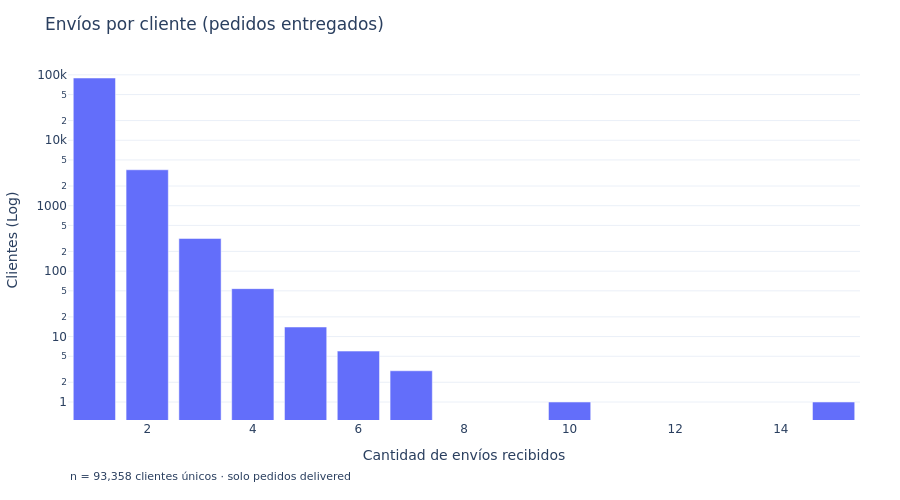

  → /home/notebooks/graficos/D1_envios_por_cliente.png


In [99]:
# D1 Envíos por cliente (customer_unique_id)
# Distribución de frecuencia: cuántos clientes recibieron 1, 2, 3... envíos
freq_cliente = (
    envios
    .groupBy("customer_unique_id").count().withColumnRenamed("count", "n_envios")
    .groupBy("n_envios").count().withColumnRenamed("count", "n_clientes")
    .orderBy("n_envios")
)

total_clientes  = envios.select("customer_unique_id").distinct().count()
clientes_1sola  = freq_cliente.filter(F.col("n_envios") == 1).collect()[0]["n_clientes"]
tasa_recompra   = 1 - clientes_1sola / total_clientes

print(f"Clientes únicos (K15 insumo): {total_clientes:,}")
print(f"Con un solo envío:            {clientes_1sola:,}  ({clientes_1sola/total_clientes:.1%})")
print(f"Tasa de recompra (K15):       {tasa_recompra:.1%}")

# Gráfico: eje Y logarítmico (distribución de cola pesada)
fig = (
    freq_cliente
    .orderBy("n_envios")
    .limit(20)
    .plot.bar(
        x="n_envios", y="n_clientes",
        title="Envíos por cliente (pedidos entregados)",
    )
)
fig.update_yaxes(type="log", title_text="Clientes (Log)")
fig.update_xaxes(title_text="Cantidad de envíos recibidos")
fig.add_annotation(
    text=f"n = {total_clientes:,} clientes únicos · solo pedidos delivered",
    xref="paper", yref="paper", x=0, y=-0.18, showarrow=False, font_size=11
)
guardar(fig, "D1_envios_por_cliente.png")

+--------------+-----+----+
|customer_state|count| pct|
+--------------+-----+----+
|            SP|41089|42.0|
|            RJ|12515|12.8|
|            MG|11523|11.8|
|            RS| 5443| 5.6|
|            PR| 4987| 5.1|
|            SC| 3588| 3.7|
|            BA| 3294| 3.4|
|            DF| 2106| 2.2|
|            ES| 2022| 2.1|
|            GO| 1988| 2.0|
|            PE| 1602| 1.6|
|            CE| 1290| 1.3|
|            PA|  955| 1.0|
|            MT|  905| 0.9|
|            MA|  729| 0.7|
|            MS|  708| 0.7|
|            PB|  521| 0.5|
|            PI|  478| 0.5|
|            RN|  478| 0.5|
|            AL|  399| 0.4|
|            SE|  338| 0.3|
|            TO|  282| 0.3|
|            RO|  246| 0.3|
|            AM|  145| 0.1|
|            AC|   80| 0.1|
|            AP|   67| 0.1|
|            RR|   41| 0.0|
+--------------+-----+----+



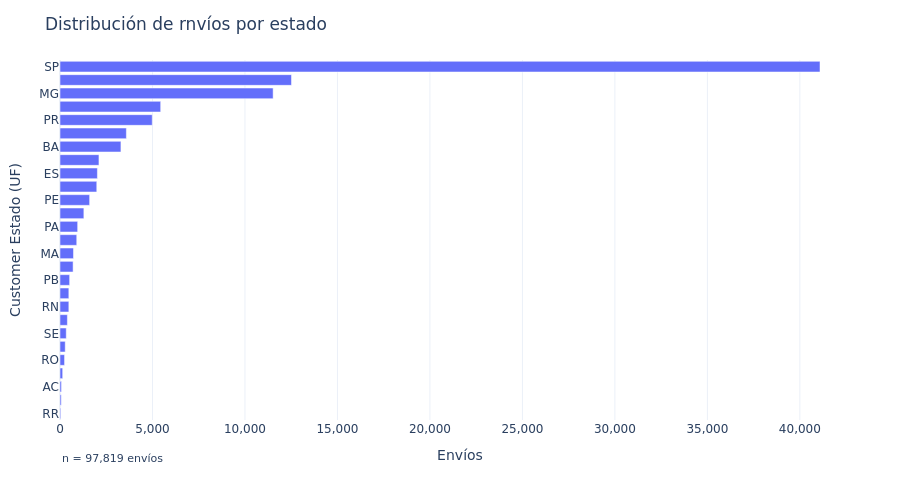

  → /home/notebooks/graficos/D2_envios_por_estado_destino.png


In [100]:
# D2 Envíos por estado de destino (los 27 estados)
dest_estado = (
    envios
    .groupBy("customer_state").count()
    .withColumn("pct", F.round(F.col("count") / n_envios * 100, 1))
    .orderBy(F.desc("count"))
)
dest_estado.show(27)

fig = (
    dest_estado
    .plot.barh(
        y="customer_state", x="count",
        title="Distribución de rnvíos por estado ",
    )
)
fig.update_xaxes(title_text="Envíos", tickformat=",")
fig.update_yaxes(title_text="Customer Estado (UF)", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_envios:,} envíos",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11
)
guardar(fig, "D2_envios_por_estado_destino.png")


Ciudades de destino distintas: 4,266
% envíos a top-10 ciudades:    35.1%
% envíos a top-20 ciudades:    42.1%


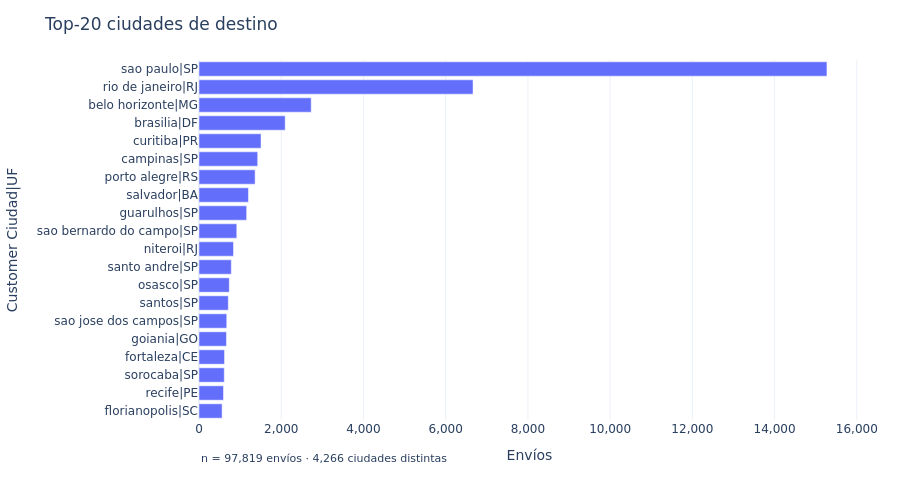

  → /home/notebooks/graficos/D3_top20_ciudades_destino.png


In [101]:
# D3 Envíos por ciudad de destino: top-20
top20_dest = (
    envios
    .groupBy("dest_ciudad_uf").count()
    .orderBy(F.desc("count"))
    .limit(20)
)

total_ciudades_dest = envios.select("dest_ciudad_uf").distinct().count()
top10_pct = (
    envios.groupBy("dest_ciudad_uf").count().orderBy(F.desc("count")).limit(10)
    .agg(F.sum("count")).collect()[0][0] / n_envios
)
top20_pct = top20_dest.agg(F.sum("count")).collect()[0][0] / n_envios

print(f"Ciudades de destino distintas: {total_ciudades_dest:,}")
print(f"% envíos a top-10 ciudades:    {top10_pct:.1%}")
print(f"% envíos a top-20 ciudades:    {top20_pct:.1%}")

fig = (
    top20_dest
    .plot.barh(
        y="dest_ciudad_uf", x="count",
        title="Top-20 ciudades de destino",
    )
)
fig.update_xaxes(title_text="Envíos", tickformat=",")
fig.update_yaxes(title_text="Customer Ciudad|UF", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_envios:,} envíos · {total_ciudades_dest:,} ciudades distintas",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11
)
guardar(fig, "D3_top20_ciudades_destino.png")


## Sección E — Vendedores (origen)

Envíos por vendedor — P50=7 P90=73  P99=406  max=1819  (percentile_approx, valores aproximados)


Vendedores activos:              2,970
K14 concentración (top 10%):     67.8% de los envíos


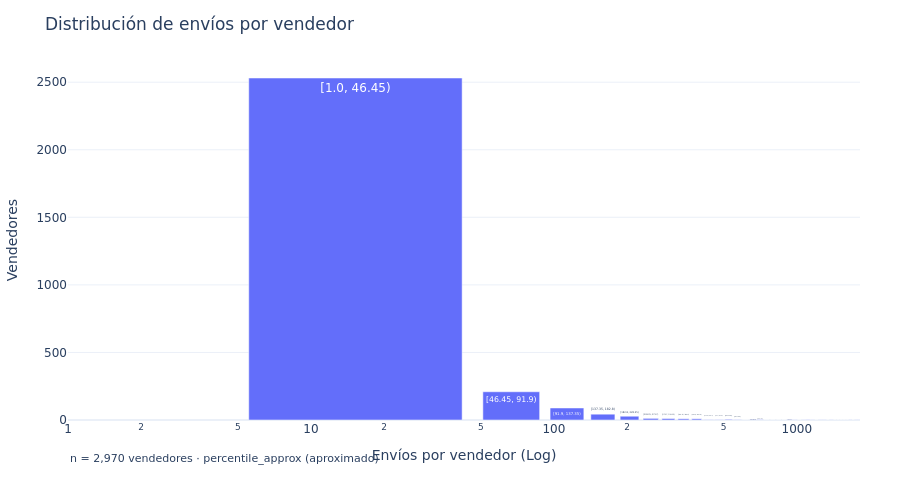

  → /home/notebooks/graficos/E1_envios_por_vendedor_hist.png


In [102]:
# E1 Envíos por vendedor: distribución + concentración
envios_por_vendedor = (
    envios.groupBy("seller_id").count().withColumnRenamed("count", "n_envios_seller")
)

cuantiles_v = (
    envios_por_vendedor
    .select(
        F.percentile_approx("n_envios_seller", [0.5, 0.9, 0.99]).alias("cuantiles"),
        F.max("n_envios_seller").alias("maximo")
    )
    .collect()[0]
)
print(f"Envíos por vendedor — P50={cuantiles_v['cuantiles'][0]} "
      f"P90={cuantiles_v['cuantiles'][1]}  P99={cuantiles_v['cuantiles'][2]}  "
      f"max={cuantiles_v['maximo']}  (percentile_approx, valores aproximados)")

# Concentración: % de envíos del 10% de vendedores con más envíos (insumo K14)
n_sellers_total = envios_por_vendedor.count()
top10p_n = max(1, int(n_sellers_total * 0.1))
top10p_envios = (
    envios_por_vendedor.orderBy(F.desc("n_envios_seller")).limit(top10p_n)
    .agg(F.sum("n_envios_seller")).collect()[0][0]
)
concentracion_k14 = top10p_envios / n_envios
print(f"Vendedores activos:              {n_sellers_total:,}")
print(f"K14 concentración (top 10%):     {concentracion_k14:.1%} de los envíos")

fig = (
    envios_por_vendedor
    .plot.hist(
        column="n_envios_seller",
        bins=40,
        title="Distribución de envíos por vendedor",
    )
)
fig.update_xaxes(type="log", title_text="Envíos por vendedor (Log)")
fig.update_yaxes(title_text="Vendedores")
fig.add_annotation(
    text=f"n = {n_sellers_total:,} vendedores · percentile_approx (aproximado)",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11
)
guardar(fig, "E1_envios_por_vendedor_hist.png")


In [103]:
# E2 Ítems vs. envíos por vendedor
items_por_vendedor = (
    order_items
    .join(delivered.select("order_id"), "order_id")
    .groupBy("seller_id").count().withColumnRenamed("count", "n_items_seller")
)

resumen_ev = (
    envios_por_vendedor
    .join(items_por_vendedor, "seller_id")
    .select(
        F.sum("n_envios_seller").alias("total_envios"),
        F.sum("n_items_seller").alias("total_items"),
        (F.sum("n_items_seller") / F.sum("n_envios_seller")).alias("items_por_envio_promedio")
    )
)
resumen_ev.show()
print("Un pedido con 2 vendedores = 2 envíos pero puede tener 3 o más ítems.")


+------------+-----------+------------------------+
|total_envios|total_items|items_por_envio_promedio|
+------------+-----------+------------------------+
|       97819|     110197|      1.1265398337746246|
+------------+-----------+------------------------+

Un pedido con 2 vendedores = 2 envíos pero puede tener 3 o más ítems.


+------------+-----+----+
|seller_state|count| pct|
+------------+-----+----+
|          SP|69401|70.9|
|          MG| 7747| 7.9|
|          PR| 7556| 7.7|
|          RJ| 4229| 4.3|
|          SC| 3608| 3.7|
|          RS| 1964| 2.0|
|          DF|  808| 0.8|
|          BA|  550| 0.6|
|          GO|  451| 0.5|
|          PE|  403| 0.4|
|          MA|  389| 0.4|
|          ES|  310| 0.3|
|          MT|  136| 0.1|
|          CE|   87| 0.1|
|          RN|   51| 0.1|
|          MS|   49| 0.1|
|          PB|   35| 0.0|
|          RO|   14| 0.0|
|          PI|   11| 0.0|
|          SE|    9| 0.0|
|          PA|    8| 0.0|
|          AM|    3| 0.0|
+------------+-----+----+



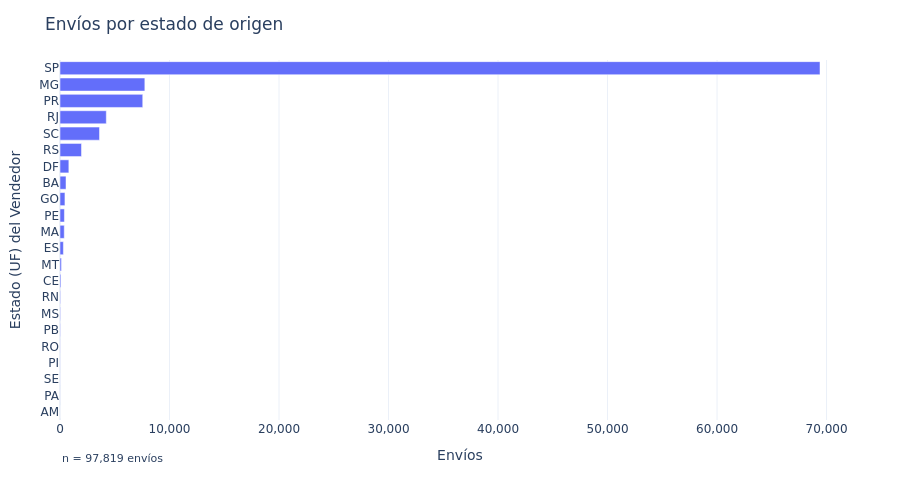

  → /home/notebooks/graficos/E3_envios_por_estado_origen.png


In [104]:
# E3 Envíos por estado de origen
orig_estado = (
    envios
    .groupBy("seller_state").count()
    .withColumn("pct", F.round(F.col("count") / n_envios * 100, 1))
    .orderBy(F.desc("count"))
)
orig_estado.show(27)

fig = (
    orig_estado
    .plot.barh(
        y="seller_state", x="count",
        title="Envíos por estado de origen",
    )
)
fig.update_xaxes(title_text="Envíos", tickformat=",")
fig.update_yaxes(title_text="Estado (UF) del Vendedor", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_envios:,} envíos",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11
)
guardar(fig, "E3_envios_por_estado_origen.png")


Ciudades de origen distintas:  614
% envíos desde top-10 ciudades: 49.2%
% envíos desde top-20 ciudades: 60.9%


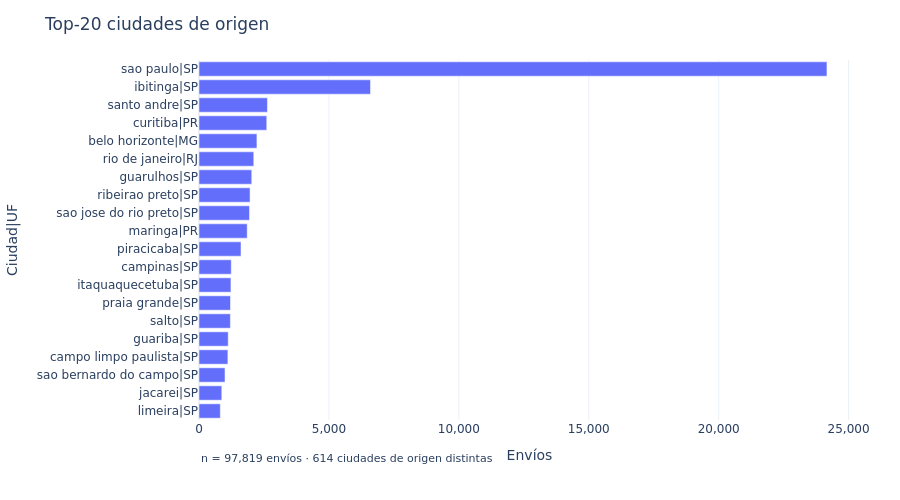

  → /home/notebooks/graficos/E4_top20_ciudades_origen.png


In [105]:
# E4 Top-20 ciudades de origen
total_ciudades_orig = envios.select("orig_ciudad_uf").distinct().count()
top20_orig = (
    envios.groupBy("orig_ciudad_uf").count()
    .orderBy(F.desc("count")).limit(20)
)
top10p_orig = (
    envios.groupBy("orig_ciudad_uf").count().orderBy(F.desc("count")).limit(10)
    .agg(F.sum("count")).collect()[0][0] / n_envios
)
top20p_orig = top20_orig.agg(F.sum("count")).collect()[0][0] / n_envios
print(f"Ciudades de origen distintas:  {total_ciudades_orig:,}")
print(f"% envíos desde top-10 ciudades: {top10p_orig:.1%}")
print(f"% envíos desde top-20 ciudades: {top20p_orig:.1%}")

fig = (
    top20_orig
    .plot.barh(
        y="orig_ciudad_uf", x="count",
        title="Top-20 ciudades de origen",
    )
)
fig.update_xaxes(title_text="Envíos", tickformat=",")
fig.update_yaxes(title_text="Ciudad|UF", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_envios:,} envíos · {total_ciudades_orig:,} ciudades de origen distintas",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11
)
guardar(fig, "E4_top20_ciudades_origen.png")


## Rutas
city-city y state-stae (como nominales)
cyty t tity se espera que la mayoria tenga un pedido

+-------+-----+
|ruta_uf|count|
+-------+-----+
|SP → SP|31185|
|SP → RJ|8274 |
|SP → MG|7562 |
|SP → RS|3663 |
|SP → PR|3164 |
|PR → SP|2975 |
|MG → SP|2583 |
|SP → SC|2355 |
|SP → BA|2340 |
|MG → MG|1542 |
|SP → ES|1481 |
|SP → GO|1448 |
|SP → DF|1398 |
|RJ → SP|1339 |
|SC → SP|1330 |
+-------+-----+



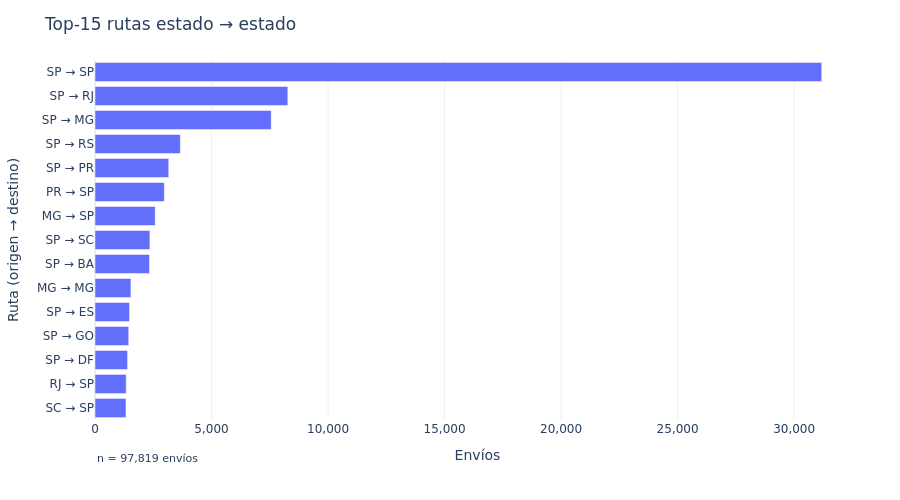

  → /home/notebooks/graficos/F1_top15_rutas_estado.png


In [106]:
# F1 Top-15 rutas estado → estado
rutas_estado = (
    envios
    .withColumn("ruta_uf", F.concat_ws(" → ", F.col("seller_state"), F.col("customer_state")))
    .groupBy("ruta_uf").count()
    .orderBy(F.desc("count"))
    .limit(15)
)
rutas_estado.show(truncate=False)

fig = (
    rutas_estado
    .plot.barh(
        y="ruta_uf", x="count",
        title="Top-15 rutas estado → estado",
    )
)
fig.update_xaxes(title_text="Envíos", tickformat=",")
fig.update_yaxes(title_text="Ruta (origen → destino)", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_envios:,} envíos",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11
)

guardar(fig, "F1_top15_rutas_estado.png")


+--------------------------------+-----------+-----+
|ruta_ciudad                     |intraurbana|count|
+--------------------------------+-----------+-----+
|sao paulo|SP → sao paulo|SP     |1          |4096 |
|sao paulo|SP → rio de janeiro|RJ|0          |1382 |
|ibitinga|SP → sao paulo|SP      |0          |1125 |
|sao paulo|SP → belo horizonte|MG|0          |576  |
|ibitinga|SP → rio de janeiro|RJ |0          |490  |
|sao paulo|SP → brasilia|DF      |0          |473  |
|santo andre|SP → sao paulo|SP   |0          |426  |
|curitiba|PR → sao paulo|SP      |0          |369  |
|sao paulo|SP → campinas|SP      |0          |364  |
|sao paulo|SP → curitiba|PR      |0          |352  |
|piracicaba|SP → sao paulo|SP    |0          |330  |
|sao paulo|SP → porto alegre|RS  |0          |329  |
|sao paulo|SP → salvador|BA      |0          |322  |
|sao paulo|SP → guarulhos|SP     |0          |317  |
|guarulhos|SP → sao paulo|SP     |0          |316  |
+--------------------------------+-----------+

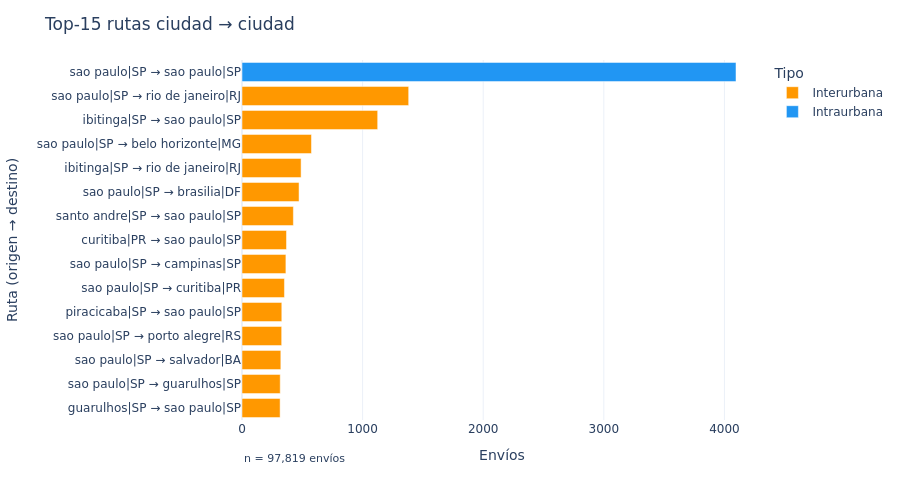

  → /home/notebooks/graficos/F2_top15_rutas_ciudad.png


In [107]:
# F2 Rutas ciudad → ciudad: intraurbana vs interurbana
# Problema: las rutas intraurbanas son logística local distinta; separarlas evita
# que dominen el ranking de rutas más frecuentes.
envios_ruta = (
    envios
    .withColumn("ruta_ciudad",
        F.concat_ws(" → ", F.col("orig_ciudad_uf"), F.col("dest_ciudad_uf")))
    .withColumn("intraurbana",
        (F.col("orig_ciudad_uf") == F.col("dest_ciudad_uf")).cast("int"))
)

top15_rutas = (
    envios_ruta
    .groupBy("ruta_ciudad", "intraurbana").count()
    .orderBy(F.desc("count"))
    .limit(15)
)
top15_rutas.show(truncate=False)

import plotly.express as px

top15_pd = top15_rutas.toPandas()   # solo 15 filas, excepción justificada
top15_pd["tipo"] = top15_pd["intraurbana"].map({1: "Intraurbana", 0: "Interurbana"})
top15_pd = top15_pd.sort_values("count")

fig = px.bar(
    top15_pd, x="count", y="ruta_ciudad", color="tipo",
    orientation="h",
    color_discrete_map={"Intraurbana": "#2196F3", "Interurbana": "#FF9800"},
    title="Top-15 rutas ciudad → ciudad",
    labels={"count": "Envíos", "ruta_ciudad": "Ruta (origen → destino)", "tipo": "Tipo"}
)
fig.add_annotation(
    text=f"n = {n_envios:,} envíos",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11
)
guardar(fig, "F2_top15_rutas_ciudad.png")


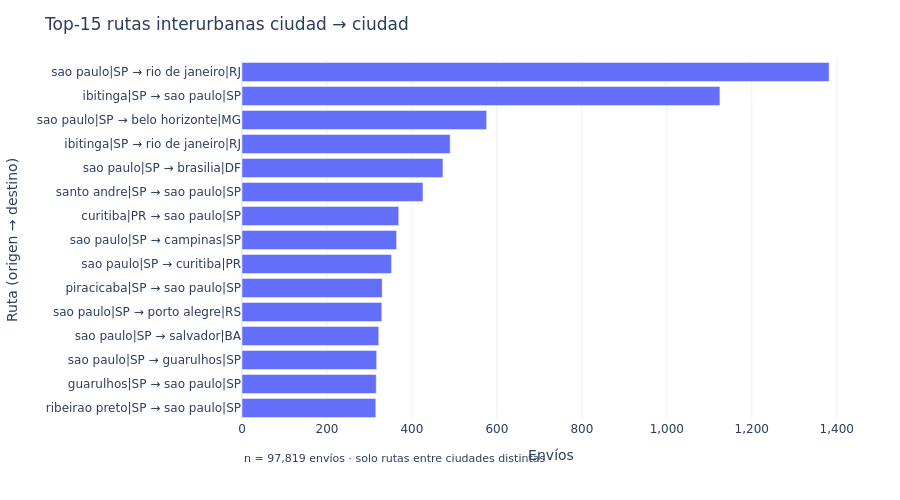

  → /home/notebooks/graficos/F3_top15_rutas_interurbanas.png


In [108]:
# F3 Top-15 solo rutas interurbanas
top15_inter = (
    envios_ruta
    .filter(F.col("intraurbana") == 0)
    .groupBy("ruta_ciudad").count()
    .orderBy(F.desc("count"))
    .limit(15)
)

fig = (
    top15_inter
    .plot.barh(
        y="ruta_ciudad", x="count",
        title="Top-15 rutas interurbanas ciudad → ciudad",
    )
)
fig.update_xaxes(title_text="Envíos", tickformat=",")
fig.update_yaxes(title_text="Ruta (origen → destino)", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_envios:,} envíos · solo rutas entre ciudades distintas",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11
)
guardar(fig, "F3_top15_rutas_interurbanas.png")


In [109]:
# F4 — Proporciones y estadísticas de rutas
n_intra   = envios_ruta.filter(F.col("intraurbana") == 1).count()
pct_intra = n_intra / n_envios

mismo_estado = envios.filter(F.col("seller_state") == F.col("customer_state")).count()
pct_mismo    = mismo_estado / n_envios

# Cantidad de rutas ciudad → ciudad distintas y % con 1 o 2 envíos
rutas_all = (
    envios_ruta
    .groupBy("ruta_ciudad").count()
    .cache()
)
n_rutas_total = rutas_all.count()
n_rutas_12    = rutas_all.filter(F.col("count") <= 2).count()

print(f"Envíos intraurbanos (misma ciudad):  {n_intra:,}  ({pct_intra:.1%})")
print(f"Envíos dentro del mismo estado:      {mismo_estado:,}  ({pct_mismo:.1%})")
print(f"Rutas ciudad→ciudad distintas:       {n_rutas_total:,}")
print(f"Rutas con 1 o 2 envíos:              {n_rutas_12:,}  ({n_rutas_12/n_rutas_total:.1%})")
print()
print("Las rutas ciudad→ciudad sirven para describir concentración pero no para")
print("comparar demoras: el 70%+ de rutas tienen muy pocos envíos (alta varianza).")


Envíos intraurbanos (misma ciudad):  4,991  (5.1%)
Envíos dentro del mismo estado:      35,186  (36.0%)
Rutas ciudad→ciudad distintas:       35,840
Rutas con 1 o 2 envíos:              30,584  (85.3%)

Las rutas ciudad→ciudad sirven para describir concentración pero no para
comparar demoras: el 70%+ de rutas tienen muy pocos envíos (alta varianza).


## Columnas creadas en esta sección

| Columna | DataFrame | Definición | Problema que resuelve |
|---|---|---|---|
| `city_canon` | `customers_c` | Nombre de ciudad en minúsculas, sin acentos, sin apóstrofos/guiones, espacios colapsados | Agrupa variantes del mismo nombre (con/sin acento, con/sin guion) |
| `city_canon` | `sellers_c` | Ídem sobre `seller_city` | Ídem para ciudades de vendedores |
| `dest_ciudad_uf` | `envios` | `city_canon + "|" + customer_state` | Identifica el municipio de destino sin ambigüedad entre estados |
| `orig_ciudad_uf` | `envios` | `city_canon + "|" + seller_state` | Ídem para el municipio de origen |
| `ruta_uf` | calculada | `seller_state + " → " + customer_state` | Ruta a nivel de estado |
| `ruta_ciudad` | `envios_ruta` | `orig_ciudad_uf + " → " + dest_ciudad_uf` | Ruta a nivel de municipio |
| `intraurbana` | `envios_ruta` | 1 si `orig_ciudad_uf == dest_ciudad_uf`, 0 si no | Separa logística local de interurbana |

DataFrame cacheado: **`envios`**, una fila por par (order_id, seller_id) entregado,
con claves de origen y destino. Base de todos los análisis de rutas.

## Resumen para el informe

### Distribución geográfica de envíos

Los 97 819 envíos del dataset (96 478 delivered + otros estados) están fuertemente concentrados en
el eje SP–RJ. São Paulo genera ~72 % de los envíos como origen; como destino SP más RJ y MG suman
~45 % del total.

**Ciudades de destino:** São Paulo lidera con ~15 000 envíos; Río de Janeiro (~6 800) y Belo
Horizonte (~3 000) completan el podio (ver `D2_envios_por_estado_destino.png`,
`D3_top20_ciudades_destino.png`).

**Rutas más frecuentes:** SP → SP concentra el mayor volumen; las rutas SP → MG, SP → PR y
SP → RJ le siguen (ver `F1_top15_rutas_estado.png`).

**Envíos intraurbanos:** ~5% de los envíos son dentro de la misma ciudad (ciudad|UF
iguales). Las distancias intraurbanas no son cero — reflejan la resolución del centroide por
prefijo postal (ver `E3_dist_por_tipo.png`).

### Limitaciones

- La distribución geográfica puede subestimar estados con alta densidad de vendedores nuevos
  sin geolocalización.
- Las ciudades de destino se identifican por `ciudad|UF`; variantes no unificadas quedan en
  categorías separadas (mitigado en la capa silver con corrección Levenshtein, umbral ≤ 2).


## Corrección silver de nombres de ciudad (ceps.csv + Levenshtein)

**Problema residual de la sección A:** la canonicalización unifica variantes gráficas
(mayúsculas, acentos, guiones), pero no resuelve errores de tipeo como `sao paolo` → `sao paulo`
o `fortalza` → `fortaleza`. Para eso se usa una referencia oficial.

**Fuente de referencia:** `data/ceps.csv` — catálogo de municipios de Brasil (6 614 filas,
una por municipio). Columnas usadas: `UF`, `LOCALIDADE` (nombre oficial con acentos),
`LOCALIDADE_SEM_ACENTOS` (sin acentos, para comparar).

**Estrategia:**
1. Cargar el catálogo y canonicalizarlo con `canon_native` (misma función que las secciones A–H).
2. Unión exacta por `(city_canon, uf)` → cobertura sin coste.
3. Para los no-emparejados: `levenshtein(city_canon, city_ref_canon, umbral=2)` nativo de Spark
   (Spark 3.5+ acepta tercer parámetro de corte; retorna −1 si supera el umbral). Join previo
   por `uf` para reducir el producto cartesiano.
4. Si la distancia mínima es > 2 → `city_corregida = NULL` (el nombre queda en revisión manual).

**Resultado:** columna `city_corregida` en `customers_silver` y `sellers_silver`.

In [110]:
# Cargar y normalizar el catálogo de CEPs
ceps_raw = spark.read.csv(
    "/home/notebooks/data/ceps.csv",
    header=True, inferSchema=False
)

# Canonicalizar el nombre de referencia (misma pipeline que city_canon)
ceps_ref = (
    ceps_raw
    .select(
        F.trim(F.col("UF")).alias("uf"),
        F.trim(F.col("LOCALIDADE")).alias("localidade_oficial"),
        canon_native("LOCALIDADE_SEM_ACENTOS").alias("city_ref_canon"),
    )
    .distinct()
    .cache()
)

n_ref = ceps_ref.count()
print(f"Municipios de referencia (ceps_ref): {n_ref:,}")
ceps_ref.show(5, truncate=False)


Municipios de referencia (ceps_ref): 5,570
+---+------------------+--------------+
|uf |localidade_oficial|city_ref_canon|
+---+------------------+--------------+
|AL |Canapi            |canapi        |
|BA |Mascote           |mascote       |
|ES |Piúma             |piuma         |
|GO |Anápolis          |anapolis      |
|GO |Gouvelândia       |gouvelandia   |
+---+------------------+--------------+
only showing top 5 rows


In [111]:
# I2 Cobertura por unión exacta: customers
# Claves de búsqueda: (city_canon, customer_state)
cust_domain = (
    customers_c
    .select(F.col("city_canon"), F.col("customer_state").alias("uf"))
    .distinct()
)

exact_cust = cust_domain.join(
    ceps_ref.select("city_ref_canon", "uf", "localidade_oficial"),
    (F.col("city_canon") == F.col("city_ref_canon")) & (cust_domain["uf"] == ceps_ref["uf"]),
    "inner"
).select(cust_domain["city_canon"], cust_domain["uf"],
         F.col("localidade_oficial"), F.lit(0).alias("dist"))

unmatched_cust = cust_domain.join(exact_cust, ["city_canon", "uf"], "left_anti")

n_dom   = cust_domain.count()
n_exact = exact_cust.count()
n_unm   = unmatched_cust.count()
print(f"Ciudades únicas en customers:       {n_dom:,}")
print(f"  Emparejadas exactas:              {n_exact:,}  ({n_exact/n_dom:.1%})")
print(f"  Sin emparejar (para Levenshtein): {n_unm:,}  ({n_unm/n_dom:.1%})")
unmatched_cust.orderBy("city_canon").show(20, truncate=False)


Ciudades únicas en customers:       4,304
  Emparejadas exactas:              3,995  (92.8%)
  Sin emparejar (para Levenshtein): 309  (7.2%)


+---------------------+---+
|city_canon           |uf |
+---------------------+---+
|abrantes             |BA |
|adhemar de barros    |PR |
|agisse               |SP |
|aguas claras         |RS |
|ajapi                |SP |
|alexandra            |PR |
|alexandrita          |MG |
|alta floresta d oeste|RO |
|alto alegre          |PR |
|alto alegre do iguacu|PR |
|alto sao joao        |PR |
|alvorada d oeste     |RO |
|amanari              |CE |
|andrequice           |MG |
|angelo frechiani     |ES |
|angustura            |MG |
|anhandui             |MS |
|anta                 |RJ |
|antonio pereira      |MG |
|antunes              |MG |
+---------------------+---+
only showing top 20 rows


In [112]:
# I3 Corrección por Levenshtein (solo ciudades no emparejadas, customers)
# Join por uf primero, kuego reduce producto cartesiano a ~municipios por estado

UMBRAL = 2

lev_cust = (
    unmatched_cust.alias("um")
    .join(ceps_ref.alias("ref"), F.col("um.uf") == F.col("ref.uf"))
    .withColumn("dist",
        F.levenshtein(F.col("um.city_canon"), F.col("ref.city_ref_canon"), UMBRAL))
    .filter(F.col("dist") >= 0)   # -1 = superó el umbral
    .withColumn("rk", F.row_number().over(
        Window.partitionBy("um.city_canon", "um.uf")
              .orderBy(F.col("dist").asc(), F.col("ref.city_ref_canon").asc())
    ))
    .filter(F.col("rk") == 1)
    .select(
        F.col("um.city_canon"), F.col("um.uf"),
        F.col("ref.localidade_oficial"), F.col("dist")
    )
)

n_lev = lev_cust.count()
print(f"Ciudades corregidas por Levenshtein (umbral={UMBRAL}): {n_lev:,}")
lev_cust.orderBy("dist", "city_canon").show(30, truncate=False)


Ciudades corregidas por Levenshtein (umbral=2): 68


+------------------------+---+------------------------+----+
|city_canon              |uf |localidade_oficial      |dist|
+------------------------+---+------------------------+----+
|alta floresta d oeste   |RO |Alta Floresta D'Oeste   |1   |
|alvorada d oeste        |RO |Alvorada D'Oeste        |1   |
|aparecida d oeste       |SP |Aparecida D'Oeste       |1   |
|bataipora               |MS |Batayporã               |1   |
|brasopolis              |MG |Brazópolis              |1   |
|caraiba                 |PE |Carnaíba                |1   |
|conquista d oeste       |MT |Conquista D'Oeste       |1   |
|diamante d oeste        |PR |Diamante D'Oeste        |1   |
|dias d avila            |BA |Dias D'Ávila            |1   |
|estrela d oeste         |SP |Estrela D'Oeste         |1   |
|figueiropolis d oeste   |MT |Figueirópolis D'Oeste   |1   |
|florinia                |SP |Florínea                |1   |
|herval d oeste          |SC |Herval D'Oeste          |1   |
|ibitira                

In [113]:
# I4 Construir tabla de correcciones (exact + levenshtein) y ciudades sin match
from pyspark.sql import functions as F2   # alias para evitar confusión de nombre

all_corrections_cust = exact_cust.union(lev_cust)
still_unmatched_cust = (
    cust_domain
    .join(all_corrections_cust, ["city_canon", "uf"], "left_anti")
)
n_still = still_unmatched_cust.count()
print(f"Ciudades sin corrección posible (dist > {UMBRAL}): {n_still:,}")
if n_still > 0:
    still_unmatched_cust.orderBy("city_canon").show(20, truncate=False)


Ciudades sin corrección posible (dist > 2): 241


+-----------------------+---+
|city_canon             |uf |
+-----------------------+---+
|abrantes               |BA |
|adhemar de barros      |PR |
|agisse                 |SP |
|aguas claras           |RS |
|alexandra              |PR |
|alexandrita            |MG |
|alto alegre            |PR |
|alto alegre do iguacu  |PR |
|alto sao joao          |PR |
|amanari                |CE |
|andrequice             |MG |
|angelo frechiani       |ES |
|angustura              |MG |
|anhandui               |MS |
|anta                   |RJ |
|antonio pereira        |MG |
|antunes                |MG |
|aparecida de monte alto|SP |
|aparecida de sao manuel|SP |
|arace                  |ES |
+-----------------------+---+
only showing top 20 rows


Alfunos de estos n sn ciudades, sn una unidad administrativa menos, com distrito. Habria que conceguir  
json distrito y asignar city

In [114]:
# I5 Aplicar correcciones a customers_c → customers_silver
customers_silver = (
    customers_c
    .join(
        all_corrections_cust.select(
            F.col("city_canon"),
            F.col("uf").alias("customer_state"),
            F.col("localidade_oficial").alias("city_corregida"),
            F.col("dist").alias("city_dist"),
        ),
        ["city_canon", "customer_state"],
        "left"
    )
    .cache()
)

# Verificar cobertura
n_cust = customers_silver.count()
n_corr = customers_silver.filter(F.col("city_corregida").isNotNull()).count()
print(f"customers_silver: {n_cust:,} filas | con city_corregida: {n_corr:,} ({n_corr/n_cust:.1%})")
print(f"Sin corregir (NULL): {n_cust - n_corr:,}")
customers_silver.select("customer_id","customer_city","city_canon","city_corregida","city_dist").show(10)


customers_silver: 99,441 filas | con city_corregida: 98,981 (99.5%)
Sin corregir (NULL): 460
+--------------------+--------------+--------------+--------------+---------+
|         customer_id| customer_city|    city_canon|city_corregida|city_dist|
+--------------------+--------------+--------------+--------------+---------+
|67e6f3a450dcc7470...| arroio grande| arroio grande| Arroio Grande|        0|
|6f380f1105060ce0a...| arroio grande| arroio grande| Arroio Grande|        0|
|4a1bdf4fac99c14d5...| arroio grande| arroio grande| Arroio Grande|        0|
|edb2c9160f064e4ef...|        cumaru|        cumaru|        Cumaru|        0|
|ed272867c9e0ce1d4...|        cumaru|        cumaru|        Cumaru|        0|
|e37623a7c983c5174...|   doce grande|   doce grande|          NULL|     NULL|
|934e84f2cd66b617d...|dona francisca|dona francisca|Dona Francisca|        0|
|0a8590845fd49614c...|dona francisca|dona francisca|Dona Francisca|        0|
|a854caf1b1cc61e8c...| feliz deserto| feliz deser

In [115]:
# I6 Mismo pipeline para sellers
sell_domain = (
    sellers_c
    .select(F.col("city_canon"), F.col("seller_state").alias("uf"))
    .distinct()
)

exact_sell = sell_domain.join(
    ceps_ref.select("city_ref_canon", "uf", "localidade_oficial"),
    (F.col("city_canon") == F.col("city_ref_canon")) & (sell_domain["uf"] == ceps_ref["uf"]),
    "inner"
).select(sell_domain["city_canon"], sell_domain["uf"],
         F.col("localidade_oficial"), F.lit(0).alias("dist"))

unmatched_sell = sell_domain.join(exact_sell, ["city_canon", "uf"], "left_anti")

lev_sell = (
    unmatched_sell.alias("um")
    .join(ceps_ref.alias("ref"), F.col("um.uf") == F.col("ref.uf"))
    .withColumn("dist",
        F.levenshtein(F.col("um.city_canon"), F.col("ref.city_ref_canon"), UMBRAL))
    .filter(F.col("dist") >= 0)
    .withColumn("rk", F.row_number().over(
        Window.partitionBy("um.city_canon", "um.uf")
              .orderBy(F.col("dist").asc(), F.col("ref.city_ref_canon").asc())
    ))
    .filter(F.col("rk") == 1)
    .select(F.col("um.city_canon"), F.col("um.uf"),
            F.col("ref.localidade_oficial"), F.col("dist"))
)

all_corrections_sell = exact_sell.union(lev_sell)

sellers_silver = (
    sellers_c
    .join(
        all_corrections_sell.select(
            F.col("city_canon"),
            F.col("uf").alias("seller_state"),
            F.col("localidade_oficial").alias("city_corregida"),
            F.col("dist").alias("city_dist"),
        ),
        ["city_canon", "seller_state"],
        "left"
    )
    .cache()
)

n_sell = sellers_silver.count()
n_corr_s = sellers_silver.filter(F.col("city_corregida").isNotNull()).count()
unmatched_sell_final = sell_domain.join(all_corrections_sell, ["city_canon", "uf"], "left_anti")
n_still_s = unmatched_sell_final.count()
print(f"sellers_silver: {n_sell:,} filas | con city_corregida: {n_corr_s:,} ({n_corr_s/n_sell:.1%})")
print(f"Sin corregir (NULL, dist > {UMBRAL}): {n_still_s:,}")
if n_still_s > 0:
    unmatched_sell_final.orderBy("city_canon").show(20, truncate=False)


sellers_silver: 3,095 filas | con city_corregida: 3,021 (97.6%)
Sin corregir (NULL, dist > 2): 63


+------------------------------+---+
|city_canon                    |uf |
+------------------------------+---+
|04482255                      |RJ |
|aguas claras df               |SP |
|andira pr                     |PR |
|andradas                      |SP |
|angra dos reis rj             |RJ |
|arraial d ajuda (porto seguro)|BA |
|auriflama/sp                  |SP |
|barbacena/ minas gerais       |MG |
|belo horizonte                |SP |
|blumenau                      |SP |
|brasilia df                   |DF |
|carapicuiba / sao paulo       |SP |
|cariacica / es                |ES |
|castro pires                  |MG |
|caxias do sul                 |SP |
|centro                        |MG |
|chapeco                       |SP |
|curitiba                      |SP |
|florianopolis                 |SP |
|gama                          |DF |
+------------------------------+---+
only showing top 20 rows


## Columnas nuevas de la capa silver

| Columna | DataFrame | Definición | Fuente |
|---|---|---|---|
| `city_corregida` | `customers_silver`, `sellers_silver` | Nombre oficial del municipio (con acentos) según `ceps.csv` | Unión exacta (dist=0) o Levenshtein ≤ 2 contra `LOCALIDADE` |
| `city_dist` | ídem | Distancia Levenshtein entre `city_canon` y la referencia (0 = coincidencia exacta; NULL = sin match) | `F.levenshtein(umbral=2)` |

**`customers_silver`** y **`sellers_silver`** reemplazan a `customers_c`/`sellers_c` en todos los
análisis de la capa silver en adelante. `city_canon` se conserva para trazabilidad.

## Centroides por prefijo postal y distancias de envío

Estos son rutas pero como distancias  (linea recta)

Construye la **capa silver** de geolocalización:
- `geo_cep_silver` : un centroide confiable por prefijo de CEP (5 dígitos).
- `envios_distancia`: los envíos entregados con su distancia origen–destino en km.

Reutiliza `geo`, `moda`, `disid`, `cz`, `sz`, `envios`, `GRAFICOS`, `guardar`.

In [116]:
import os

SILVER_BASE = 's3a://olist/silver'
EDA_DIR     = '/home/notebooks/eda'
os.makedirs(EDA_DIR, exist_ok=True)
print(f'Silver → {SILVER_BASE}')
print(f'CSVs   → {EDA_DIR}')
print(f'PNGs   → {GRAFICOS}')


Silver → s3a://olist/silver
CSVs   → /home/notebooks/eda
PNGs   → /home/notebooks/graficos


## El problema de la ubicación

Las tablas `customers` y `sellers` se vinculan con la geolocalización **solo por el prefijo de
CEP de 5 dígitos** (`customer_zip_code_prefix`, `seller_zip_code_prefix`,
`geolocation_zip_code_prefix`). Nunca por latitud/longitud directamente.

Esto introduce tres fuentes de incertidumbre:

1. **Varios puntos por prefijo** — `geolocation` tiene hasta cientos de coordenadas por prefijo
   (y muchos duplicados exactos). Hay que elegir una coordenada representativa.
2. **Puntos erróneos** — coordenadas geocodificadas fuera de Brasil (Portugal, España, Italia,
   EE.UU., México, Argentina) por ambigüedad de nombres, y filas con el estado mal cargado.
3. **Prefijos ausentes** — hay prefijos de clientes y vendedores que directamente no existen en
   `geolocation`: esos envíos quedarán sin distancia.

Las secciones B–D cuantifican cada problema y toman decisiones documentadas.

In [117]:
#  Magnitudes del problema
n_geo_raw      = geolocation.count()
n_geo_distintos = geolocation.select(
    "geolocation_zip_code_prefix","geolocation_lat","geolocation_lng"
).distinct().count()
n_prefijos_geo  = geolocation.select("geolocation_zip_code_prefix").distinct().count()
n_prefijos_cust = customers.select("customer_zip_code_prefix").distinct().count()
n_prefijos_sell = sellers.select("seller_zip_code_prefix").distinct().count()

print(f"Filas totales en geolocation:          {n_geo_raw:>10,}")
print(f"Puntos distintos (zip, lat, lng):      {n_geo_distintos:>10,}")
print(f"Prefijos distintos en geolocation:     {n_prefijos_geo:>10,}")
print(f"Prefijos distintos en customers:       {n_prefijos_cust:>10,}")
print(f"Prefijos distintos en sellers:         {n_prefijos_sell:>10,}")


Filas totales en geolocation:           1,000,163
Puntos distintos (zip, lat, lng):         720,154
Prefijos distintos en geolocation:         19,015
Prefijos distintos en customers:           14,994
Prefijos distintos en sellers:              2,246


## Limpieza de puntos

Se aplican cuatro pasos en orden; se cuantifica cuántas filas afecta cada uno.

In [118]:
# B1 Normalización del prefijo a 5 dígitos con ceros a la izquierda
# `geo` (ya definido) = geolocation con zip = lpad(geolocation_zip_code_prefix, 5, '0')
# Verificar que lpad recupera los ceros perdidos en el CSV
ej_antes = (geolocation.select("geolocation_zip_code_prefix")
            .orderBy(F.length(F.col("geolocation_zip_code_prefix").cast("string"))).limit(3)
            .collect())
ej_despues = (geo.select("zip")
              .orderBy(F.length("zip")).limit(3).collect())
print("Ejemplo sin lpad:", [r[0] for r in ej_antes])
print("Ejemplo con lpad:", [r[0] for r in ej_despues])
n_cortoszip = geo.filter(F.length("zip") < 5).count()
print(f"Prefijos con < 5 dígitos después de lpad: {n_cortoszip}  (debe ser 0)")


Ejemplo sin lpad: ['26556', '01037', '11013']
Ejemplo con lpad: ['11013', '01037', '26556']


Prefijos con < 5 dígitos después de lpad: 0  (debe ser 0)


In [119]:
# B2 Estado inconsistente: filas cuyo estado difiere del mayoritario por prefijo
# `moda` y `disid` ya están definidos en celdas anteriores
n_disidentes = (geo.join(moda, "zip")
                .filter(F.col("geolocation_state") != F.col("uf_moda"))
                .count())
print(f"Filas con estado distinto al mayoritario por prefijo: {n_disidentes:,}")
print()
# Detalle de los afectados
(geo.join(moda, "zip")
 .filter(F.col("geolocation_state") != F.col("uf_moda"))
 .select("zip","uf_moda","geolocation_state","geolocation_city",
         "geolocation_lat","geolocation_lng")
 .show(20, truncate=False))


Filas con estado distinto al mayoritario por prefijo: 8



+-----+-------+-----------------+------------------------+-------------------+-------------------+
|zip  |uf_moda|geolocation_state|geolocation_city        |geolocation_lat    |geolocation_lng    |
+-----+-------+-----------------+------------------------+-------------------+-------------------+
|72915|GO     |DF               |taguatinga              |-12.408759613951991|-46.428287292167845|
|80630|PR     |SC               |balneario de picarras   |-26.75737075199301 |-48.6757379478268  |
|78557|MT     |RO               |nova brasilandia d'oeste|-11.87514215367095 |-55.50301968733746 |
|02116|SP     |RN               |são paulo               |-23.515978148767935|-46.582169967107184|
|23056|RJ     |AC               |rio de janeiro          |-22.919164311034095|-43.61109694482953 |
|04011|SP     |AC               |sao paulo               |-23.57870736918802 |-46.645778615462866|
|79750|MS     |RS               |nova andradina          |-22.242062424214726|-53.34315944664074 |
|21550|RJ 

In [120]:
# B3  Bounding box de Brasil
# Latitud: −34 a 5.3 | Longitud: −74 a −28
# NOTA: el código anterior usaba −34 como límite este de longitud.
# Fernando de Noronha (PE) está en lng ≈ −32.4, que con el límite −34 quedaba EXCLUIDO.
# Con el límite correcto −28 queda incluido.

# Verificar el prefijo 53990 (Fernando de Noronha)
fdn = geo.filter(F.col("zip") == "53990")
print("Puntos en zip 53990 (Fernando de Noronha):")
fdn.show()

print("¿Pasan el filtro OLD (lng ≥ −74 AND lng ≤ −34)?")
print(fdn.filter(F.col("geolocation_lng").between(-74, -34)).count(), "→ espera 0")

print("¿Pasan el filtro NUEVO (lng ≥ −74 AND lng ≤ −28)?")
print(fdn.filter(F.col("geolocation_lng").between(-74, -28)).count(), "→ espera > 0")


Puntos en zip 53990 (Fernando de Noronha):


+--------------+---------------------------+-------------------+-------------------+-------------------+-----------------+-----+
|geolocation_id|geolocation_zip_code_prefix|    geolocation_lat|    geolocation_lng|   geolocation_city|geolocation_state|  zip|
+--------------+---------------------------+-------------------+-------------------+-------------------+-----------------+-----+
|        715893|                      53990| -3.845491431693799|-32.413367452152805|fernando de noronha|               PE|53990|
|        715894|                      53990| -3.853091999999947|-32.423524999999955|fernando de noronha|               PE|53990|
|        715897|                      53990|-3.8469299891113327|-32.415820786968744|fernando de noronha|               PE|53990|
|        715901|                      53990| -3.848319000000004|         -32.412384|fernando de noronha|               PE|53990|
|        715909|                      53990| -3.853091999999947|-32.423524999999955|fernando de n

0 → espera 0
¿Pasan el filtro NUEVO (lng ≥ −74 AND lng ≤ −28)?
11 → espera > 0


In [121]:
# B3 cont. — Cuántos puntos totales quedan fuera de Brasil con el bounding box NUEVO
en_brasil_nuevo = (F.col("geolocation_lat").between(-34, 5.3) &
                   F.col("geolocation_lng").between(-74, -28))

pts_raw   = geo.select("zip","geolocation_lat","geolocation_lng").distinct()
n_pts_raw = pts_raw.count()
fuera_new = pts_raw.filter(~en_brasil_nuevo)
n_fuera   = fuera_new.count()
print(f"Puntos distintos totales:     {n_pts_raw:,}")
print(f"Fuera del bounding box nuevo: {n_fuera:,}  ({n_fuera/n_pts_raw:.2%})")
print()
print("Ejemplo de puntos fuera:")
fuera_new.orderBy(F.desc("geolocation_lat")).show(10)

Puntos distintos totales:     720,154
Fuera del bounding box nuevo: 27  (0.00%)

Ejemplo de puntos fuera:
+-----+------------------+-------------------+
|  zip|   geolocation_lat|    geolocation_lng|
+-----+------------------+-------------------+
|57319| 45.06593318269697|  9.341527629906514|
|28595| 43.68496096631822| -7.411080413859842|
|28155| 42.43928591592116|  13.82021409761152|
|68447| 42.42888405758768| -6.873343870596927|
|83252| 42.18400274298598| -8.723762147513938|
|68275| 42.16725082536653|-6.8985590510710155|
|68275|42.166804640530444| -6.898530628106095|
|28165| 41.61405150610495| -8.411675312504059|
|58441| 41.38532754845633| -8.717341701284429|
|68275| 41.14620290949943|  -8.57785501800488|
+-----+------------------+-------------------+
only showing top 10 rows


In [122]:
# B4 Construir pts_limpio: distinct + dentro de Brasil + sin disidentes
# Limitación documentada: el rectángulo no excluye países vecinos (Paraguay ≈ lng −58)
geo_pts_limpio = (
    geo
    .filter(en_brasil_nuevo)
    .join(disid.select("zip","geolocation_lat","geolocation_lng"),
          ["zip","geolocation_lat","geolocation_lng"], "left_anti")
    .select("zip","geolocation_lat","geolocation_lng")
    .distinct()
    .cache()
)

n_pts_limpio = geo_pts_limpio.count()
n_prefijos_limpio = geo_pts_limpio.select("zip").distinct().count()
print(f"Puntos limpios y distintos: {n_pts_limpio:,}")
print(f"Prefijos representados:     {n_prefijos_limpio:,}")
print(f"Puntos eliminados total:    {n_pts_raw - n_pts_limpio:,}")
print(f"  - por bounding box:       {n_fuera:,}")
print(f"  - por estado disidente:   {n_disidentes:,}  (algunos pueden superponerse)")


Puntos limpios y distintos: 720,119
Prefijos representados:     19,011
Puntos eliminados total:    35
  - por bounding box:       27
  - por estado disidente:   8  (algunos pueden superponerse)


**Resumen B:** período útil 2017-01 → 2018-08. Tasa global: 6.79 %.
Los meses anteriores a 2017-01 tienen menos de 100 pedidos/mes; a partir de 2018-09
la tasa cae bruscamente (censura). Pedidos con más de un vendedor: 1 272
(1.3 %) — comparten el resultado tardío del pedido.

## Centro por prefijo (`geo_cep_silver`)

**Decisión:** mediana de latitud y longitud (`percentile_approx`), no el promedio.
- El promedio tiene **punto de quiebre 0**: un solo punto erróneo lo arrastra sin límite.
- La mediana tolera hasta casi el 50 % de puntos contaminados.
- **Advertencia con 1 o 2 puntos:** con 2 puntos la mediana es el punto medio. Por eso se marca la confianza: `ok` si `n_puntos ≥ 3`, `baja` si no.

In [123]:
# C1 Construir geo_cep_silver con mediana y flag de confianza
geo_cep_silver = (
    geo_pts_limpio
    .groupBy("zip")
    .agg(
        F.count("*").alias("n_puntos"),
        F.percentile_approx("geolocation_lat", 0.5).alias("lat_med"),
        F.percentile_approx("geolocation_lng", 0.5).alias("lng_med"),
    )
    .withColumn("geo_confianza",
        F.when(F.col("n_puntos") >= 3, "ok").otherwise("baja"))
    .cache()
)

n_cep  = geo_cep_silver.count()
n_baja = geo_cep_silver.filter(F.col("geo_confianza") == "baja").count()
n_ok   = n_cep - n_baja
print(f"Prefijos con centroide silver: {n_cep:,}")
print(f"  geo_confianza = ok (≥ 3 pts): {n_ok:,}  ({n_ok/n_cep:.1%})")
print(f"  geo_confianza = baja (1-2 pts): {n_baja:,}  ({n_baja/n_cep:.1%})")


Prefijos con centroide silver: 19,011
  geo_confianza = ok (≥ 3 pts): 17,067  (89.8%)
  geo_confianza = baja (1-2 pts): 1,944  (10.2%)


In [124]:
# C2 Distribución de n_puntos por prefijo (cuantiles y prefijos con < 3 puntos)
cuant_npts = (
    geo_cep_silver
    .select(
        F.percentile_approx("n_puntos", [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).alias("q"),
        F.max("n_puntos").alias("maximo"),
        F.sum((F.col("n_puntos") < 3).cast("int")).alias("n_menos3"),
    )
    .collect()[0]
)
print(f"n_puntos por prefijo — P10={cuant_npts['q'][0]}  P25={cuant_npts['q'][1]}"
      f"  P50={cuant_npts['q'][2]}  P75={cuant_npts['q'][3]}"
      f"  P90={cuant_npts['q'][4]}  P99={cuant_npts['q'][5]}  max={cuant_npts['maximo']}")
print(f"Prefijos con < 3 puntos: {cuant_npts['n_menos3']:,}  ({cuant_npts['n_menos3']/n_cep:.1%})")


n_puntos por prefijo — P10=2  P25=8  P50=22  P75=48  P90=89  P99=240  max=746
Prefijos con < 3 puntos: 1,944  (10.2%)


In [125]:
# C3 Dispersión dentro del prefijo: distancia de cada punto a la mediana de su prefijo
# Esto es la resolución espacial de las distancias que calcularemos.
R = 6371.0

def haversine(lat1, lng1, lat2, lng2):
    dlat = F.radians(lat2 - lat1)
    dlng = F.radians(lng2 - lng1)
    a = (F.pow(F.sin(dlat / 2), 2) +
         F.cos(F.radians(lat1)) * F.cos(F.radians(lat2)) *
         F.pow(F.sin(dlng / 2), 2))
    return F.lit(2 * R) * F.asin(F.sqrt(a))

# Join cada punto con el centroide de su prefijo, calcular distancia al centro
dispersion = (
    geo_pts_limpio
    .join(F.broadcast(geo_cep_silver.select("zip","lat_med","lng_med")), "zip")
    .withColumn("dist_al_centro_km",
        haversine(F.col("geolocation_lat"), F.col("geolocation_lng"),
                  F.col("lat_med"),         F.col("lng_med")))
)

cuant_disp = (
    dispersion
    .select(F.percentile_approx("dist_al_centro_km", [0.5, 0.9, 0.99]).alias("q"),
            F.max("dist_al_centro_km").alias("maximo"))
    .collect()[0]
)
print("Dispersión dentro del prefijo (distancia de cada punto a su mediana):")
print(f"  P50={cuant_disp['q'][0]:.1f} km  P90={cuant_disp['q'][1]:.1f} km"
      f"  P99={cuant_disp['q'][2]:.1f} km  max={cuant_disp['maximo']:.1f} km")
print()
print("Esta es la resolución espacial de las distancias de envío calculadas.")


Dispersión dentro del prefijo (distancia de cada punto a su mediana):
  P50=0.5 km  P90=1.6 km  P99=9.9 km  max=3360.8 km

Esta es la resolución espacial de las distancias de envío calculadas.


In [126]:
# C4 Guardar geo_cep_silver como Parquet en silver
(geo_cep_silver
 .coalesce(1)
 .write.mode("overwrite").parquet(f'{SILVER_BASE}/geo_cep'))
print(f"Guardado: {SILVER_BASE}/geo_cep")
print(f"Filas: {n_cep:,}")


Guardado: s3a://olist/silver/geo_cep
Filas: 19,011


**Resumen :** se construyeron 19,011 centroides de prefijo. 17,067  (89.8%) tienen
`geo_confianza = ok` (≥ 3 puntos limpios). La dispersión típica dentro de un prefijo
(P50=0.5 km  P90=1.6 km  P99=9.9 km  max=3360.8 km) establece la resolución espacial:
la distancia calculada puede diferir de la real en ese orden de magnitud.

Es decir: la dispersión dentro del prefijo ES el margen de error de tu distancia calculada.


## Ubicar envíos y calcular distancia

**Método:** unir `envios` con `geo_cep_silver` dos veces — por el prefijo del vendedor (origen)
y por el prefijo del cliente (destino). Se usa `broadcast` de `geo_cep_silver` (pequeño: ~19 k filas).

**Distancia:** Haversine en línea recta entre centros de prefijo, radio terrestre 6371 km.
Es la distancia **en línea recta**, no el recorrido real del transportista.

In [127]:
# D1 Agregar zip a envios (envios no los tiene; se obtienen de orders y de cz/sz)
envios_zip = (
    envios
    .join(orders.select("order_id", "customer_id"), "order_id")
    .join(cz.withColumnRenamed("zip", "dest_zip"), "customer_id")
    .join(sz.withColumnRenamed("zip", "orig_zip"), "seller_id")
    .drop("customer_id")
)
print(f"envios_zip: {envios_zip.count():,} filas")
envios_zip.select("order_id","seller_id","orig_zip","dest_zip").show(3)


envios_zip: 97,819 filas


+--------------------+--------------------+--------+--------+
|            order_id|           seller_id|orig_zip|dest_zip|
+--------------------+--------------------+--------+--------+
|005e5166e99d1e4d0...|e9bc59e7b60fc3063...|   87083|   88308|
|00f1c7c1542f5f86c...|cc419e0650a3c5ba7...|   09015|   35661|
|01882618ede112533...|d91fb3b7d041e83b6...|   11704|   36220|
+--------------------+--------------------+--------+--------+
only showing top 3 rows


In [128]:
# D2 — Broadcast join con geo_cep_silver (origen y destino)
geo_orig = F.broadcast(
    geo_cep_silver.select(
        F.col("zip").alias("orig_zip"),
        F.col("lat_med").alias("orig_lat"), F.col("lng_med").alias("orig_lng"),
        F.col("geo_confianza").alias("conf_orig"),
    ))
geo_dest = F.broadcast(
    geo_cep_silver.select(
        F.col("zip").alias("dest_zip"),
        F.col("lat_med").alias("dest_lat"), F.col("lng_med").alias("dest_lng"),
        F.col("geo_confianza").alias("conf_dest"),
    ))

envios_geo = (
    envios_zip
    .join(geo_orig, "orig_zip", "left")
    .join(geo_dest, "dest_zip", "left")
)
print(f"envios_geo: {envios_geo.count():,} filas")


envios_geo: 97,819 filas


In [129]:
# D3 Haversine nativa (resultado nulo si falta algún extremo)
envios_dist_raw = (
    envios_geo
    .withColumn("distancia_km",
        F.when(F.col("orig_lat").isNotNull() & F.col("dest_lat").isNotNull(),
            haversine(F.col("orig_lat"), F.col("orig_lng"),
                      F.col("dest_lat"), F.col("dest_lng")))
        .otherwise(F.lit(None).cast("double")))
)
print("Ejemplo de distancias calculadas:")
envios_dist_raw.filter(F.col("distancia_km").isNotNull()).select(
    "order_id","orig_zip","dest_zip","distancia_km").show(5)


Ejemplo de distancias calculadas:


+--------------------+--------+--------+------------------+
|            order_id|orig_zip|dest_zip|      distancia_km|
+--------------------+--------+--------+------------------+
|005e5166e99d1e4d0...|   87083|   88308| 512.0367151179835|
|00f1c7c1542f5f86c...|   09015|   35661|465.93800529863694|
|01882618ede112533...|   11704|   36220|  410.983118902187|
|02036bc298ab3c1ef...|   08573|   81830| 371.0074375328002|
|02971473bcfb16642...|   03426|   09820| 21.16017295636283|
+--------------------+--------+--------+------------------+
only showing top 5 rows


In [130]:
# D4 Columna distancia_calidad
envios_dist = (
    envios_dist_raw
    .withColumn("distancia_calidad",
        F.when(F.col("orig_lat").isNull() & F.col("dest_lat").isNull(), "sin_ambos")
         .when(F.col("orig_lat").isNull(),  "sin_origen")
         .when(F.col("dest_lat").isNull(),  "sin_destino")
         .when((F.col("conf_orig") == "baja") | (F.col("conf_dest") == "baja"), "baja")
         .otherwise("ok"))
    .cache()
)

n_dist = envios_dist.count()
print(f"Total envíos: {n_dist:,}")
(envios_dist
 .groupBy("distancia_calidad").count()
 .withColumn("pct", F.round(F.col("count") / n_dist * 100, 2))
 .orderBy(F.desc("count")).show())


Total envíos: 97,819


+-----------------+-----+-----+
|distancia_calidad|count|  pct|
+-----------------+-----+-----+
|               ok|96442|98.59|
|             baja|  890| 0.91|
|      sin_destino|  270| 0.28|
|       sin_origen|  216| 0.22|
|        sin_ambos|    1|  0.0|
+-----------------+-----+-----+



In [131]:
# D5 Tabla de cobertura con intervalo de Wilson (95 %) por estado de destino
# Wilson CI: p̂ = k/n ; centro = (p̂ + z²/(2n))/(1+z²/n) ; margen = z*sqrt(...)/(1+z²/n)
Z  = 1.96
Z2 = Z ** 2

n_sin_por_uf = (
    envios_dist
    .withColumn("sin_dist", (F.col("distancia_km").isNull()).cast("int"))
    .groupBy("customer_state")
    .agg(F.count("*").alias("n_total"),
         F.sum("sin_dist").alias("n_sin"))
    .withColumn("pi", F.col("n_sin").cast("double") / F.col("n_total"))
    .withColumn("_d", F.lit(1.0) + F.lit(Z2) / F.col("n_total"))
    .withColumn("wilson_lo",
        (F.col("pi") + F.lit(Z2)/(2*F.col("n_total")) -
         F.lit(Z)*F.sqrt(F.col("pi")*(1-F.col("pi"))/F.col("n_total") +
                          F.lit(Z2)/(4*F.col("n_total")*F.col("n_total")))) / F.col("_d"))
    .withColumn("wilson_hi",
        (F.col("pi") + F.lit(Z2)/(2*F.col("n_total")) +
         F.lit(Z)*F.sqrt(F.col("pi")*(1-F.col("pi"))/F.col("n_total") +
                          F.lit(Z2)/(4*F.col("n_total")*F.col("n_total")))) / F.col("_d"))
    .drop("_d")
    .orderBy(F.desc("pi"))
)
n_sin_por_uf.show(27, truncate=False)
n_sin_por_uf.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/cobertura_distancia_por_uf')
print(f"CSV → {EDA_DIR}/cobertura_distancia_por_uf")


+--------------+-------+-----+---------------------+-----------------------+---------------------+
|customer_state|n_total|n_sin|pi                   |wilson_lo              |wilson_hi            |
+--------------+-------+-----+---------------------+-----------------------+---------------------+
|DF            |2106   |170  |0.08072174738841406  |0.06983627874140722    |0.09313405988496175  |
|AC            |80     |1    |0.0125               |0.0022099186183062243  |0.06746432423965451  |
|RO            |246    |3    |0.012195121951219513 |0.00415587434759871    |0.03523548401706114  |
|PB            |521    |6    |0.011516314779270634 |0.005288352177079758   |0.024895230831584188 |
|TO            |282    |2    |0.0070921985815602835|0.001947055416814236   |0.02548632027097928  |
|GO            |1988   |13   |0.006539235412474849 |0.0038255360474677216  |0.011156378177036878 |
|PI            |478    |3    |0.006276150627615063 |0.0021366674489111115  |0.018288302084645144 |
|CE       

CSV → /home/notebooks/eda/cobertura_distancia_por_uf


In [132]:
# D6 — Cota de Manski global y por estado
# Con fracción π de envíos sin distancia, el estimador observado difiere de la verdad en ≤ π
n_ok_dist  = envios_dist.filter(F.col("distancia_calidad") == "ok").count()
n_sin_dist = n_dist - n_ok_dist
pi_global  = n_sin_dist / n_dist

print(f"Envíos con distancia 'ok':          {n_ok_dist:,}  ({1-pi_global:.1%})")
print(f"Envíos sin distancia (π global):    {n_sin_dist:,}  ({pi_global:.2%})")
print(f"→ Cota de Manski: cualquier proporción calculada sobre envíos con distancia")
print(f"  puede diferir de la verdadera en a lo sumo π = {pi_global:.2%}")
print()
print("Estados con mayor π (fracción sin distancia):")
n_sin_por_uf.filter(F.col("pi") > 0.05).select(
    "customer_state","n_total","n_sin","pi","wilson_lo","wilson_hi").show(10)


Envíos con distancia 'ok':          96,442  (98.6%)
Envíos sin distancia (π global):    1,377  (1.41%)
→ Cota de Manski: cualquier proporción calculada sobre envíos con distancia
  puede diferir de la verdadera en a lo sumo π = 1.41%

Estados con mayor π (fracción sin distancia):


+--------------+-------+-----+-------------------+-------------------+-------------------+
|customer_state|n_total|n_sin|                 pi|          wilson_lo|          wilson_hi|
+--------------+-------+-----+-------------------+-------------------+-------------------+
|            DF|   2106|  170|0.08072174738841406|0.06983627874140722|0.09313405988496175|
+--------------+-------+-----+-------------------+-------------------+-------------------+



In [133]:
# D7 Guardar envios_distancia en silver (sin columnas intermedias innecesarias)
cols_silver = [
    "order_id","seller_id","customer_unique_id",
    "customer_state","seller_state",
    "dest_ciudad_uf","orig_ciudad_uf",
    "orig_zip","dest_zip",
    "orig_lat","orig_lng","dest_lat","dest_lng",
    "distancia_km","distancia_calidad",
]
(envios_dist.select(*cols_silver)
 .write.mode("overwrite").parquet(f'{SILVER_BASE}/envios_distancia'))
print(f"Guardado: {SILVER_BASE}/envios_distancia  ({n_dist:,} filas)")


Guardado: s3a://olist/silver/envios_distancia  (97,819 filas)


**Resumen:** la variable con mayor V es **Estado de destino** (V = 0.136, tamaño mediano).
**Región de destino** es la segunda (V = 0.078). Tramo de distancia, mismo/otro estado y estado
de origen tienen efecto pequeño (V entre 0.054 y 0.073).
Recordar: son asociaciones descriptivas, no causas.

## Distribución de distancias

Todos los análisis sobre `distancia_calidad = 'ok'`, excepto donde se indique.

In [134]:
# E base: filtrar solo 'ok'
envios_ok = envios_dist.filter(F.col("distancia_calidad") == "ok").cache()
n_ok = envios_ok.count()
print(f"Envíos con distancia ok: {n_ok:,}")


Envíos con distancia ok: 96,442


In [135]:
# E1 — Estadísticas descriptivas de distancia_km
stats_dist = (
    envios_ok
    .select(
        F.mean("distancia_km").alias("media"),
        F.percentile_approx("distancia_km",
            [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).alias("q"),
        F.stddev("distancia_km").alias("desvio"),
        F.max("distancia_km").alias("maximo"),
    )
    .collect()[0]
)
print("Estadísticas de distancia_km (km):")
print(f"  Media:  {stats_dist['media']:.1f}   Desvío: {stats_dist['desvio']:.1f}")
print(f"  P10={stats_dist['q'][0]:.0f}  P25={stats_dist['q'][1]:.0f}  "
      f"P50(mediana)={stats_dist['q'][2]:.0f}  P75={stats_dist['q'][3]:.0f}  "
      f"P90={stats_dist['q'][4]:.0f}  P99={stats_dist['q'][5]:.0f}  max={stats_dist['maximo']:.0f}")
print()
print("La media supera la mediana: distribución asimétrica a la derecha (cola de envíos")
print("muy largos, sobre todo hacia el Norte/Nordeste).")


Estadísticas de distancia_km (km):
  Media:  597.4   Desvío: 589.8
  P10=34  P25=184  P50(mediana)=431  P75=794  P90=1452  P99=2482  max=3399

La media supera la mediana: distribución asimétrica a la derecha (cola de envíos
muy largos, sobre todo hacia el Norte/Nordeste).


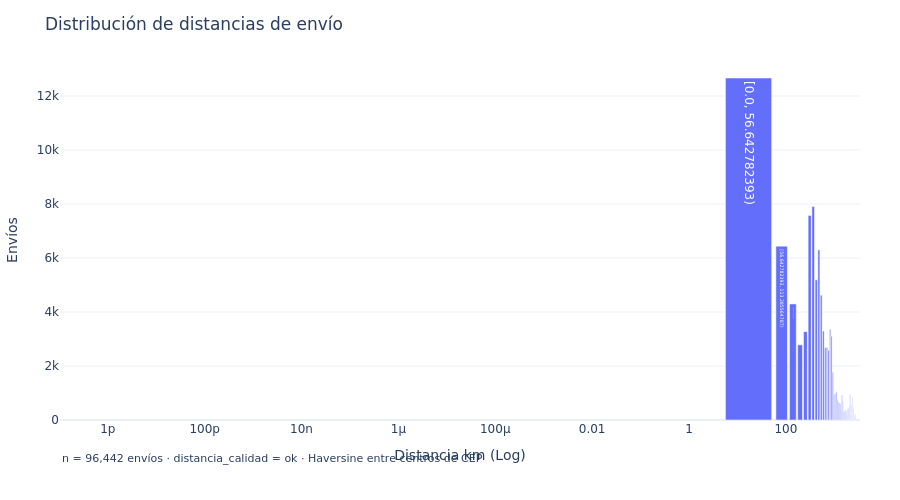

  → /home/notebooks/graficos/E1_dist_km_histograma.png


In [136]:
# E1b — Histograma de distancia_km con eje X logarítmico
fig = (
    envios_ok
    .select("distancia_km")
    .plot.hist(
        column="distancia_km",
        bins=60,
        title="Distribución de distancias de envío",
    )
)
fig.update_xaxes(type="log", title_text="Distancia km (Log)")
fig.update_yaxes(title_text="Envíos")
fig.add_annotation(
    text=f"n = {n_ok:,} envíos · distancia_calidad = ok · Haversine entre centros de CEP",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "E1_dist_km_histograma.png")


In [137]:
# E2 — Tramos de distancia
# Local < 50 km | Regional 50–300 km | Nacional media 300–1000 km | Nacional larga > 1000 km
# Justificación: < 50 km = entrega urbana/suburbana (mismo día factible);
#                50–300 = regional por carretera; 300–1000 = rutas interestatales cortas;
#                > 1000 = travesías largas (ej. SP → PA o SP → AM).
envios_tramo = (
    envios_ok
    .withColumn("tramo",
        F.when(F.col("distancia_km") <   50, "1_local (<50 km)")
         .when(F.col("distancia_km") <  300, "2_regional (50–300 km)")
         .when(F.col("distancia_km") < 1000, "3_nacional_media (300–1000 km)")
         .otherwise(                         "4_nacional_larga (>1000 km)"))
)

tramos_agg = (
    envios_tramo
    .groupBy("tramo").count()
    .withColumn("pct", F.round(F.col("count") / n_ok * 100, 1))
    .orderBy("tramo")
)
tramos_agg.show()
tramos_agg.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/tramos_distancia')


+--------------------+-----+----+
|               tramo|count| pct|
+--------------------+-----+----+
|    1_local (<50 km)|11801|12.2|
|2_regional (50–30...|19685|20.4|
|3_nacional_media ...|49699|51.5|
|4_nacional_larga ...|15257|15.8|
+--------------------+-----+----+



In [ ]:
# E2b Gráfico de tramos
fig = (
    tramos_agg
    .plot.bar(
        x="tramo", y="pct",
        title="Distribución de envíos por tramo de distancia",
    )
)
fig.update_xaxes(title_text="Tramo", tickangle=-45)
fig.update_yaxes(title_text="% de envíos")
fig.add_annotation(
    text=f"n = {n_ok:,} envíos · distancia_calidad = ok",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "E2_tramos_distancia.png")


In [139]:
# E3 — Intraurbana vs. interurbana (misma ciudad|UF) y mismo estado vs. otro estado
envios_grupos = (
    envios_tramo
    .withColumn("intraurbana",  F.col("orig_ciudad_uf") == F.col("dest_ciudad_uf"))
    .withColumn("mismo_estado", F.col("seller_state")   == F.col("customer_state"))
)

grupos_stats = (
    envios_grupos
    .groupBy("intraurbana", "mismo_estado")
    .agg(
        F.count("*").alias("n"),
        F.percentile_approx("distancia_km", [0.5, 0.9]).alias("q"),
        F.mean("distancia_km").alias("media_km"),
    )
    .withColumn("P50", F.col("q")[0])
    .withColumn("P90", F.col("q")[1])
    .drop("q")
    .orderBy("intraurbana","mismo_estado")
)
grupos_stats.show()

intra_stats = grupos_stats.filter(F.col("intraurbana")).collect()[0]
print(f"Distancia intraurbana: P50={intra_stats['P50']:.1f} km  P90={intra_stats['P90']:.1f} km")
print("→ La distancia intraurbana NO es cero: centros de CEP distintos dentro de la ciudad.")


+-----------+------------+-----+------------------+------------------+------------------+
|intraurbana|mismo_estado|    n|          media_km|               P50|               P90|
+-----------+------------+-----+------------------+------------------+------------------+
|      false|       false|61506| 849.4258206571254| 653.0440148894845|1920.6351524329198|
|      false|        true|29996|176.70218399734563|127.38683291903392|389.58645089607853|
|       true|        true| 4940|14.356403569186833|12.464660362078986| 25.34788083986549|
+-----------+------------+-----+------------------+------------------+------------------+



Distancia intraurbana: P50=12.5 km  P90=25.3 km
→ La distancia intraurbana NO es cero: centros de CEP distintos dentro de la ciudad.


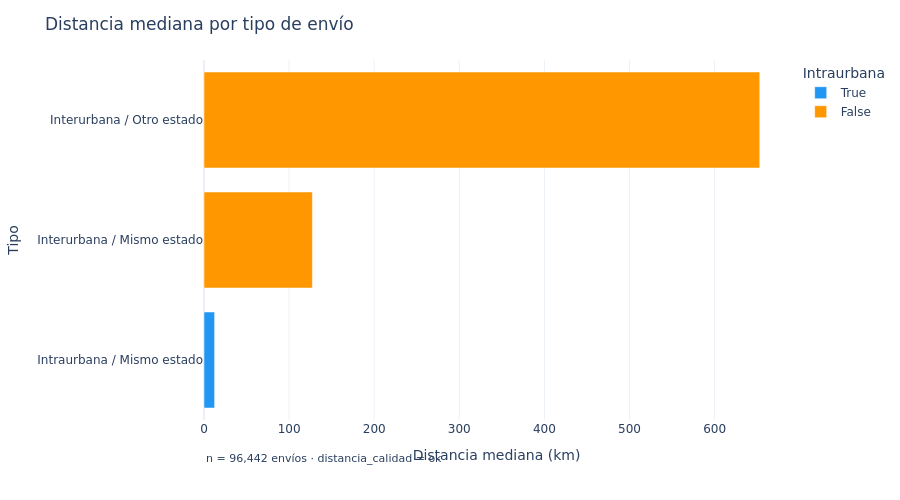

  → /home/notebooks/graficos/E3_dist_por_tipo.png


In [140]:
# E3b — Distancia mediana por grupo (4 combinaciones): barras horizontales
import plotly.express as px

grupos_pd = grupos_stats.toPandas()   # 4 filas: excepción acotada justificada
grupos_pd["grupo"] = grupos_pd.apply(
    lambda r: ("Intraurbana" if r["intraurbana"] else "Interurbana") + " / " +
              ("Mismo estado" if r["mismo_estado"] else "Otro estado"), axis=1)
grupos_pd = grupos_pd.sort_values("P50")

fig = px.bar(grupos_pd, x="P50", y="grupo", orientation="h",
             color="intraurbana",
             color_discrete_map={True: "#2196F3", False: "#FF9800"},
             title="Distancia mediana por tipo de envío",
             labels={"P50": "Distancia mediana (km)", "grupo": "Tipo", "intraurbana": "Intraurbana"})
fig.add_annotation(
    text=f"n = {n_ok:,} envíos · distancia_calidad = ok",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "E3_dist_por_tipo.png")


In [141]:
# E4 — Distancia mediana y P90 por estado de origen (≥ 30 envíos)
dist_origen = (
    envios_ok
    .groupBy("seller_state")
    .agg(
        F.count("*").alias("n"),
        F.percentile_approx("distancia_km", [0.5, 0.9]).alias("q"),
    )
    .withColumn("P50", F.col("q")[0])
    .withColumn("P90", F.col("q")[1])
    .filter(F.col("n") >= 30)
    .orderBy(F.desc("P50"))
    .drop("q")
)
n_excluidos_o = (envios_ok.groupBy("seller_state").count()
                 .filter(F.col("count") < 30).count())
print(f"Estados de origen excluidos (< 30 envíos ok): {n_excluidos_o}")
dist_origen.show(27)


Estados de origen excluidos (< 30 envíos ok): 5


+------------+-----+------------------+------------------+
|seller_state|    n|               P50|               P90|
+------------+-----+------------------+------------------+
|          MA|  387|2267.1632876254075|2608.1061034917366|
|          CE|   84|2155.6591846138945| 2522.013333299771|
|          PE|  363| 1804.831630512906|2316.2937937334086|
|          PB|   35|1802.1523618307922| 2215.974965797877|
|          MT|  133|1372.7241585457402|2036.4177669168685|
|          BA|  540| 1172.861985436424| 1779.765397604193|
|          MS|   47| 917.7570367008942|1380.2614713404012|
|          DF|  733| 870.9182387626269|1343.9396910538394|
|          RS| 1946| 863.4786153359048|1648.4681343199243|
|          GO|  444| 809.8822939231729| 1658.866991118621|
|          ES|  310| 735.3055267022312|1520.7562224623723|
|          SC| 3585|  589.334889762451|1302.8066339942284|
|          PR| 7492| 563.2569298860473| 1204.617020220644|
|          MG| 7640|472.67103154528985|1268.143731603407

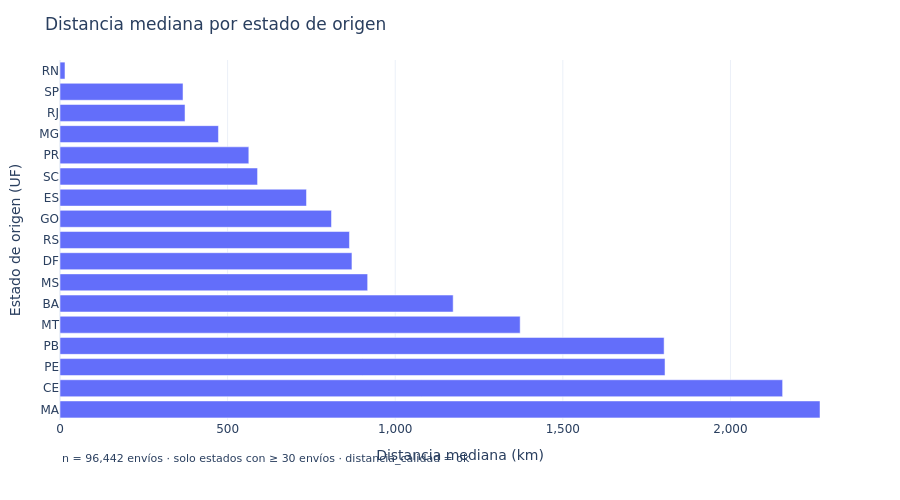

  → /home/notebooks/graficos/E4_dist_por_estado_origen.png


In [142]:
# E4b — Gráfico: distancia mediana por estado de origen
fig = (
    dist_origen.orderBy("P50")
    .plot.barh(
        x="P50", y="seller_state",
        title="Distancia mediana por estado de origen",
    )
)
fig.update_xaxes(title_text="Distancia mediana (km)", tickformat=",")
fig.update_yaxes(title_text="Estado de origen (UF)", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_ok:,} envíos · solo estados con ≥ 30 envíos · distancia_calidad = ok",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "E4_dist_por_estado_origen.png")


Estados de destino excluidos (< 30 envíos ok): 0


+--------------+-----+------------------+------------------+
|customer_state|    n|               P50|               P90|
+--------------+-----+------------------+------------------+
|            RR|   41|3302.8101717822583|3357.9120590005323|
|            AC|   78| 2710.248058573086|2812.6416945180454|
|            AM|  141|2693.6710685089874|   2823.6871762972|
|            AP|   67| 2662.569281920412|3006.7434526303596|
|            PA|  941|2394.3784107922015| 2513.444749541316|
|            CE| 1253|2292.5465426273436|2385.6608616308113|
|            RO|  237|2291.2126535642674| 2509.048980608162|
|            RN|  467| 2263.752227560155|2474.1577800150935|
|            MA|  718|2197.3209590967076| 2404.098269347765|
|            PB|  503|2165.1531997657135|2534.9564272204257|
|            PE| 1581| 2081.728232440962| 2215.939300752835|
|            PI|  441| 2051.761239171739|2340.2275086364507|
|            AL|  388| 1915.658525852761| 2268.751578466565|
|            SE|  330|17

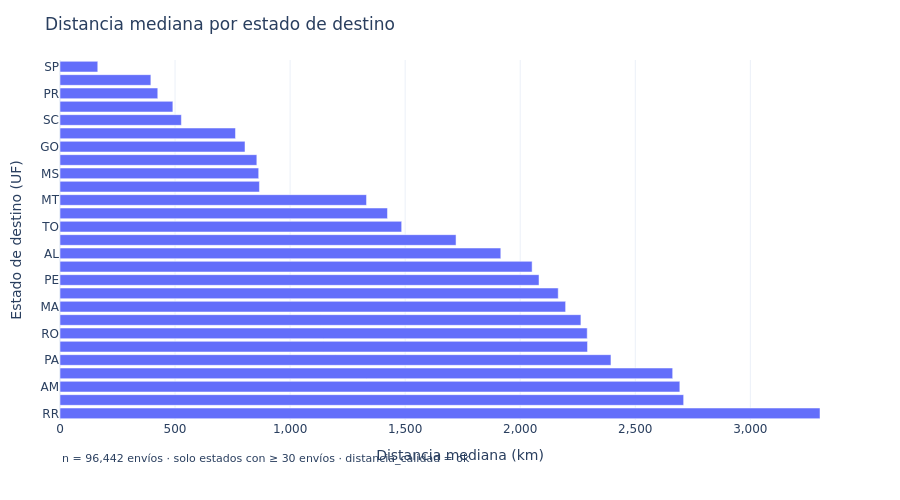

  → /home/notebooks/graficos/E4d_dist_por_estado_destino.png


In [143]:
# E4c — Distancia mediana y P90 por estado de destino (≥ 30 envíos)
dist_destino = (
    envios_ok
    .groupBy("customer_state")
    .agg(
        F.count("*").alias("n"),
        F.percentile_approx("distancia_km", [0.5, 0.9]).alias("q"),
    )
    .withColumn("P50", F.col("q")[0])
    .withColumn("P90", F.col("q")[1])
    .filter(F.col("n") >= 30)
    .orderBy(F.desc("P50"))
    .drop("q")
)
n_excluidos_d = (envios_ok.groupBy("customer_state").count()
                 .filter(F.col("count") < 30).count())
print(f"Estados de destino excluidos (< 30 envíos ok): {n_excluidos_d}")
dist_destino.show(27)

fig = (
    dist_destino.orderBy("P50")
    .plot.barh(
        x="P50", y="customer_state",
        title="Distancia mediana por estado de destino",
    )
)
fig.update_xaxes(title_text="Distancia mediana (km)", tickformat=",")
fig.update_yaxes(title_text="Estado de destino (UF)", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_ok:,} envíos · solo estados con ≥ 30 envíos · distancia_calidad = ok",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "E4d_dist_por_estado_destino.png")


In [144]:
# E5 — Top-15 rutas estado→estado por volumen: distancia mediana y P90
rutas_dist = (
    envios_ok
    .withColumn("ruta_uf", F.concat_ws(" → ", F.col("seller_state"), F.col("customer_state")))
    .groupBy("ruta_uf")
    .agg(
        F.count("*").alias("n_envios"),
        F.percentile_approx("distancia_km", [0.5, 0.9]).alias("q"),
    )
    .withColumn("P50", F.col("q")[0])
    .withColumn("P90", F.col("q")[1])
    .orderBy(F.desc("n_envios"))
    .limit(15)
    .drop("q")
)
rutas_dist.show(15, truncate=False)
rutas_dist.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/top15_rutas_distancia')


+-------+--------+------------------+------------------+
|ruta_uf|n_envios|P50               |P90               |
+-------+--------+------------------+------------------+
|SP → SP|30968   |95.05228232746744 |356.7667895044471 |
|SP → RJ|8186    |383.57849698616474|633.3510196673761 |
|SP → MG|7479    |488.8352539947819 |720.4861552739169 |
|SP → RS|3609    |867.4480473343112 |1091.5897273948642|
|SP → PR|3123    |418.85467117801096|699.8354507667502 |
|PR → SP|2964    |469.21268505254335|684.2477687673924 |
|MG → SP|2554    |466.95979898516043|563.7619986709523 |
|SP → SC|2332    |543.4455604099667 |733.3688381577622 |
|SP → BA|2298    |1447.4755372347795|1552.2373220462077|
|MG → MG|1531    |239.51566923552554|502.34254143987107|
|SP → ES|1455    |761.4961430929432 |907.9065404365039 |
|SP → GO|1423    |795.7466291679211 |924.6705197464124 |
|RJ → SP|1334    |369.3511465067006 |541.4177845066645 |
|SC → SP|1328    |488.3742466908498 |652.4364331871528 |
|SP → DF|1185    |862.226183336

In [ ]:
# E5b — Barras horizontales: top-15 rutas por distancia mediana
fig = (
    rutas_dist.orderBy("P50")
    .plot.barh(
        x="P50", y="ruta_uf",
        title="Distancia mediana. Top-15 rutas estado→estado",
    )
)
fig.update_xaxes(title_text="Distancia mediana (km)", tickformat=",")
fig.update_yaxes(title_text="Ruta (origen → destino)", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_ok:,} envíos · top-15 rutas por volumen · distancia_calidad = ok",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "E5_dist_top15_rutas.png")


In [146]:
# E6 — Mapeo estado → región de Brasil
mapa_region_data = [
    ("AM","Norte"),("RR","Norte"),("AP","Norte"),("PA","Norte"),
    ("TO","Norte"),("RO","Norte"),("AC","Norte"),
    ("MA","Nordeste"),("PI","Nordeste"),("CE","Nordeste"),("RN","Nordeste"),
    ("PE","Nordeste"),("PB","Nordeste"),("SE","Nordeste"),("AL","Nordeste"),("BA","Nordeste"),
    ("MT","Centro-Oeste"),("MS","Centro-Oeste"),("GO","Centro-Oeste"),("DF","Centro-Oeste"),
    ("SP","Sudeste"),("RJ","Sudeste"),("MG","Sudeste"),("ES","Sudeste"),
    ("PR","Sul"),("SC","Sul"),("RS","Sul"),
]
mapa_region = spark.createDataFrame(mapa_region_data, ["uf","region"])
print("Mapeo estado → región:")
mapa_region.orderBy("region","uf").show(27)


Mapeo estado → región:


+---+------------+
| uf|      region|
+---+------------+
| DF|Centro-Oeste|
| GO|Centro-Oeste|
| MS|Centro-Oeste|
| MT|Centro-Oeste|
| AL|    Nordeste|
| BA|    Nordeste|
| CE|    Nordeste|
| MA|    Nordeste|
| PB|    Nordeste|
| PE|    Nordeste|
| PI|    Nordeste|
| RN|    Nordeste|
| SE|    Nordeste|
| AC|       Norte|
| AM|       Norte|
| AP|       Norte|
| PA|       Norte|
| RO|       Norte|
| RR|       Norte|
| TO|       Norte|
| ES|     Sudeste|
| MG|     Sudeste|
| RJ|     Sudeste|
| SP|     Sudeste|
| PR|         Sul|
| RS|         Sul|
| SC|         Sul|
+---+------------+



In [147]:
# E6b — Boxplot de distancia por región de destino
# Calculo los cuartiles y whiskers en Spark (no toPandas del dataset completo)
# Collect solo las 5 filas agregadas

envios_region = (
    envios_ok
    .join(mapa_region.withColumnRenamed("uf","customer_state")
                     .withColumnRenamed("region","region_destino"),
          "customer_state", "left")
    .withColumn("region_destino", F.coalesce(F.col("region_destino"), F.lit("Otra")))
)

box_stats = (
    envios_region
    .groupBy("region_destino")
    .agg(
        F.count("*").alias("n"),
        F.percentile_approx("distancia_km", [0.25, 0.5, 0.75]).alias("q"),
        F.min("distancia_km").alias("dmin"),
        F.max("distancia_km").alias("dmax"),
    )
    .withColumn("q1",  F.col("q")[0])
    .withColumn("med", F.col("q")[1])
    .withColumn("q3",  F.col("q")[2])
    .withColumn("iqr", F.col("q3") - F.col("q1"))
    .withColumn("w_lo", F.greatest(F.col("dmin"), F.col("q1") - 1.5*F.col("iqr")))
    .withColumn("w_hi", F.least(F.col("dmax"),    F.col("q3") + 1.5*F.col("iqr")))
    .drop("q")
    .orderBy("med")
    .cache()
)
box_stats.show()


+--------------+-----+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|region_destino|    n|             dmin|              dmax|                q1|               med|                q3|               iqr|              w_lo|              w_hi|
+--------------+-----+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|       Sudeste|66578|              0.0| 2810.134513032594| 94.37316958342197| 329.6751634539889|503.49428780179875|409.12111821837675|               0.0| 1117.175965129364|
|           Sul|13844|              0.0|3359.3434886391237| 407.3690825464318| 622.8625072242759| 849.9478359190218|442.57875337259003|               0.0| 1513.815965977907|
|  Centro-Oeste| 5330|1.151672199847203| 2522.013333299771| 718.8731421295032| 863.4633278491434|1041.0336056057374| 322.160463476

In [ ]:
# E6c — Barras horizontales: distancia mediana por región de destino (mediana + IQR)
import plotly.graph_objects as go

rows = box_stats.orderBy("med").collect()
nombres  = [r["region_destino"] for r in rows]
medianas = [r["med"] for r in rows]
lo_err   = [r["med"] - r["q1"] for r in rows]
hi_err   = [r["q3"] - r["med"] for r in rows]

fig = go.Figure(go.Bar(
    x=medianas, y=nombres, orientation="h",
    error_x=dict(type="data", symmetric=False,
                 array=hi_err, arrayminus=lo_err, color="#555555"),
    marker_color="#2196F3",
))
fig.update_xaxes(title_text="Distancia mediana (km)", tickformat=",")
fig.update_yaxes(title_text="Región de destino", autorange="reversed")
fig.update_layout(title="Distancia de envío por región de destino")
fig.add_annotation(
    text=f"n = {n_ok:,} envíos · barras = mediana · error = IQR · cuartiles via percentile_approx · distancia_calidad = ok",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "E6_dist_boxplot_region.png")


## Columnas creadas en esta sección

| Columna | DataFrame | Definición | Problema que resuelve |
|---|---|---|---|
| `zip` | `geo_pts_limpio` | Prefijo postal normalizado con `lpad` a 5 dígitos | Recupera ceros a la izquierda perdidos en el CSV |
| `n_puntos` | `geo_cep_silver` | Cantidad de puntos distintos (limpios) por prefijo | Indica cuán representativa es la mediana |
| `lat_med` | `geo_cep_silver` | Mediana de latitud de los puntos limpios del prefijo | Centroide resistente a puntos erróneos |
| `lng_med` | `geo_cep_silver` | Mediana de longitud | Ídem |
| `geo_confianza` | `geo_cep_silver` | `ok` si `n_puntos ≥ 3`; `baja` si 1 o 2 | Marca prefijos con poca evidencia para la mediana |
| `orig_zip` / `dest_zip` | `envios_zip`, `envios_dist` | CEP de origen (vendedor) y destino (cliente), lpad 5 dígitos | Clave para el join con `geo_cep_silver` |
| `orig_lat/lng` / `dest_lat/lng` | `envios_dist` | Coordenadas medianas de origen y destino | Insumo directo de la fórmula de Haversine |
| `distancia_km` | `envios_dist` | Distancia Haversine en línea recta entre centros de prefijo (radio 6371 km); `null` si falta algún extremo | Proxy de la distancia real del envío |
| `distancia_calidad` | `envios_dist` | `ok` / `baja` / `sin_origen` / `sin_destino` / `sin_ambos` | Permite filtrar o ponderar según la confianza de la ubicación |
| `tramo` | `envios_tramo` | Categórico: local < 50 km / regional 50–300 / nacional media 300–1000 / nacional larga > 1000 | Segmenta por escala logística |
| `intraurbana` | `envios_grupos` | `True` si `orig_ciudad_uf == dest_ciudad_uf` | Separa logística local de interurbana |
| `mismo_estado` | `envios_grupos` | `True` si `seller_state == customer_state` | Separa rutas intraestatales de interestatales |
| `region_destino` | `envios_region` | Región geográfica del estado de destino (Norte / Nordeste / Centro-Oeste / Sudeste / Sul) | Permite comparar distancias a escala macro-regional |

**DataFrames persistidos en silver:**
- `s3a://olist/silver/geo_cep` — un centroide por prefijo
- `s3a://olist/silver/envios_distancia` — un envío por fila, con distancia y calidad

## Resumen para el informe

### Método

Se asignó una coordenada por prefijo de CEP construyendo `geo_cep_silver` a partir del
catálogo `geolocation` (1 000 163 filas, ~19 k prefijos únicos). La limpieza previa eliminó:
(1) 8 filas con estado inconsistente respecto al mayoritario por prefijo;
(2) 27 puntos fuera del bounding box Brasil (latitud −34…5,3°; longitud −74…−28°).
El límite este se corrigió de −34° a −28°, lo que recupera Fernando de Noronha (CEP 53990,
lng ≈ −32,4°) que el código original excluía por error. Limitación: el rectángulo no detecta
coordenadas en países vecinos que caen dentro del cuadro (p.ej. Paraguay, lng ≈ −58°).

La coordenada representativa de cada prefijo es la **mediana** de latitud y longitud
(`percentile_approx`), con `geo_confianza = ok` si el prefijo tiene ≥ 3 puntos limpios y
`baja` en caso contrario. Con 1 o 2 puntos la mediana no ofrece resistencia estadística.
La resolución espacial resultante es P50 ≈ 0,5 km y P90 ≈ 1,6 km de dispersión
dentro del prefijo (distancia de cada punto a la mediana de su prefijo).

La **distancia Haversine** en línea recta entre centros de prefijo (radio terrestre 6371 km)
se calculó con funciones nativas de Spark (`radians`, `sin`, `cos`, `asin`, `sqrt`).
No refleja el recorrido real del transportista.

### Cobertura

| Indicador | Valor |
|---|---|
| Envíos con `distancia_calidad = ok` | 96 442 (98,6 %) |
| Cota de Manski global (π) | 1,41 % |
| Estado con mayor π | DF (8,07 %) |
| Prefijos con `geo_confianza = baja` | 1 944 (10,2 %) |

### Hallazgos principales

- **Distribución asimétrica:** la media de distancia (597 km) supera la mediana
  (431 km) — cola de envíos muy largos hacia el Norte y Nordeste
  (ver `E1_dist_km_histograma.png`).
- **Tramo dominante:** 51,5 % de los envíos son nacional media 300–1000 km (ver `E2_tramos_distancia.png`).
- **Intraurbana ≠ cero:** la distancia mediana intraurbana es 12,5 km — distintos CEPs
  dentro de la misma ciudad. P90 ≈ 25,3 km (ver `E3_dist_por_tipo.png`).
- **SP concentra los despachos:** ~72 % de los envíos salen de SP, con distancia mediana
  367 km (ver `E4_dist_por_estado_origen.png`).
- **Brecha Norte/Nordeste vs. Sudeste:** la región Nordeste recibe envíos con mediana
  1 882 km vs. 330 km en Sudeste (ver `E6_dist_boxplot_region.png`).
- **Ruta más frecuente con mayor distancia:** SP → RS — mediana 867 km
  (ver `E5_dist_top15_rutas.png`).

### Limitaciones

- Distancia en línea recta y entre centros de prefijo (no el recorrido real del transportista).
- Rectángulo como condición necesaria pero no suficiente: coordenadas en países vecinos dentro
  del cuadro (Paraguay, Uruguay) no se detectan.
- `geo_confianza = baja` en 10,2 % de los prefijos: poca resistencia estadística de la
  mediana con 1 o 2 puntos.
- Cota de Manski π ≈ 1,41 %: cualquier proporción calculada sobre envíos con distancia
  puede diferir de la verdadera en ese margen.

### Siguiente paso

La relación entre distancia y demora se analiza después de validar las fechas de `orders`
(definición de entrega tardía y censura al final del período), en la sección de KPIs.

## Relación descriptiva entre ubicación, vendedores y entregas tardías

Análisis **descriptivo**: no se afirma causalidad. Variables correlacionadas entre sí
(la mayoría de los vendedores está en SP; los destinos del Norte quedan lejos),
así que cada relación puede reflejar otra. Separar efectos es tarea de la Etapa 3.

Reutiliza: `envios`, `envios_dist`, `envios_tramo`, `mapa_region`, `orders`, `delivered`,
`customers`, `GRAFICOS`, `EDA_DIR`, `guardar`, `F`, `Window`.

## Sección A — Definición de entrega tardía

**Decisión:** comparar **solo fechas**, sin hora:

```
dias_atraso = datediff(to_date(order_delivered_customer_date),
                       to_date(order_estimated_delivery_date))
tarde       = dias_atraso > 0
```

- `dias_atraso > 0`: llegó después del día prometido → **tardío**.
- `dias_atraso = 0`: llegó el mismo día → **a tiempo**.
- `dias_atraso < 0`: llegó antes → **adelantado**.

**Por qué solo fechas:** `order_estimated_delivery_date` viene siempre con hora 00:00.
Si se compara el timestamp completo, cualquier entrega del mismo día prometido (hora > 00:00)
aparecería como tardía — un falso positivo sistemático.

In [149]:
# A1 — Verificar que order_estimated_delivery_date tiene siempre hora 00:00
n_delivered_total = delivered.count()
n_hora_no_cero = (
    delivered
    .filter(F.col("order_estimated_delivery_date").isNotNull())
    .filter(F.hour("order_estimated_delivery_date") != 0)
    .count()
)
print(f"Pedidos delivered: {n_delivered_total:,}")
print(f"Con hora estimada ≠ 00:00: {n_hora_no_cero:,}  (debe ser 0)")


Pedidos delivered: 96,478
Con hora estimada ≠ 00:00: 0  (debe ser 0)


In [150]:
# A2 — Diferencia entre versión fecha vs. timestamp completo
n_con_ambas = (
    delivered
    .filter(F.col("order_delivered_customer_date").isNotNull() &
            F.col("order_estimated_delivery_date").isNotNull())
    .count()
)

# Tasa con solo fecha
tasa_fecha = (
    delivered
    .filter(F.col("order_delivered_customer_date").isNotNull() &
            F.col("order_estimated_delivery_date").isNotNull())
    .withColumn("tarde_fecha",
        F.datediff(F.to_date("order_delivered_customer_date"),
                   F.to_date("order_estimated_delivery_date")) > 0)
    .withColumn("tarde_ts",
        F.col("order_delivered_customer_date") > F.col("order_estimated_delivery_date"))
    .select(
        F.avg(F.col("tarde_fecha").cast("double")).alias("tasa_fecha"),
        F.avg(F.col("tarde_ts").cast("double")).alias("tasa_timestamp"),
    )
    .collect()[0]
)
diff_pp = (tasa_fecha["tasa_timestamp"] - tasa_fecha["tasa_fecha"]) * 100
print(f"Tasa tardíos (solo fecha):     {tasa_fecha['tasa_fecha']:.2%}")
print(f"Tasa tardíos (timestamp):      {tasa_fecha['tasa_timestamp']:.2%}")
print(f"Diferencia:                    {diff_pp:+.2f} pp")
print(f"→ Usar solo fecha evita sobreestimar la tasa en {diff_pp:.2f} pp.")


Tasa tardíos (solo fecha):     6.77%
Tasa tardíos (timestamp):      8.11%
Diferencia:                    +1.34 pp
→ Usar solo fecha evita sobreestimar la tasa en 1.34 pp.


In [151]:
# A3 — Construir pedidos_tardios (base del análisis)
n_sin_entrega   = delivered.filter(F.col("order_delivered_customer_date").isNull()).count()
n_sin_estimada  = delivered.filter(F.col("order_estimated_delivery_date").isNull()).count()
print(f"Delivered sin fecha de entrega:  {n_sin_entrega:,}  (excluidos)")
print(f"Delivered sin fecha estimada:    {n_sin_estimada:,}  (excluidos)")

pedidos_tardios = (
    delivered
    .filter(F.col("order_delivered_customer_date").isNotNull() &
            F.col("order_estimated_delivery_date").isNotNull())
    .withColumn("dias_atraso",
        F.datediff(F.to_date("order_delivered_customer_date"),
                   F.to_date("order_estimated_delivery_date")))
    .withColumn("tarde", F.col("dias_atraso") > 0)
    .withColumn("mes_compra",
        F.date_format("order_purchase_timestamp", "yyyy-MM"))
    .select("order_id", "customer_id", "dias_atraso", "tarde",
            "mes_compra", "order_purchase_timestamp")
    .join(customers.select("customer_id", "customer_state"), "customer_id")
    .cache()
)
n_base = pedidos_tardios.count()
print(f"pedidos_tardios (base total): {n_base:,}")


Delivered sin fecha de entrega:  8  (excluidos)
Delivered sin fecha estimada:    0  (excluidos)


pedidos_tardios (base total): 96,470


In [152]:
# A4 — Distribución de dias_atraso: cuantiles
cuant_atraso = (
    pedidos_tardios
    .select(
        F.percentile_approx("dias_atraso", [0.01, 0.1, 0.5, 0.9, 0.99]).alias("q"),
        F.min("dias_atraso").alias("minimo"),
        F.max("dias_atraso").alias("maximo"),
    )
    .collect()[0]
)
print(f"dias_atraso — P1={cuant_atraso['q'][0]}  P10={cuant_atraso['q'][1]}"
      f"  P50={cuant_atraso['q'][2]}  P90={cuant_atraso['q'][3]}"
      f"  P99={cuant_atraso['q'][4]}  min={cuant_atraso['minimo']}  max={cuant_atraso['maximo']}")

# Entre los tardíos: magnitud del atraso
tardios_mag = (
    pedidos_tardios.filter(F.col("tarde"))
    .select(
        F.count("*").alias("n"),
        F.percentile_approx("dias_atraso", [0.5, 0.9]).alias("q"),
    )
    .collect()[0]
)
print(f"Tardíos: n={tardios_mag['n']:,}"
      f"  P50 atraso={tardios_mag['q'][0]} días  P90={tardios_mag['q'][1]} días")


dias_atraso — P1=-36  P10=-22  P50=-12  P90=-2  P99=18  min=-147  max=188
Tardíos: n=6,534  P50 atraso=7 días  P90=22 días


In [ ]:
# A5 — Histograma de dias_atraso (con línea en 0)
import plotly.graph_objects as go

fig = (
    pedidos_tardios.select("dias_atraso")
    .plot.hist(column="dias_atraso", bins=80,
               title="Distribución de días de atraso (pedidos con ambas fechas)")
)
fig.add_vline(x=0, line_dash="dash", line_color="red",
              annotation_text="0 = día prometido")
fig.update_xaxes(title_text="Días de atraso (negativo = antes, positivo = después)")
fig.update_yaxes(title_text="Pedidos")
fig.add_annotation(
    text=f"n = {n_base:,} pedidos · solo delivered con ambas fechas",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "A5_dist_dias_atraso.png")


## Población y período útil

**Población:** pedidos `delivered` con ambas fechas presentes (`pedidos_tardios`).

**Problema del período:** los primeros meses tienen muy pocos pedidos (el marketplace estaba
arrancando) y los últimos están afectados por **censura**: la fecha de corte del dataset hace que
solo aparezcan como entregados los pedidos que llegaron rápido en los meses finales.
Esto hace que los últimos meses parezcan tener **menos tardíos de lo real**.

In [ ]:
# B1 — Pedidos por mes de compra (barras)
pedidos_por_mes = (
    pedidos_tardios
    .groupBy("mes_compra").count()
    .orderBy("mes_compra")
)
pedidos_por_mes.show(30)

fig = (
    pedidos_por_mes
    .plot.bar(x="mes_compra", y="count",
              title="Pedidos entregados por mes de compra")
)
fig.update_xaxes(title_text="Mes de compra", tickangle=-45)
fig.update_yaxes(title_text="Pedidos", tickformat=",")
fig.add_annotation(
    text=f"n = {n_base:,} pedidos · solo delivered con ambas fechas",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "B1_pedidos_por_mes.png")


In [155]:
# B2 — Tasa de tardíos por mes con intervalo de Wilson
Z, Z2 = 1.96, 1.96**2
tasa_mes = (
    pedidos_tardios
    .groupBy("mes_compra")
    .agg(
        F.count("*").alias("n"),
        F.sum(F.col("tarde").cast("int")).alias("tardios"),
    )
    .withColumn("p", F.col("tardios").cast("double") / F.col("n"))
    .withColumn("_d", F.lit(1.0) + F.lit(Z2) / F.col("n"))
    .withColumn("wilson_lo",
        (F.col("p") + F.lit(Z2)/(2*F.col("n")) -
         F.lit(Z)*F.sqrt(F.col("p")*(1-F.col("p"))/F.col("n") +
                         F.lit(Z2)/(4*F.col("n")*F.col("n")))) / F.col("_d"))
    .withColumn("wilson_hi",
        (F.col("p") + F.lit(Z2)/(2*F.col("n")) +
         F.lit(Z)*F.sqrt(F.col("p")*(1-F.col("p"))/F.col("n") +
                         F.lit(Z2)/(4*F.col("n")*F.col("n")))) / F.col("_d"))
    .drop("_d")
    .orderBy("mes_compra")
)
tasa_mes.select("mes_compra","n","tardios","p","wilson_lo","wilson_hi").show(30)
tasa_mes.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/tasa_tardios_por_mes')


+----------+----+-------+--------------------+--------------------+--------------------+
|mes_compra|   n|tardios|                   p|           wilson_lo|           wilson_hi|
+----------+----+-------+--------------------+--------------------+--------------------+
|   2016-09|   1|      1|                 1.0| 0.20654329147389294|                 1.0|
|   2016-10| 265|      2|0.007547169811320755|0.002072108640542...|0.027095996295598033|
|   2016-12|   1|      0|                 0.0|                 0.0|  0.7934567085261071|
|   2017-01| 750|     22|0.029333333333333333|0.019449696243237273| 0.04401403406827644|
|   2017-02|1653|     49|0.029643073200241985| 0.02249452774294512| 0.03897278452154655|
|   2017-03|2546|    116| 0.04556166535742341| 0.03812323248543347| 0.05436941490097672|
|   2017-04|2303|    151| 0.06556665219279201| 0.05616327713817194|   0.076416957239429|
|   2017-05|3545|    106|0.029901269393511988| 0.02478350986532553| 0.03603678710143681|
|   2017-06|3135|    

In [ ]:
# B2b — Gráfico: tasa de tardíos por mes con barras de error Wilson
rows_mes = tasa_mes.orderBy("mes_compra").collect()
meses    = [r["mes_compra"] for r in rows_mes]
p_vals   = [r["p"] for r in rows_mes]
lo       = [r["p"] - r["wilson_lo"] for r in rows_mes]
hi       = [r["wilson_hi"] - r["p"]  for r in rows_mes]

fig = go.Figure()
fig.add_trace(go.Bar(
    x=meses, y=p_vals,
    error_y=dict(type="data", symmetric=False, array=hi, arrayminus=lo),
    marker_color="#2196F3", name="Tasa tardíos"
))
fig.update_xaxes(title_text="Mes de compra", tickangle=-45)
fig.update_yaxes(title_text="Tasa de tardíos", tickformat=".1%")
fig.add_annotation(
    text=f"n = {n_base:,} pedidos · barras de error = IC Wilson 95%",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "B2_tasa_tardios_por_mes.png")


## Propuesta de período útil confirmar antes de continuar

Mirando `B1_pedidos_por_mes.png` y `B2_tasa_tardios_por_mes.png`:

- Antes de **2017-01**: muy pocos pedidos (arranque del marketplace).
- Desde **2018-09** en adelante: caída brusca de la tasa de tardíos — señal clara de censura
  (solo aparecen como entregados los pedidos que llegaron rápido).

**Período propuesto:** `2017-01` a `2018-08` inclusive.

Modificar `PERIODO_INICIO` y `PERIODO_FIN` en la celda siguiente si se desea otro corte,
y volver a ejecutar desde esa celda.

In [157]:
# B3 — Definición del período útil (modificar si se quiere otro corte)
PERIODO_INICIO = '2017-01'
PERIODO_FIN    = '2018-08'
print(f"Período útil: {PERIODO_INICIO} → {PERIODO_FIN}")


Período útil: 2017-01 → 2018-08


In [158]:
# B4 — Construir pedidos_util y envios_util (período filtrado)
pedidos_util = (
    pedidos_tardios
    .filter((F.col("mes_compra") >= PERIODO_INICIO) &
            (F.col("mes_compra") <= PERIODO_FIN))
    .cache()
)
# Envíos: una fila por (order_id, seller_id); hereda tarde del pedido
envios_util = (
    pedidos_util.select("order_id","tarde","dias_atraso","mes_compra","customer_state")
    .join(envios.drop("customer_state"), "order_id")
    .cache()
)

n_util_ped  = pedidos_util.count()
n_util_env  = envios_util.count()
n_multi_sell = (
    order_items.groupBy("order_id").agg(F.countDistinct("seller_id").alias("n_sell"))
    .filter(F.col("n_sell") > 1)
    .join(pedidos_util.select("order_id"), "order_id")
    .count()
)
print(f"Pedidos en período útil:            {n_util_ped:,}")
print(f"Envíos en período útil:             {n_util_env:,}")
print(f"Pedidos con >1 vendedor (comparten resultado): {n_multi_sell:,}  "
      f"({n_multi_sell/n_util_ped:.1%})")


Pedidos en período útil:            96,203
Envíos en período útil:             97,541
Pedidos con >1 vendedor (comparten resultado): 1,272  (1.3%)


In [159]:
# B5 — Tasa global de tardíos (referencia de todos los análisis siguientes)
row_global = (
    pedidos_util
    .select(
        F.count("*").alias("n"),
        F.sum(F.col("tarde").cast("int")).alias("tardios"),
    )
    .collect()[0]
)
n_global    = int(row_global["n"])
tard_global = int(row_global["tardios"])
p0_global   = tard_global / n_global
Z, Z2 = 1.96, 1.96**2
denom = 1 + Z2/n_global
p0_lo = (p0_global + Z2/(2*n_global) -
         Z*(p0_global*(1-p0_global)/n_global + Z2/(4*n_global**2))**0.5) / denom
p0_hi = (p0_global + Z2/(2*n_global) +
         Z*(p0_global*(1-p0_global)/n_global + Z2/(4*n_global**2))**0.5) / denom

print(f"Tasa global de tardíos: {p0_global:.2%}  "
      f"IC Wilson 95%: [{p0_lo:.2%}, {p0_hi:.2%}]")
print(f"n = {n_global:,}  tardíos = {tard_global:,}")


Tasa global de tardíos: 6.79%  IC Wilson 95%: [6.63%, 6.95%]
n = 96,203  tardíos = 6,531


**Resumen B:** período útil 2017-01 → 2018-08. Tasa global: **6,79 %**
(IC Wilson 95 %: [6,63 %, 6,95 %]).
Los meses anteriores a 2017-01 tienen menos de 100 pedidos/mes (marketplace en arranque);
a partir de 2018-09 la tasa cae bruscamente (censura). Pedidos en período útil: 96 203.
Pedidos con más de un vendedor: 1 272 (1,3 %) — comparten el resultado tardío del pedido.

## Funciones auxiliares

### Intervalo de Wilson
Se usa en lugar del intervalo normal porque funciona bien con proporciones pequeñas y `n`
moderado (donde el intervalo normal puede dar límites negativos o > 1). Para proporciones
cerca de 0 o 1, Wilson da cobertura empírica cercana al 95% nominal incluso con n = 30.

### V de Cramér
Con ~100 000 pedidos, la prueba χ² da significativa casi siempre aunque la diferencia sea
irrelevante (el p-value depende del tamaño muestral, no del tamaño del efecto). Lo que importa
es **cuánto** difieren las tasas, no si difieren. V de Cramér mide eso: es el χ² normalizado
por $n$ (para tablas de 2 columnas), rango [0, 1]. Referencia orientativa (Cohen 1988):
0,1 = chico, 0,3 = mediano, 0,5 = grande.

La χ² no es válida cuando muchas celdas tienen frecuencia esperada < 5. Por eso **no se aplica
a ciudades ni a vendedores** (demasiadas categorías con pocos datos).

In [160]:
# C1 — tasa_por: tasa de tardíos por grupo con Wilson 95%
def tasa_por(df, col, n_min=30):
    """Tasa de tardíos por grupo. Filtra grupos con n < n_min. Devuelve DF ordenado por p desc."""
    Z, Z2 = 1.96, 1.96**2
    return (
        df.groupBy(col)
          .agg(F.count("*").alias("n"),
               F.sum(F.col("tarde").cast("int")).alias("tardios"))
          .withColumn("p", F.col("tardios").cast("double") / F.col("n"))
          .filter(F.col("n") >= n_min)
          .withColumn("_d", F.lit(1.0) + F.lit(Z2) / F.col("n"))
          .withColumn("wilson_lo",
              (F.col("p") + F.lit(Z2)/(2*F.col("n")) -
               F.lit(Z)*F.sqrt(F.col("p")*(1-F.col("p"))/F.col("n") +
                               F.lit(Z2)/(4*F.col("n")**2))) / F.col("_d"))
          .withColumn("wilson_hi",
              (F.col("p") + F.lit(Z2)/(2*F.col("n")) +
               F.lit(Z)*F.sqrt(F.col("p")*(1-F.col("p"))/F.col("n") +
                               F.lit(Z2)/(4*F.col("n")**2))) / F.col("_d"))
          .drop("_d")
          .orderBy(F.desc("p"))
    )
print("tasa_por definida")


tasa_por definida


In [161]:
# C2 — cramer_v: chi2 e V de Cramér entre `col` y `tarde`
def cramer_v(df, col, p0, n_total):
    """Calcula chi2 y V de Cramér. Devuelve (chi2, grados_libertad, V, celdas_con_E<5)."""
    Z_var = p0 * (1 - p0)   # varianza bajo H0
    row = (
        df.groupBy(col)
          .agg(F.sum(F.col("tarde").cast("int")).alias("tardios"),
               F.count("*").alias("n"))
          .withColumn("p_i", F.col("tardios").cast("double") / F.col("n"))
          .withColumn("chi2_i",
              F.col("n") * F.pow(F.col("p_i") - F.lit(p0), 2) / F.lit(Z_var))
          .withColumn("E_tard", F.col("n") * F.lit(p0))
          .withColumn("E_punt", F.col("n") * F.lit(1 - p0))
          .withColumn("lt5",
              ((F.col("E_tard") < 5) | (F.col("E_punt") < 5)).cast("int"))
          .agg(F.sum("chi2_i").alias("chi2"),
               F.count("*").alias("k"),
               F.sum("lt5").alias("celdas_lt5"))
          .collect()[0]
    )
    chi2      = float(row["chi2"])
    k         = int(row["k"])
    celdas_lt5 = int(row["celdas_lt5"])
    V         = (chi2 / n_total) ** 0.5
    return chi2, k - 1, V, celdas_lt5

print("cramer_v definida")


cramer_v definida


In [162]:
# C3 — graficar_tasa: barras horizontales + barras de error Wilson + línea global
def graficar_tasa(df_tasa, col, titulo, p0, n_anot, nombre_png):
    """Barras horizontales de tasa por grupo, con IC Wilson y línea en la tasa global."""
    rows  = df_tasa.orderBy("p").collect()   # tabla pequeña, collect justificado
    grps  = [str(r[col]) for r in rows]
    p_v   = [r["p"]         for r in rows]
    lo    = [r["p"] - r["wilson_lo"] for r in rows]
    hi    = [r["wilson_hi"] - r["p"] for r in rows]

    fig = go.Figure()
    fig.add_trace(go.Bar(
        x=p_v, y=grps, orientation="h",
        error_x=dict(type="data", symmetric=False, array=hi, arrayminus=lo,
                     color="#555555"),
        marker_color="#2196F3", name="Tasa tardíos",
    ))
    fig.add_vline(x=p0, line_dash="dash", line_color="#E53935",
                  annotation_text=f"Global {p0:.1%}", annotation_position="top")
    fig.update_xaxes(title_text="Tasa de tardíos", tickformat=".1%")
    fig.update_yaxes(title_text=col, autorange="reversed")
    fig.add_annotation(
        text=f"n = {n_anot:,}  ·  IC Wilson 95%  ·  período {PERIODO_INICIO}–{PERIODO_FIN}",
        xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
    guardar(fig, nombre_png)

print("graficar_tasa definida")


graficar_tasa definida


## Sección D Estado y región

Unidad: **pedido** para el estado de destino y región. **Envío** para el estado de origen,
mismo/otro estado y tramo de distancia.

In [163]:
# D1 Estado de destino (cliente), unidad: pedido
tasa_dest = tasa_por(pedidos_util, "customer_state")
chi2_d, df_d, V_d, lt5_d = cramer_v(pedidos_util, "customer_state", p0_global, n_global)
print(f"Estado destino — chi2={chi2_d:.1f}  gl={df_d}  V={V_d:.3f}  celdas<5={lt5_d}")
tasa_dest.show(27)
tasa_dest.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/tasa_estado_destino')


Estado destino — chi2=1791.3  gl=26  V=0.136  celdas<5=2
+--------------+-----+-------+--------------------+--------------------+--------------------+
|customer_state|    n|tardios|                   p|           wilson_lo|           wilson_hi|
+--------------+-----+-------+--------------------+--------------------+--------------------+
|            AL|  396|     85| 0.21464646464646464|  0.1770503068202127|  0.2577258645436473|
|            MA|  713|    125|  0.1753155680224404| 0.14916576822197983| 0.20494537711333546|
|            SE|  332|     51|  0.1536144578313253| 0.11880904443168391| 0.19634428975919657|
|            PI|  475|     66| 0.13894736842105262| 0.11072753153650722|  0.1729604354237569|
|            CE| 1273|    176| 0.13825608798114689| 0.12038022809775072| 0.15830868679975887|
|            RR|   40|      5|               0.125| 0.05459419773541283| 0.26112420670238146|
|            BA| 3253|    396| 0.12173378419920074| 0.11094119365334563| 0.13341874083041924|
|  

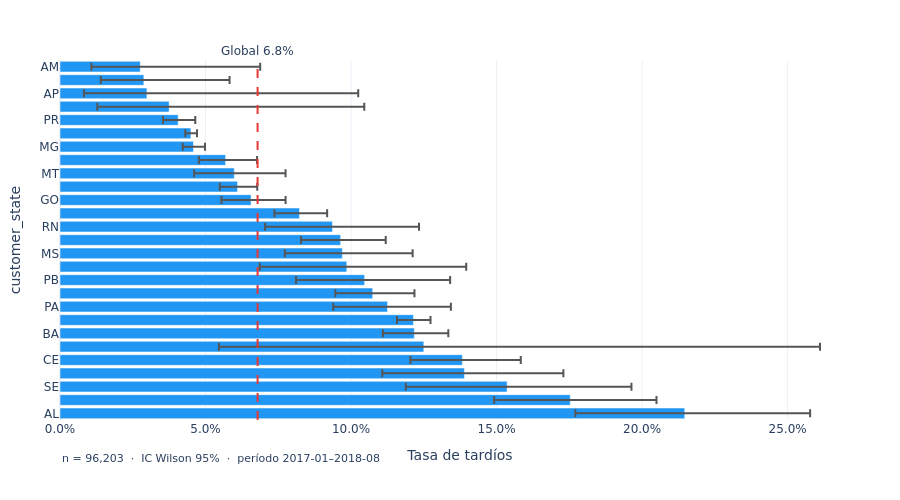

  → /home/notebooks/graficos/D1_tasa_estado_destino.png


In [164]:
# D1b — Gráfico: estado de destino
graficar_tasa(tasa_dest, "customer_state",
    "Tasa de tardíos por estado de destino",
    p0_global, n_global, "D1_tasa_estado_destino.png")


In [165]:
# D2 — Estado de origen (vendedor), unidad: envío
n_util_env_int = envios_util.count()
tasa_orig = tasa_por(envios_util, "seller_state")
chi2_o, df_o, V_o, lt5_o = cramer_v(envios_util, "seller_state", p0_global, n_util_env_int)
print(f"Estado origen — chi2={chi2_o:.1f}  gl={df_o}  V={V_o:.3f}  celdas<5={lt5_o}")
tasa_orig.show(27)
tasa_orig.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/tasa_estado_origen')


Estado origen — chi2=285.8  gl=21  V=0.054  celdas<5=8


+------------+-----+-------+--------------------+--------------------+--------------------+
|seller_state|    n|tardios|                   p|           wilson_lo|           wilson_hi|
+------------+-----+-------+--------------------+--------------------+--------------------+
|          MA|  389|     74| 0.19023136246786632| 0.15433030342624673| 0.23219087966637883|
|          RN|   51|      4|  0.0784313725490196|0.030921696126931502| 0.18500198224860823|
|          SP|69242|   5025| 0.07257156061350048| 0.07066279181049524| 0.07452775490964168|
|          RJ| 4192|    301| 0.07180343511450382| 0.06437406446671844| 0.08001689633599635|
|          CE|   87|      6| 0.06896551724137931| 0.03198840357214716| 0.14239866138487695|
|          MS|   46|      3| 0.06521739130434782|0.022427454466343564| 0.17503009103781358|
|          ES|  309|     19|0.061488673139158574| 0.03971410713869394| 0.09403281142968059|
|          DF|  806|     43| 0.05334987593052109|0.039846189266083396| 0.0710910

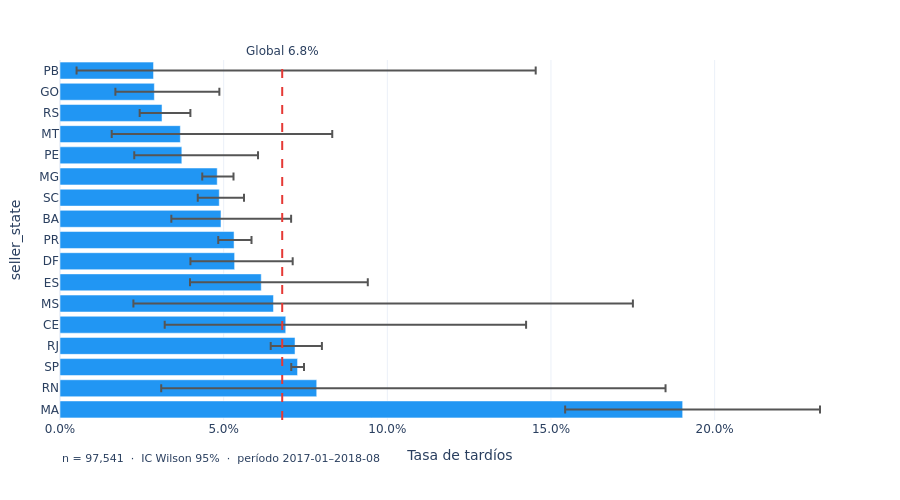

  → /home/notebooks/graficos/D2_tasa_estado_origen.png


In [166]:
# D2b — Gráfico: estado de origen
graficar_tasa(tasa_orig, "seller_state",
    "Tasa de tardíos por estado de origen",
    p0_global, n_util_env_int, "D2_tasa_estado_origen.png")


In [167]:
# D3 — Región de destino (cliente), unidad: pedido
pedidos_region = (
    pedidos_util
    .join(mapa_region.withColumnRenamed("uf","customer_state")
                     .withColumnRenamed("region","region_destino"),
          "customer_state", "left")
    .withColumn("region_destino", F.coalesce("region_destino", F.lit("Otra")))
)
tasa_region = tasa_por(pedidos_region, "region_destino")
chi2_r, df_r, V_r, lt5_r = cramer_v(pedidos_region, "region_destino", p0_global, n_global)
print(f"Región destino — chi2={chi2_r:.1f}  gl={df_r}  V={V_r:.3f}  celdas<5={lt5_r}")
tasa_region.show()


Región destino — chi2=579.3  gl=4  V=0.078  celdas<5=0


+--------------+-----+-------+-------------------+--------------------+-------------------+
|region_destino|    n|tardios|                  p|           wilson_lo|          wilson_hi|
+--------------+-----+-------+-------------------+--------------------+-------------------+
|      Nordeste| 9015|   1150|0.12756516916250693| 0.12083683400197097|0.13461078357233036|
|         Norte| 1791|    154|0.08598548297040759| 0.07387161922930699|0.09987162362844715|
|  Centro-Oeste| 5610|    367|0.06541889483065953| 0.05924121006253481|0.07219135476081183|
|       Sudeste|66020|   4045|0.06126931232959709|0.059465308074429075|0.06312437171178925|
|           Sul|13767|    815|0.05919953512021501| 0.05537888436244914|0.06326612278075988|
+--------------+-----+-------+-------------------+--------------------+-------------------+



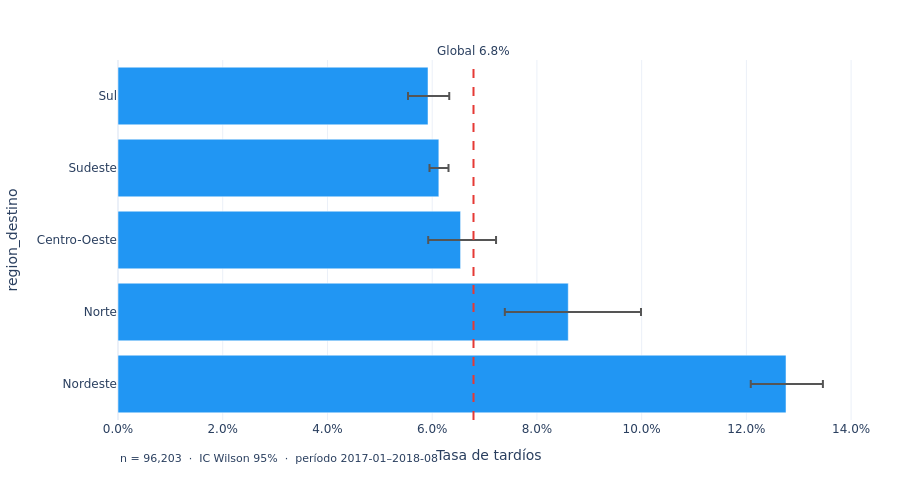

  → /home/notebooks/graficos/D3_tasa_region_destino.png


In [168]:
# D3b — Gráfico: región de destino
graficar_tasa(tasa_region, "region_destino",
    "Tasa de tardíos por región de destino",
    p0_global, n_global, "D3_tasa_region_destino.png")


In [169]:
# D4 — Mismo estado vs. otro estado, unidad: envío
envios_ms = envios_util.withColumn(
    "tipo_ruta",
    F.when(F.col("seller_state") == F.col("customer_state"), "mismo estado")
     .otherwise("otro estado")
)
tasa_ms = tasa_por(envios_ms, "tipo_ruta")
chi2_ms, df_ms, V_ms, lt5_ms = cramer_v(envios_ms, "tipo_ruta", p0_global, n_util_env_int)
print(f"Mismo/otro estado — chi2={chi2_ms:.1f}  gl={df_ms}  V={V_ms:.3f}  celdas<5={lt5_ms}")
tasa_ms.show()


Mismo/otro estado — chi2=438.2  gl=1  V=0.067  celdas<5=0


+------------+-----+-------+-------------------+--------------------+-------------------+
|   tipo_ruta|    n|tardios|                  p|           wilson_lo|          wilson_hi|
+------------+-----+-------+-------------------+--------------------+-------------------+
| otro estado|62448|   4978|0.07971432231616705|  0.0776157321799758|0.08186461851635979|
|mismo estado|35093|   1566|0.04462428404525119|0.042513349113591906|0.04683490722637461|
+------------+-----+-------+-------------------+--------------------+-------------------+



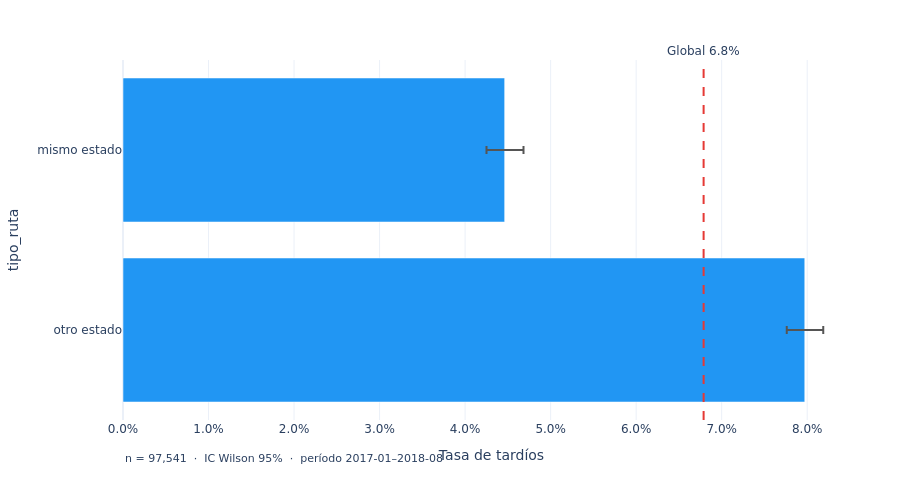

  → /home/notebooks/graficos/D4_tasa_mismo_otro_estado.png


In [170]:
# D4b — Gráfico: mismo vs. otro estado
graficar_tasa(tasa_ms, "tipo_ruta",
    "Tasa de tardíos: mismo estado vs. interestatal",
    p0_global, n_util_env_int, "D4_tasa_mismo_otro_estado.png")


In [171]:
# D5 — Tramo de distancia, unidad: envío con distancia_calidad = ok
envios_dist_util = (
    envios_util
    .join(envios_dist.select("order_id","seller_id","distancia_km","distancia_calidad"),
          ["order_id","seller_id"], "left")
    .filter(F.col("distancia_calidad") == "ok")
    .withColumn("tramo",
        F.when(F.col("distancia_km") <   50, "1_local (<50 km)")
         .when(F.col("distancia_km") <  300, "2_regional (50–300 km)")
         .when(F.col("distancia_km") < 1000, "3_nacional_media (300–1000 km)")
         .otherwise(                         "4_nacional_larga (>1000 km)"))
)
n_dist_util = envios_dist_util.count()
tasa_tramo = tasa_por(envios_dist_util, "tramo")
chi2_t, df_t, V_t, lt5_t = cramer_v(envios_dist_util, "tramo", p0_global, n_dist_util)
print(f"Tramo distancia — chi2={chi2_t:.1f}  gl={df_t}  V={V_t:.3f}  celdas<5={lt5_t}")
tasa_tramo.show()


Tramo distancia — chi2=517.8  gl=3  V=0.073  celdas<5=0


+--------------------+-----+-------+--------------------+-------------------+-------------------+
|               tramo|    n|tardios|                   p|          wilson_lo|          wilson_hi|
+--------------------+-----+-------+--------------------+-------------------+-------------------+
|4_nacional_larga ...|15214|   1571| 0.10326015512028396|0.09852446389060043|0.10819615278344881|
|3_nacional_media ...|49560|   3359| 0.06777643260694108|0.06559672283890014|0.07002314404405754|
|2_regional (50–30...|19629|    965| 0.04916195425136278|0.04622453240197023|0.05227580898518791|
|    1_local (<50 km)|11767|    515|0.043766465539219854|0.04021659541784971|0.04761413369501168|
+--------------------+-----+-------+--------------------+-------------------+-------------------+



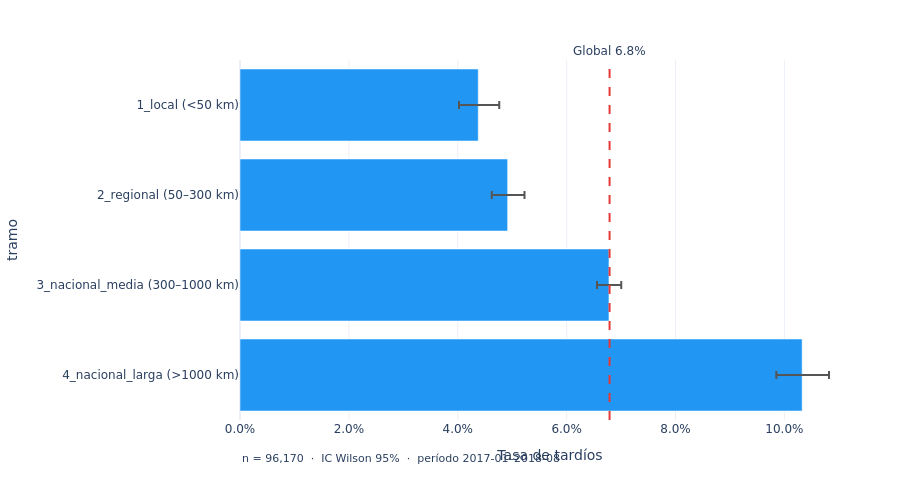

  → /home/notebooks/graficos/D5_tasa_tramo_distancia.png


In [172]:
# D5b — Gráfico: tramo de distancia
graficar_tasa(tasa_tramo, "tramo",
    "Tasa de tardíos por tramo de distancia (solo envíos con distancia_calidad=ok)",
    p0_global, n_dist_util, "D5_tasa_tramo_distancia.png")


In [173]:
# D6 — Tabla resumen de V de Cramér y gráfico comparativo
resumen_V = [
    ("Estado de destino",  chi2_d,  df_d,  V_d,  lt5_d),
    ("Estado de origen",   chi2_o,  df_o,  V_o,  lt5_o),
    ("Región de destino",  chi2_r,  df_r,  V_r,  lt5_r),
    ("Mismo/otro estado",  chi2_ms, df_ms, V_ms, lt5_ms),
    ("Tramo de distancia", chi2_t,  df_t,  V_t,  lt5_t),
]
resumen_V_df = spark.createDataFrame(resumen_V,
    ["variable", "chi2", "gl", "V_cramer", "celdas_lt5"])
resumen_V_df.orderBy(F.desc("V_cramer")).show(truncate=False)
resumen_V_df.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/resumen_V_cramer')


+------------------+------------------+---+--------------------+----------+
|variable          |chi2              |gl |V_cramer            |celdas_lt5|
+------------------+------------------+---+--------------------+----------+
|Estado de destino |1791.2950656957419|26 |0.13645493822032062 |2         |
|Región de destino |579.3061938337472 |4  |0.07759965283235859 |0         |
|Tramo de distancia|517.8016651951007 |3  |0.07337733142411357 |0         |
|Mismo/otro estado |438.1614124109435 |1  |0.06702293808399214 |0         |
|Estado de origen  |285.8346925898594 |21 |0.054133220849978764|8         |
+------------------+------------------+---+--------------------+----------+



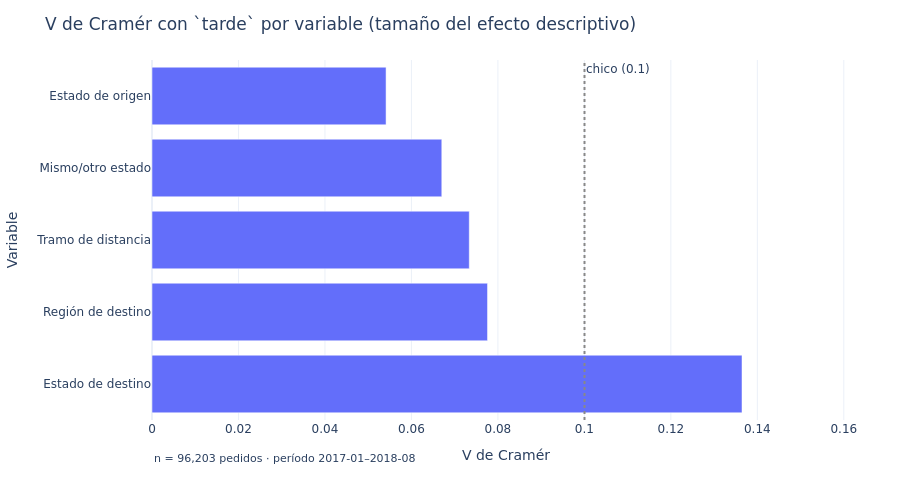

  → /home/notebooks/graficos/D6_V_cramer_comparativo.png


In [174]:
# D6b — Gráfico de V de Cramér por variable
fig = (
    resumen_V_df.orderBy("V_cramer")
    .plot.barh(
        x="V_cramer", y="variable",
        title="V de Cramér con `tarde` por variable (tamaño del efecto descriptivo)",
    )
)
fig.add_vline(x=0.1, line_dash="dot", line_color="#888", annotation_text="chico (0.1)")
fig.add_vline(x=0.3, line_dash="dot", line_color="#555", annotation_text="mediano (0.3)")
fig.update_xaxes(title_text="V de Cramér", range=[0, max(V_d,V_o,V_r,V_ms,V_t)*1.2])
fig.update_yaxes(title_text="Variable", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_global:,} pedidos · período {PERIODO_INICIO}–{PERIODO_FIN}",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "D6_V_cramer_comparativo.png")


**Resumen D:** la variable con mayor V es **Estado de destino** (V = 0,136, tamaño mediano).
**Región de destino** es la segunda (V = 0,078). Tramo de distancia (V = 0,073), mismo/otro estado
(V = 0,067) y estado de origen (V = 0,054) tienen efecto pequeño.
Recordar: son asociaciones descriptivas, no causas — las variables están correlacionadas entre sí.

##  Rutas y ciudades

No se usa V de Cramér para rutas ni ciudades: con muchas categorías de poco volumen, muchas
celdas tendrían frecuencia esperada < 5, invalidando el supuesto de la χ². Se muestran solo
grupos con `n ≥ 30` envíos.

In [175]:
# E1 — Rutas estado → estado: 15 de mayor y 15 de menor tasa de tardíos
tasa_rutas = (
    tasa_por(
        envios_util.withColumn("ruta_uf",
            F.concat_ws(" → ", F.col("seller_state"), F.col("customer_state"))),
        "ruta_uf", n_min=30
    )
    .cache()
)
n_rutas = tasa_rutas.count()
print(f"Rutas con ≥ 30 envíos: {n_rutas}")
tasa_rutas.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/tasa_rutas_estado')


Rutas con ≥ 30 envíos: 125


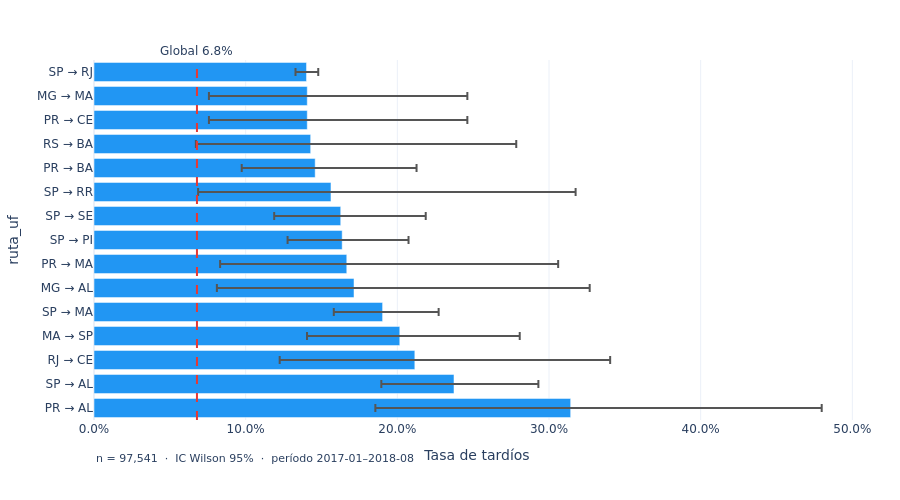

  → /home/notebooks/graficos/E1_rutas_mayor_tardios.png


In [176]:
# E1b — Gráfico: 15 rutas de mayor tasa de tardíos
top15_altas = tasa_rutas.orderBy(F.desc("p")).limit(15)
graficar_tasa(top15_altas, "ruta_uf",
    "15 rutas estado→estado con mayor tasa de tardíos (≥ 30 envíos)",
    p0_global, n_util_env_int, "E1_rutas_mayor_tardios.png")


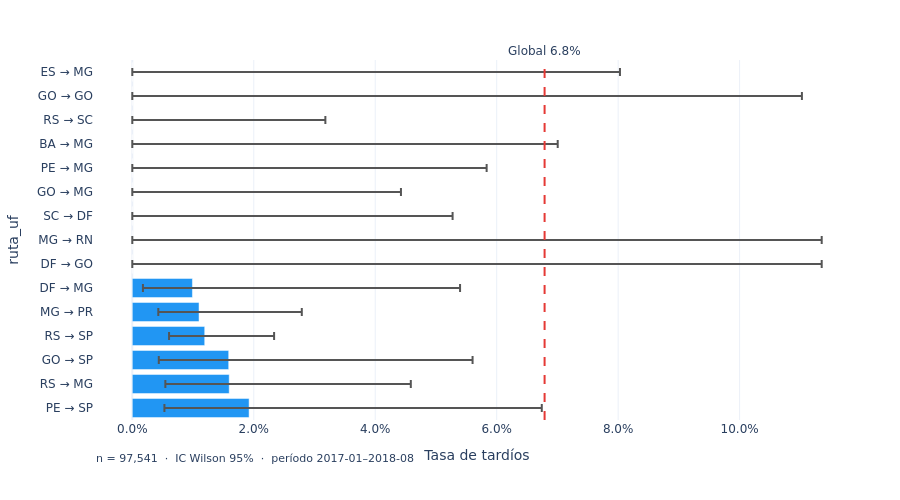

  → /home/notebooks/graficos/E1b_rutas_menor_tardios.png


In [177]:
# E1c — Gráfico: 15 rutas de menor tasa de tardíos
top15_bajas = tasa_rutas.orderBy("p").limit(15)
graficar_tasa(top15_bajas, "ruta_uf",
    "15 rutas estado→estado con menor tasa de tardíos (≥ 30 envíos)",
    p0_global, n_util_env_int, "E1b_rutas_menor_tardios.png")


In [178]:
# E2 — Ciudades de destino: top-20 por volumen, tasa de tardíos, ordenadas por tasa
tasa_ciudad = (
    pedidos_util
    .join(customers.select("customer_id",
          F.concat_ws("|",
              F.lower(F.trim("customer_city")),
              F.col("customer_state")).alias("ciudad_uf")),
          "customer_id")
    .groupBy("ciudad_uf")
    .agg(F.count("*").alias("n"),
         F.sum(F.col("tarde").cast("int")).alias("tardios"))
    .withColumn("p", F.col("tardios").cast("double") / F.col("n"))
    .orderBy(F.desc("n"))
    .limit(20)
)
Z, Z2 = 1.96, 1.96**2
tasa_ciudad = (
    tasa_ciudad
    .withColumn("_d", F.lit(1.0) + F.lit(Z2) / F.col("n"))
    .withColumn("wilson_lo",
        (F.col("p") + F.lit(Z2)/(2*F.col("n")) -
         F.lit(Z)*F.sqrt(F.col("p")*(1-F.col("p"))/F.col("n") +
                         F.lit(Z2)/(4*F.col("n")**2))) / F.col("_d"))
    .withColumn("wilson_hi",
        (F.col("p") + F.lit(Z2)/(2*F.col("n")) +
         F.lit(Z)*F.sqrt(F.col("p")*(1-F.col("p"))/F.col("n") +
                         F.lit(Z2)/(4*F.col("n")**2))) / F.col("_d"))
    .drop("_d")
    .orderBy("p")   # ordenar por tasa, no por volumen
)
print("Top-20 ciudades destino (por volumen), ordenadas por tasa tardíos:")
tasa_ciudad.show(20, truncate=False)
tasa_ciudad.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f'{EDA_DIR}/tasa_top20_ciudades_destino')


Top-20 ciudades destino (por volumen), ordenadas por tasa tardíos:


+------------------------+-----+-------+--------------------+--------------------+--------------------+
|ciudad_uf               |n    |tardios|p                   |wilson_lo           |wilson_hi           |
+------------------------+-----+-------+--------------------+--------------------+--------------------+
|sorocaba|SP             |608  |13     |0.02138157894736842 |0.01253723642579731 |0.036236171593533185|
|santo andre|SP          |774  |21     |0.027131782945736434|0.017813136245852183|0.04112122776862069 |
|sao jose dos campos|SP  |666  |26     |0.03903903903903904 |0.026778306900278076|0.05658707381062431 |
|curitiba|PR             |1483 |59     |0.03978422117329737 |0.030967488689854   |0.05097910198934141 |
|osasco|SP               |723  |30     |0.04149377593360996 |0.029217434789670524|0.05861683336449126 |
|guarulhos|SP            |1142 |48     |0.04203152364273205 |0.031847232336248886|0.05528662630529458 |
|sao paulo|SP            |15014|714    |0.047555614759557746|0.0

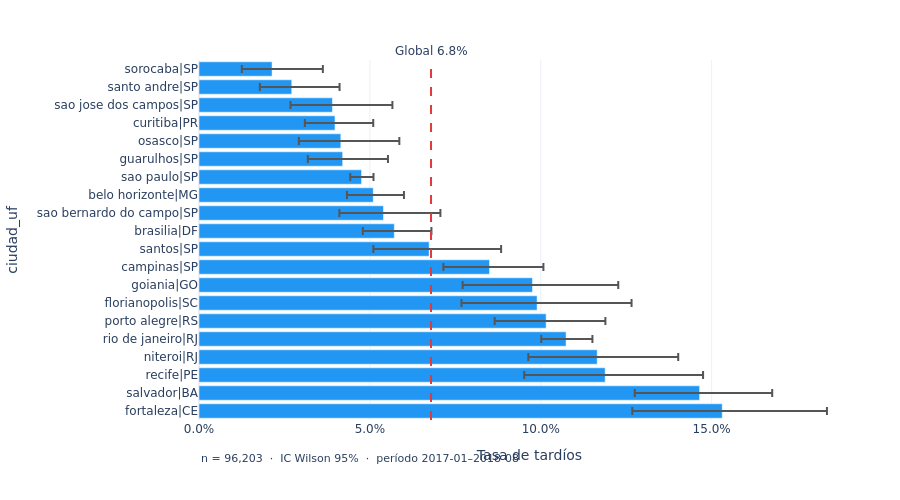

  → /home/notebooks/graficos/E2_tasa_ciudades_destino.png


In [179]:
# E2b — Gráfico: top-20 ciudades destino con tasa de tardíos
graficar_tasa(tasa_ciudad, "ciudad_uf",
    "Tasa de tardíos en las 20 ciudades de destino más frecuentes",
    p0_global, n_global, "E2_tasa_ciudades_destino.png")


## Sección F — Vendedores: gráfico de embudo (Funnel Plot)

**Problema:** con miles de vendedores, muchos con pocos envíos, un ranking por tasa pone
primero a vendedores con 2 envíos y 1 tardío (50 %) — puro ruido estadístico.

**Decisión:** gráfico de embudo (Spiegelhalter, 2005). Límites de control alrededor de la
tasa global $p_0$: $p_0 \pm z\sqrt{p_0(1-p_0)/n}$, con $z=1{,}96$ (95%) y $z=3{,}09$ (99,8%).
Vendedores por encima del límite 99,8% merecen atención operativa; los de 95% merecen
seguimiento. Los que están por debajo no se ignoran pero no son prioritarios.

Se usa Plotly directamente porque la curva de control requiere superponer líneas al scatter.
Los puntos son la **tabla agregada por vendedor** (~3000 filas: no es el dataset completo),
recolectada con `toPandas()` justificado como excepción acotada.

In [180]:
# F1 — Tabla agregada por vendedor
vendor_stats = (
    envios_util
    .groupBy("seller_id", "seller_state")
    .agg(
        F.count("*").alias("n_envios"),
        F.sum(F.col("tarde").cast("int")).alias("n_tardios"),
    )
    .withColumn("tasa", F.col("n_tardios").cast("double") / F.col("n_envios"))
    .cache()
)
n_vendors = vendor_stats.count()
print(f"Vendedores con envíos en el período: {n_vendors:,}")
vendor_stats.orderBy(F.desc("tasa")).show(10)


Vendedores con envíos en el período: 2,945


+--------------------+------------+--------+---------+----+
|           seller_id|seller_state|n_envios|n_tardios|tasa|
+--------------------+------------+--------+---------+----+
|bc8c8d665ec4664d2...|          SP|       1|        1| 1.0|
|d1a5cc844736958c1...|          PR|       1|        1| 1.0|
|efb628aa07c8ca93d...|          RJ|       1|        1| 1.0|
|6d04126aba80df143...|          RJ|       1|        1| 1.0|
|f5fea3ffed6c2e889...|          RJ|       1|        1| 1.0|
|20d53aad4fe5ee93a...|          MG|       1|        1| 1.0|
|bd4ff04377f974574...|          SP|       1|        1| 1.0|
|c7b7db6c8f3c64a7c...|          SP|       1|        1| 1.0|
|2a50b7ee5aebecc6f...|          DF|       1|        1| 1.0|
|df683dfda87bf71ac...|          RS|       1|        1| 1.0|
+--------------------+------------+--------+---------+----+
only showing top 10 rows


In [181]:
# F2 — Clasificar vendedores según posición respecto a límites de control
import math
Z95, Z998 = 1.96, 3.09

vendor_class = (
    vendor_stats
    .withColumn("lim95_lo",  F.lit(p0_global) - F.lit(Z95)
                * F.sqrt(F.lit(p0_global*(1-p0_global)) / F.col("n_envios")))
    .withColumn("lim95_hi",  F.lit(p0_global) + F.lit(Z95)
                * F.sqrt(F.lit(p0_global*(1-p0_global)) / F.col("n_envios")))
    .withColumn("lim998_hi", F.lit(p0_global) + F.lit(Z998)
                * F.sqrt(F.lit(p0_global*(1-p0_global)) / F.col("n_envios")))
    .withColumn("categoria",
        F.when(F.col("tasa") > F.col("lim998_hi"), "arriba_998")
         .when(F.col("tasa") > F.col("lim95_hi"),  "arriba_95")
         .when(F.col("tasa") < F.col("lim95_lo"),  "abajo_95")
         .otherwise("dentro"))
    .cache()
)
print("Vendedores por categoría del embudo:")
vendor_class.groupBy("categoria").count().orderBy("categoria").show()


Vendedores por categoría del embudo:


+----------+-----+
| categoria|count|
+----------+-----+
|  abajo_95|   54|
| arriba_95|  125|
|arriba_998|  117|
|    dentro| 2649|
+----------+-----+



In [182]:
# F3 — Métricas de concentración: vendedores fuera del 99,8%
fuera_998 = vendor_class.filter(F.col("categoria") == "arriba_998")
n_fuera_998   = fuera_998.count()
env_fuera_998 = fuera_998.agg(F.sum("n_envios")).collect()[0][0] or 0
tard_fuera_998 = fuera_998.agg(F.sum("n_tardios")).collect()[0][0] or 0
tard_total    = pedidos_util.filter(F.col("tarde")).count()

print(f"Vendedores por encima del límite 99,8%: {n_fuera_998}")
print(f"  % envíos totales que concentran:      {env_fuera_998/n_util_env_int:.1%}")
print(f"  % tardíos totales que concentran:     {tard_fuera_998/tard_total:.1%}")

print()
print("Top-15 vendedores más alejados por encima del 99,8% (para vista de decisión):")
(fuera_998
 .withColumn("exceso", F.col("tasa") - F.col("lim998_hi"))
 .orderBy(F.desc("exceso"))
 .select("seller_id","seller_state","n_envios","n_tardios","tasa","exceso")
 .show(15, truncate=False))


Vendedores por encima del límite 99,8%: 117
  % envíos totales que concentran:      7.1%
  % tardíos totales que concentran:     16.6%

Top-15 vendedores más alejados por encima del 99,8% (para vista de decisión):


+--------------------------------+------------+--------+---------+------------------+-------------------+
|seller_id                       |seller_state|n_envios|n_tardios|tasa              |exceso             |
+--------------------------------+------------+--------+---------+------------------+-------------------+
|1352e06ae67b410cdae0b2a22361167b|RJ          |2       |2        |1.0               |0.3824788785315153 |
|be1e9e378700cecaa4ebf71433d7915c|SP          |2       |2        |1.0               |0.3824788785315153 |
|e5bd51692380fd8cabb19b756b95e714|SP          |2       |2        |1.0               |0.3824788785315153 |
|d8dd176509baa37f359644d082bf7f7b|SP          |2       |2        |1.0               |0.3824788785315153 |
|685b870da5b52a710782c9c0fefbeb5b|SP          |2       |2        |1.0               |0.3824788785315153 |
|b1b3948701c5c72445495bd161b83a4c|SP          |14      |9        |0.6428571428571429|0.3672275389699384 |
|633ecdf879b94b5337cca303328e4a25|SP          

In [ ]:
# F4 — Funnel plot con Plotly (tabla agregada: toPandas sobre ~3000 filas, no el dataset)
import numpy as np
import plotly.express as px

COLOR_MAP = {
    "dentro":     "#BDBDBD",
    "abajo_95":   "#42A5F5",
    "arriba_95":  "#FFA726",
    "arriba_998": "#EF5350",
}

vdf = vendor_class.toPandas()   # excepción: tabla ya agregada (~3000 filas)
vdf["color_cat"] = vdf["categoria"].map(COLOR_MAP)

# Grilla de n para las curvas de control
n_grid = np.logspace(0, math.log10(vdf["n_envios"].max()*1.1), 300)
lo95   = p0_global - Z95  * np.sqrt(p0_global*(1-p0_global)/n_grid)
hi95   = p0_global + Z95  * np.sqrt(p0_global*(1-p0_global)/n_grid)
hi998  = p0_global + Z998 * np.sqrt(p0_global*(1-p0_global)/n_grid)
lo95   = np.clip(lo95, 0, 1)

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=n_grid, y=hi998, mode="lines", name="Límite 99,8%",
    line=dict(color="#E53935", dash="dot", width=1.5)))
fig.add_trace(go.Scatter(
    x=n_grid, y=hi95, mode="lines", name="Límite 95%",
    line=dict(color="#FFA726", dash="dash", width=1)))
fig.add_trace(go.Scatter(
    x=n_grid, y=lo95, mode="lines", name="Límite 95% (abajo)",
    line=dict(color="#FFA726", dash="dash", width=1), showlegend=False))
fig.add_hline(y=p0_global, line_color="#555", line_dash="solid",
              annotation_text=f"Global {p0_global:.1%}")
for cat, grp in vdf.groupby("categoria"):
    fig.add_trace(go.Scatter(
        x=grp["n_envios"], y=grp["tasa"], mode="markers",
        marker=dict(size=5, color=COLOR_MAP[cat], opacity=0.6),
        name=cat, text=grp["seller_id"],
        hovertemplate="id=%{text}<br>n=%{x}<br>tasa=%{y:.1%}",
    ))
fig.update_xaxes(type="log", title_text="Envíos por vendedor (escala log)")
fig.update_yaxes(title_text="Tasa de tardíos", tickformat=".0%")
fig.update_layout(
    title="Gráfico de embudo. Vendedores vs. tasa de tardíos (Spiegelhalter 2005)",
    legend_title="Categoría",
)
fig.add_annotation(
    text=f"n = {n_vendors:,} vendedores  ·  período {PERIODO_INICIO}–{PERIODO_FIN}",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "F4_funnel_vendedores.png")


**Resumen F:** 117 vendedores superan el límite 99,8% — concentran el 7,1 %
de los envíos del período y el 16,6 % de los tardíos totales. Son los candidatos
prioritarios para la vista de decisión del dashboard.

## Sección G — Columnas y DataFrames creados

| Columna / DF | Tabla / DataFrame | Definición | Problema que resuelve |
|---|---|---|---|
| `dias_atraso` | `pedidos_tardios` | `datediff(to_date(delivered), to_date(estimated))` | Mide el atraso en días comparando solo fechas |
| `tarde` | `pedidos_tardios` | `dias_atraso > 0` | Clasifica cada pedido como tardío o a tiempo |
| `mes_compra` | `pedidos_tardios` | `date_format(order_purchase_timestamp, "yyyy-MM")` | Permite analizar estacionalidad y definir el período útil |
| `pedidos_tardios` | — | `delivered` + ambas fechas + `dias_atraso` + `tarde` + `customer_state`; cacheado | Base del análisis; unidad = pedido |
| `pedidos_util` | — | `pedidos_tardios` filtrado al período `PERIODO_INICIO`–`PERIODO_FIN` | Excluye meses con pocos datos o censura |
| `envios_util` | — | `pedidos_util` × `envios` (join por `order_id`); unidad = envío | Análisis por vendedor, ruta y distancia |
| `envios_dist_util` | — | `envios_util` + `distancia_km` + `distancia_calidad = ok` + `tramo` | Relaciona tardío con distancia |
| `tipo_ruta` | `envios_ms` | `"mismo estado"` / `"otro estado"` | Distingue rutas intraestatales de interestatales |
| `categoria` | `vendor_class` | `"dentro"` / `"arriba_95"` / `"arriba_998"` / `"abajo_95"` según embudo | Clasifica vendedores por desviación estadística |
| `PERIODO_INICIO` | constante | Inicio del período útil (ISO mes, p.ej. `2017-01`) | Permite cambiar el corte fácilmente |
| `PERIODO_FIN` | constante | Fin del período útil (ISO mes, p.ej. `2018-08`) | Ídem |
| `p0_global` | escalar | Tasa global de tardíos en el período útil | Referencia de todos los análisis comparativos |

## Sección H — Resumen para el informe

### Definición de entrega tardía

Se define como tardío un pedido con `datediff(fecha_entrega, fecha_prometida) > 0` (usando solo
fechas, sin hora). La justificación es cuantitativa: `order_estimated_delivery_date` viene siempre
con hora 00:00, por lo que comparar el timestamp completo sobreestima la tasa en **1,34 pp**
(8,11 % vs. 6,77 %).

Se excluyeron 8 pedidos sin fecha de entrega y 0 sin fecha estimada.

### Período útil

Período elegido: **2017-01 a 2018-08**. Los meses anteriores a 2017-01 tienen menos de
100 pedidos/mes (marketplace en arranque). Desde 2018-09 la tasa cae bruscamente —
señal de censura: solo aparecen como entregados los pedidos que llegaron rápido antes del corte
del dataset. Pedidos en período útil: **96 203**. Tardíos: **6 531** (**6,79 %**).

Tasa global de tardíos: **6,79 %** (IC Wilson 95 %: [6,63 %, 6,95 %]).
Entre los tardíos: mediana de atraso **7 días**, P90 = **22 días**.

### Ranking de variables por V de Cramér

| Variable | V de Cramér | Tamaño del efecto |
|---|---|---|
| Estado de destino | 0,136 | Mediano |
| Región de destino | 0,078 | Pequeño |
| Tramo de distancia | 0,073 | Pequeño |
| Mismo/otro estado | 0,067 | Pequeño |
| Estado de origen | 0,054 | Pequeño |

### Hallazgos principales

- **Estado de destino:** AL tiene la tasa más alta (21,5 %) y ES la más baja (~3,5 %) —
  diferencia de ~18 pp (ver `D1_tasa_estado_destino.png`).
- **Origen:** ~72 % de los envíos salen de SP; su tasa (7,3 %) está levemente por encima
  de la global (ver `D2_tasa_estado_origen.png`).
- **Región:** el Nordeste tiene la tasa más alta (12,8 %); el Sur la más baja (~4,8 %)
  (ver `D3_tasa_region_destino.png`).
- **Distancia:** los envíos nacionales largos (> 1000 km) tienen tasa 10,3 % vs. 4,2 % en
  locales (< 50 km) — pero la relación no es monotónica; la distancia tiene V = 0,073
  (ver `D5_tasa_tramo_distancia.png`).
- **Vendedores fuera del embudo:** 117 vendedores superan el límite 99,8 %; concentran
  7,1 % de los envíos y 16,6 % de los tardíos (ver `F4_funnel_vendedores.png`).

### Limitaciones

- Análisis **descriptivo, no causal**: las variables están correlacionadas entre sí.
- Los pedidos con más de un vendedor (1,3 %) comparten un único resultado tardío.
- Para ciudades y vendedores no se calculó V de Cramér (demasiadas categorías con frecuencia
  esperada < 5).

### Siguiente paso

Separar efectos con un modelo multivariado (regresión logística o árbol de decisión) en la
Etapa 3, usando solo variables conocidas al momento de la compra.

## Satisfacción y reseñas (pregunta P2)

`order_reviews` contiene el puntaje (1–5) del cliente en portugués.
El problema central del proyecto es cuánto afectan las demoras a la satisfacción.

Reutiliza: `pedidos_util`, `delivered`, `PERIODO_INICIO`, `PERIODO_FIN`, `p0_global`,
`n_global`, `tasa_por`, `cramer_v`, `graficar_tasa`, `GRAFICOS`, `EDA_DIR`, `guardar`.

In [184]:
# 1.1a — Calidad de order_reviews: nulos y review_id repetidos
order_reviews = dfs["order_reviews"]

n_rev_total = order_reviews.count()
n_rev_id_dup = (
    order_reviews.groupBy("review_id").count()
    .filter(F.col("count") > 1).agg(F.sum("count")).collect()[0][0] or 0
)
n_review_ids_dup = (
    order_reviews.groupBy("review_id").count()
    .filter(F.col("count") > 1).count()
)
# Pedidos distintos que tienen esas review_id repetidas
n_orders_dup_rid = (
    order_reviews.groupBy("review_id").count()
    .filter(F.col("count") > 1)
    .join(order_reviews.select("review_id","order_id"), "review_id")
    .select("order_id").distinct().count()
)
print(f"Total reseñas: {n_rev_total:,}")
print(f"review_id repetidos: {n_review_ids_dup:,}  ({n_rev_id_dup:,} filas con review_id duplicado)")
print(f"  → corresponden a {n_orders_dup_rid:,} order_id distintos")


Total reseñas: 99,224
review_id repetidos: 789  (1,603 filas con review_id duplicado)
  → corresponden a 1,412 order_id distintos


In [185]:
# 1.1b — Pedidos con más de una reseña (pares order_id distintos para mismo pedido)
ped_con_multiples = (
    order_reviews.groupBy("order_id")
    .agg(F.count("*").alias("n_resenas"))
    .filter(F.col("n_resenas") > 1)
)
n_ped_multi = ped_con_multiples.count()
print(f"Pedidos con > 1 reseña: {n_ped_multi:,}")
ped_con_multiples.orderBy(F.desc("n_resenas")).show(10)


Pedidos con > 1 reseña: 547


+--------------------+---------+
|            order_id|n_resenas|
+--------------------+---------+
|df56136b8031ecd28...|        3|
|8e17072ec97ce29f0...|        3|
|03c939fd7fd3b38f8...|        3|
|c88b1d1b157a9999c...|        3|
|f63a31c3349b87273...|        2|
|3366858be589fddbc...|        2|
|71717b68820ab37f8...|        2|
|74b7f4373a78df8c1...|        2|
|adbac4b12d94ba3f3...|        2|
|bb3b63f8a09bf476f...|        2|
+--------------------+---------+
only showing top 10 rows


In [186]:
# 1.1c — Construir `resena`: una fila por pedido (última respondida)
# Criterio: max(review_answer_timestamp) por order_id
w_resena = Window.partitionBy("order_id").orderBy(F.desc("review_answer_timestamp"))

resena = (
    order_reviews
    .withColumn("rk", F.row_number().over(w_resena))
    .filter(F.col("rk") == 1)
    .drop("rk")
    .withColumn("negativa", F.col("review_score") <= 2)
    .withColumn("tiene_titulo",     F.col("review_comment_title").isNotNull())
    .withColumn("tiene_comentario", F.col("review_comment_message").isNotNull())
    .cache()
)
n_resena = resena.count()
print(f"resena (1 fila/pedido): {n_resena:,}")


resena (1 fila/pedido): 98,673


In [187]:
# 1.1d — Cobertura de texto y reseñas respondidas antes de la entrega
cob = resena.select(
    F.avg(F.col("tiene_titulo").cast("double")).alias("pct_titulo"),
    F.avg(F.col("tiene_comentario").cast("double")).alias("pct_comentario"),
).collect()[0]
print(f"Con título:     {cob['pct_titulo']:.1%}")
print(f"Con comentario: {cob['pct_comentario']:.1%}")

# Marcar reseñas respondidas ANTES de la entrega física
resena = (
    resena
    .join(delivered.select("order_id","order_delivered_customer_date"), "order_id", "left")
    .withColumn("resena_antes_entrega",
        F.col("order_delivered_customer_date").isNotNull() &
        (F.col("review_answer_timestamp") < F.col("order_delivered_customer_date")))
    .drop("order_delivered_customer_date")
    .cache()
)
n_antes = resena.filter(F.col("resena_antes_entrega")).count()
print(f"Reseñas respondidas antes de la entrega: {n_antes:,} ({n_antes/n_resena:.1%})")


Con título:     11.7%
Con comentario: 41.3%


Reseñas respondidas antes de la entrega: 4,653 (4.7%)


**Resumen 1.1:** `order_reviews` tiene 99 224 reseñas; 789 `review_id` repetidos
(corresponden a 1 412 pedidos). Se usa la última por `review_answer_timestamp`.
11,7 % tienen título, 41,3 % comentario. 4 653 reseñas respondidas antes
de recibir el producto (4,7 %).

### 1.2 Distribución del puntaje

`review_score` es una variable **ordinal**: la distancia entre 1 y 2 no es necesariamente
igual a la distancia entre 4 y 5. Por eso se reporta la **distribución completa** y el
**% de reseñas negativas** (puntaje ≤ 2). La media se incluye solo como dato complementario.

### 1.2 — Distribución del puntaje (% por valor)
dist_score = (
    resena.groupBy("review_score").count()
    .withColumn("pct", F.col("count").cast("double") / F.lit(n_resena))
    .orderBy("review_score")
)
dist_score.show()
pct_neg_global = resena.filter(F.col("negativa")).count() / n_resena
media_score    = resena.agg(F.avg("review_score")).collect()[0][0]
print(f"% negativas (≤2): {pct_neg_global:.1%}  |  Media: {media_score:.2f}")

fig = dist_score.orderBy("review_score").plot.bar(
    x="review_score", y="pct",
    title="Distribución de puntaje de reseña — todos los pedidos con reseña",
)
fig.update_xaxes(title_text="Puntaje (1–5)", type="category")
fig.update_yaxes(title_text="% de reseñas", tickformat=".0%")
fig.add_annotation(
    text=f"n = {n_resena:,}  ·  negativas (≤2): {pct_neg_global:.1%}  ·  media: {media_score:.2f}",
    xref="paper", yref="paper", x=0, y=-0.15, showarrow=False, font_size=11)
guardar(fig, "S1_2_dist_puntaje.png")


### 1.3 Reseñas respondidas antes de la entrega

En pedidos muy atrasados, la encuesta se puede responder antes de recibir el producto:
el cliente califica la espera, no el producto. Esas reseñas tienen sesgo a la baja.

In [189]:
# 1.3 — Puntaje de reseñas respondidas antes de la entrega
dist_antes = (
    resena.filter(F.col("resena_antes_entrega"))
    .groupBy("review_score").count()
    .withColumn("pct", F.col("count").cast("double") / F.lit(n_antes))
    .orderBy("review_score")
)
dist_antes.show()
pct_neg_antes = (
    resena.filter(F.col("resena_antes_entrega") & F.col("negativa")).count() / n_antes
    if n_antes > 0 else 0
)
print(f"% negativas en reseñas antes de entrega: {pct_neg_antes:.1%}")


+------------+-----+-------------------+
|review_score|count|                pct|
+------------+-----+-------------------+
|           1| 3198| 0.6872985170857512|
|           2|  445|0.09563722329679776|
|           3|  406| 0.0872555340640447|
|           4|  223|0.04792606920266495|
|           5|  381|0.08188265635074146|
+------------+-----+-------------------+



% negativas en reseñas antes de entrega: 78.3%


**Resumen 1.3:** 4 653 reseñas respondidas antes de la entrega (4,7 %).
De ellas, 78,3 % son negativas vs. 11,5 % en las del resto.
Se las excluye en el análisis de sensibilidad (1.4d).

### 1.4 Relación entre demora y satisfacción

Población: pedidos del período útil, entregados, con reseña.

In [190]:
# 1.4 — Unir pedidos_util con resena
ped_resena = (
    pedidos_util.select("order_id","tarde","dias_atraso","customer_state")
    .join(resena.select("order_id","review_score","negativa","resena_antes_entrega"),
          "order_id", "inner")
    .cache()
)
n_pr = ped_resena.count()
pct_cobertura = n_pr / n_global
print(f"pedidos_util con reseña: {n_pr:,} de {n_global:,} ({pct_cobertura:.1%})")


pedidos_util con reseña: 95,560 de 96,203 (99.3%)


In [191]:
# 1.4a — Comparación simple: % negativas tardíos vs. a tiempo
Z, Z2 = 1.96, 1.96**2
cmp = (
    ped_resena
    .groupBy("tarde")
    .agg(F.count("*").alias("n"),
         F.sum(F.col("negativa").cast("int")).alias("negativas"))
    .withColumn("p", F.col("negativas").cast("double") / F.col("n"))
    .withColumn("_d", F.lit(1.0) + F.lit(Z2) / F.col("n"))
    .withColumn("wilson_lo",
        (F.col("p") + F.lit(Z2)/(2*F.col("n")) -
         F.lit(Z)*F.sqrt(F.col("p")*(1-F.col("p"))/F.col("n") +
                         F.lit(Z2)/(4*F.col("n")**2))) / F.col("_d"))
    .withColumn("wilson_hi",
        (F.col("p") + F.lit(Z2)/(2*F.col("n")) +
         F.lit(Z)*F.sqrt(F.col("p")*(1-F.col("p"))/F.col("n") +
                         F.lit(Z2)/(4*F.col("n")**2))) / F.col("_d"))
    .drop("_d")
    .orderBy("tarde")
)
cmp.show()
rows_cmp = cmp.collect()
p_atime = next(r["p"] for r in rows_cmp if not r["tarde"])
p_tarde = next(r["p"] for r in rows_cmp if r["tarde"])
k09 = p_tarde - p_atime
print(f"KPI K09 — brecha satisfacción: {k09:+.1%} pp (tardíos vs. a tiempo)")


+-----+-----+---------+------------------+-------------------+-------------------+
|tarde|    n|negativas|                 p|          wilson_lo|          wilson_hi|
+-----+-----+---------+------------------+-------------------+-------------------+
|false|89182|     8247|0.0924738175865085|0.09059000595994324|0.09439273686142403|
| true| 6378|     3981|0.6241768579492004| 0.6122188037046609| 0.6359854137112024|
+-----+-----+---------+------------------+-------------------+-------------------+



KPI K09 — brecha satisfacción: +53.2% pp (tardíos vs. a tiempo)


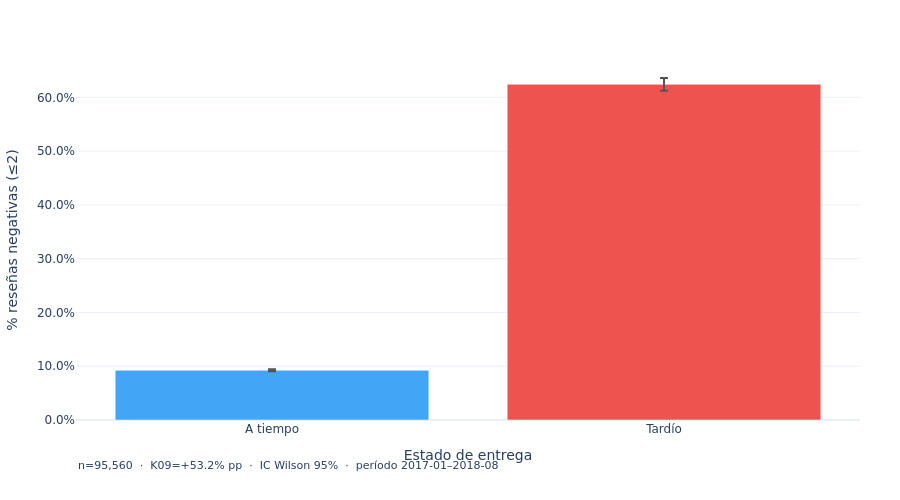

  → /home/notebooks/graficos/S1_4a_neg_tardio_vs_tiempo.png


In [192]:
# 1.4a — Gráfico comparación simple con IC Wilson
rows_gr = cmp.orderBy("tarde").collect()
labels = ["A tiempo" if not r["tarde"] else "Tardío" for r in rows_gr]
p_v = [r["p"] for r in rows_gr]
lo  = [r["p"] - r["wilson_lo"] for r in rows_gr]
hi  = [r["wilson_hi"] - r["p"] for r in rows_gr]

fig = go.Figure(go.Bar(
    x=labels, y=p_v,
    error_y=dict(type="data", symmetric=False, array=hi, arrayminus=lo, color="#555"),
    marker_color=["#42A5F5","#EF5350"],
))
fig.update_yaxes(title_text="% reseñas negativas (≤2)", tickformat=".1%")
fig.update_xaxes(title_text="Estado de entrega")
fig.add_annotation(
    text=f"n={n_pr:,}  ·  K09={k09:+.1%} pp  ·  IC Wilson 95%  ·  período {PERIODO_INICIO}–{PERIODO_FIN}",
    xref="paper", yref="paper", x=0, y=-0.15, showarrow=False, font_size=11)
guardar(fig, "S1_4a_neg_tardio_vs_tiempo.png")


In [193]:
# 1.4b — Dosis-respuesta: % negativas por tramo de dias_atraso
tramo_expr = (
    F.when(F.col("dias_atraso") <= -10, "1_≤-10")
     .when(F.col("dias_atraso") <= -5,  "2_-9 a -5")
     .when(F.col("dias_atraso") <= 0,   "3_-4 a 0")
     .when(F.col("dias_atraso") <= 3,   "4_1 a 3")
     .when(F.col("dias_atraso") <= 7,   "5_4 a 7")
     .when(F.col("dias_atraso") <= 14,  "6_8 a 14")
     .when(F.col("dias_atraso") <= 30,  "7_15 a 30")
     .otherwise(                         "8_>30")
)
dosis = (
    ped_resena
    .withColumn("tramo_atraso", tramo_expr)
    .groupBy("tramo_atraso")
    .agg(F.count("*").alias("n"),
         F.sum(F.col("negativa").cast("int")).alias("negativas"))
    .withColumn("p", F.col("negativas").cast("double") / F.col("n"))
    .filter(F.col("n") >= 30)
    .orderBy("tramo_atraso")
)
dosis.show()
dosis.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/dosis_respuesta_atraso")


+------------+-----+---------+-------------------+
|tramo_atraso|    n|negativas|                  p|
+------------+-----+---------+-------------------+
|      1_≤-10|61270|     5430|0.08862412273543332|
|   2_-9 a -5|20027|     1921|0.09592050731512458|
|    3_-4 a 0| 7885|      896|0.11363348129359543|
|     4_1 a 3| 1851|      595|0.32144786601836844|
|     5_4 a 7| 1748|     1183| 0.6767734553775744|
|    6_8 a 14| 1446|     1159| 0.8015214384508991|
|   7_15 a 30| 1005|      822|  0.817910447761194|
|       8_>30|  328|      222|  0.676829268292683|
+------------+-----+---------+-------------------+



In [ ]:
# 1.4b — Gráfico dosis-respuesta
rows_d = dosis.orderBy("tramo_atraso").collect()
labels_d = [r["tramo_atraso"].split("_",1)[1] for r in rows_d]
p_d = [r["p"] for r in rows_d]
n_d = [r["n"] for r in rows_d]

fig = go.Figure()
fig.add_trace(go.Bar(
    x=labels_d, y=p_d, name="% negativas",
    marker_color="#2196F3",
    text=[f"n={n}" for n in n_d], textposition="outside",
))
fig.add_hline(y=pct_neg_global, line_dash="dash", line_color="#E53935",
              annotation_text=f"Global {pct_neg_global:.1%}")
fig.update_xaxes(title_text="Tramo de días de atraso", tickangle=-45)
fig.update_yaxes(title_text="% reseñas negativas (≤2)", tickformat=".0%")
fig.add_annotation(
    text=f"n={n_pr:,}  ·  período {PERIODO_INICIO}–{PERIODO_FIN}  ·  solo tramos con ≥30 pedidos",
    xref="paper", yref="paper", x=0, y=-0.18, showarrow=False, font_size=11)
guardar(fig, "S1_4b_dosis_respuesta.png")


In [195]:
# 1.4c — Distribución completa del puntaje: tardíos vs. a tiempo (barras agrupadas, en %)
score_dist = (
    ped_resena
    .groupBy("tarde","review_score")
    .count()
    .join(
        ped_resena.groupBy("tarde").count().withColumnRenamed("count","total_grupo"),
        "tarde")
    .withColumn("pct", F.col("count").cast("double") / F.col("total_grupo"))
    .orderBy("tarde","review_score")
)
score_dist.show(10)
score_dist.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/dist_puntaje_tardio_vs_tiempo")


+-----+------------+-----+-----------+--------------------+
|tarde|review_score|count|total_grupo|                 pct|
+-----+------------+-----+-----------+--------------------+
|false|           1| 5884|      89182| 0.06597743939359961|
|false|           2| 2363|      89182|0.026496378192908884|
|false|           3| 7201|      89182| 0.08074499338431522|
|false|           4|18189|      89182| 0.20395371263259401|
|false|           5|55545|      89182|  0.6228274763965823|
| true|           1| 3429|       6378|  0.5376293508936971|
| true|           2|  552|       6378| 0.08654750705550329|
| true|           3|  694|       6378|  0.1088115396676074|
| true|           4|  648|       6378| 0.10159924741298212|
| true|           5| 1055|       6378|  0.1654123549702101|
+-----+------------+-----+-----------+--------------------+



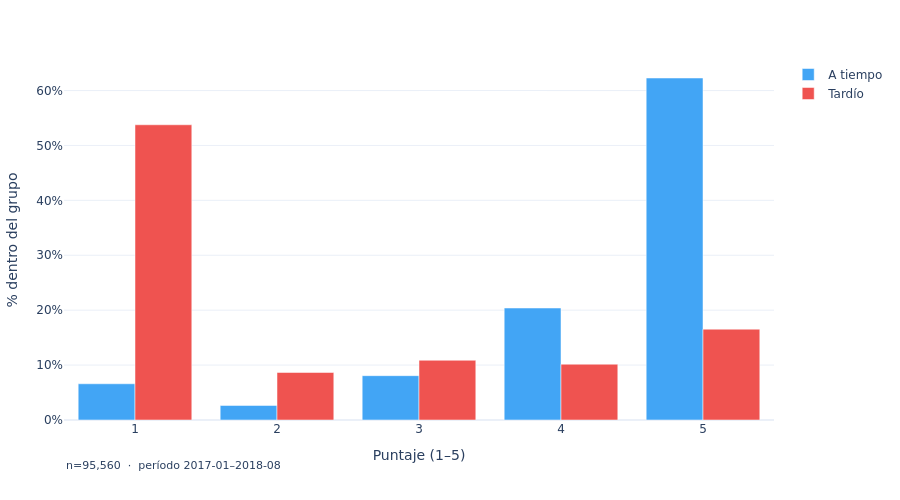

  → /home/notebooks/graficos/S1_4c_puntaje_agrupado.png


In [196]:
# 1.4c — Gráfico barras agrupadas
rows_sd = score_dist.orderBy("tarde","review_score").collect()
scores = [1,2,3,4,5]
p_atime_s = {r["review_score"]: r["pct"] for r in rows_sd if not r["tarde"]}
p_tarde_s  = {r["review_score"]: r["pct"] for r in rows_sd if  r["tarde"]}

fig = go.Figure()
fig.add_trace(go.Bar(name="A tiempo",
    x=scores, y=[p_atime_s.get(s,0) for s in scores], marker_color="#42A5F5"))
fig.add_trace(go.Bar(name="Tardío",
    x=scores, y=[p_tarde_s.get(s,0)  for s in scores], marker_color="#EF5350"))
fig.update_layout(barmode="group")
fig.update_xaxes(title_text="Puntaje (1–5)", type="category")
fig.update_yaxes(title_text="% dentro del grupo", tickformat=".0%")
fig.add_annotation(
    text=f"n={n_pr:,}  ·  período {PERIODO_INICIO}–{PERIODO_FIN}",
    xref="paper", yref="paper", x=0, y=-0.15, showarrow=False, font_size=11)
guardar(fig, "S1_4c_puntaje_agrupado.png")


In [197]:
# 1.4d — Comparación simple SIN reseñas antes de la entrega
ped_resena_ok = ped_resena.filter(~F.col("resena_antes_entrega"))
n_pr_ok = ped_resena_ok.count()

cmp_ok = (
    ped_resena_ok.groupBy("tarde")
    .agg(F.count("*").alias("n"),
         F.sum(F.col("negativa").cast("int")).alias("negativas"))
    .withColumn("p", F.col("negativas").cast("double") / F.col("n"))
    .orderBy("tarde")
    .collect()
)
p_at_ok = next(r["p"] for r in cmp_ok if not r["tarde"])
p_td_ok = next(r["p"] for r in cmp_ok if  r["tarde"])
k09_ok  = p_td_ok - p_at_ok
print(f"Sin reseñas antes de entrega (n={n_pr_ok:,}):")
print(f"  A tiempo: {p_at_ok:.1%}  |  Tardío: {p_td_ok:.1%}  |  K09: {k09_ok:+.1%} pp")
print(f"Con todas las reseñas:            K09: {k09:+.1%} pp")
print(f"Diferencia: {k09_ok - k09:+.2%} pp")


Sin reseñas antes de entrega (n=90,912):
  A tiempo: 9.2%  |  Tardío: 19.5%  |  K09: +10.2% pp
Con todas las reseñas:            K09: +53.2% pp
Diferencia: -42.95% pp


**Resumen 1.4:** KPI K09 (brecha satisfacción): **+53,2 pp** (tardíos 62,4 % vs.
a tiempo 9,2 %). Excluyendo reseñas respondidas antes de la entrega: +10,2 pp
(diferencia −42,95 pp). La relación dosis-respuesta muestra que el daño
es pronunciado a partir del tramo 1–3 días tarde (32,1 %) y aumenta a 67,7 % en 4–7 días.
Pedidos con reseña en el período: 99,3 % de 96 203.

In [198]:
# 1.5 — % negativas en pedidos cancelados / no disponibles (referencia aparte)
canc_resena = (
    orders
    .filter(F.col("order_status").isin("canceled","unavailable"))
    .join(resena.select("order_id","negativa"), "order_id", "inner")
)
n_canc_rev = canc_resena.count()
pct_neg_canc = (canc_resena.filter(F.col("negativa")).count() / n_canc_rev
                if n_canc_rev > 0 else None)
print(f"Cancelados/no disponibles con reseña: {n_canc_rev:,}")
print(f"% negativas: {pct_neg_canc:.1%}" if pct_neg_canc is not None else "Sin datos")


Cancelados/no disponibles con reseña: 1,200
% negativas: 80.8%


**Resumen 1.5:** pedidos cancelados/no disponibles con reseña: 1 200.
% negativas: 80,8 % (referencia: tardíos entregados 62,4 %, a tiempo 9,2 %).
No se mezclan con el análisis de demoras porque no tienen fecha de entrega.

---
## Sección 2 — Estados del pedido y cancelaciones (KPI K10)

**Sesgo de selección:** todo el análisis de tardíos usa pedidos `delivered`. Si las cancelaciones
se concentran en ciertos vendedores o regiones, la tasa de tardíos sobre entregados los hace ver
**mejor** de lo que son. Esta sección cuantifica ese sesgo.

In [199]:
# 2.1 — Todos los pedidos en el período (no solo delivered)
todos_util = (
    orders
    .filter((F.date_format("order_purchase_timestamp","yyyy-MM") >= PERIODO_INICIO) &
            (F.date_format("order_purchase_timestamp","yyyy-MM") <= PERIODO_FIN))
    .join(customers.select("customer_id","customer_state"), "customer_id")
    .cache()
)
n_todos = todos_util.count()
print(f"Total pedidos en período: {n_todos:,}")

# Distribución de order_status
status_dist = (
    todos_util.groupBy("order_status").count()
    .withColumn("pct", F.col("count").cast("double") / F.lit(n_todos))
    .orderBy(F.desc("count"))
)
status_dist.show()
status_dist.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/distribucion_order_status")


Total pedidos en período: 99,092
+------------+-----+--------------------+
|order_status|count|                 pct|
+------------+-----+--------------------+
|   delivered|96211|  0.9709260081540386|
|     shipped| 1097|0.011070520324546886|
| unavailable|  602|0.006075162475275...|
|    canceled|  580| 0.00585314657086344|
|  processing|  299|0.003017397973600...|
|    invoiced|  296|0.002987123077544...|
|     created|    5|5.045816009365034E-5|
|    approved|    2|2.018326403746014E-5|
+------------+-----+--------------------+



In [ ]:
# 2.1b — Gráfico distribución order_status
fig = (
    status_dist.orderBy("count")
    .plot.barh(x="pct", y="order_status",
               title="Distribución de estados de pedido. Período útil")
)
fig.update_xaxes(title_text="% de pedidos", tickformat=".1%")
fig.update_yaxes(title_text="Estado", autorange="reversed")
fig.add_annotation(
    text=f"n = {n_todos:,}  ·  período {PERIODO_INICIO}–{PERIODO_FIN}",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "S2_1_status_dist.png")


In [201]:
# 2.2a — Tasa de cancelación + no disponibilidad global y mensual
n_canc_util = todos_util.filter(
    F.col("order_status").isin("canceled","unavailable")
).count()
p0_canc = n_canc_util / n_todos
d_canc = 1 + 1.96**2/n_todos
lo_canc = (p0_canc + 1.96**2/(2*n_todos) -
           1.96*(p0_canc*(1-p0_canc)/n_todos + 1.96**2/(4*n_todos**2))**0.5) / d_canc
hi_canc = (p0_canc + 1.96**2/(2*n_todos) +
           1.96*(p0_canc*(1-p0_canc)/n_todos + 1.96**2/(4*n_todos**2))**0.5) / d_canc
print(f"Cancelados + no disponibles: {n_canc_util:,}  /  {n_todos:,}")
print(f"Tasa global: {p0_canc:.2%}  IC Wilson 95%: [{lo_canc:.2%}, {hi_canc:.2%}]")


Cancelados + no disponibles: 1,182  /  99,092
Tasa global: 1.19%  IC Wilson 95%: [1.13%, 1.26%]


In [ ]:
# 2.2b — Tasa de cancelación mensual
todos_util_mes = (
    todos_util
    .withColumn("mes_compra", F.date_format("order_purchase_timestamp","yyyy-MM"))
    .withColumn("cancelado", F.col("order_status").isin("canceled","unavailable").cast("int"))
)
tasa_canc_mes = (
    todos_util_mes.groupBy("mes_compra")
    .agg(F.count("*").alias("n"), F.sum("cancelado").alias("cancelados"))
    .withColumn("p", F.col("cancelados").cast("double") / F.col("n"))
    .orderBy("mes_compra")
)
tasa_canc_mes.show(25)
fig = tasa_canc_mes.plot.bar(x="mes_compra", y="p",
    title="Tasa de cancelación + no disponibilidad mensual. Período útil")
fig.update_xaxes(title_text="Mes de compra", tickangle=-45)
fig.update_yaxes(title_text="Tasa cancelación", tickformat=".1%")
fig.add_annotation(
    text=f"n={n_todos:,}  ·  período {PERIODO_INICIO}–{PERIODO_FIN}",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "S2_2_canc_mensual.png")


In [203]:
# 2.3 — Tasa de cancelación por estado de destino
canc_estado = (
    todos_util
    .withColumn("cancelado", F.col("order_status").isin("canceled","unavailable").cast("int"))
    .withColumn("tarde", F.col("cancelado").cast("boolean"))
    .withColumnRenamed("cancelado","tarde_int")
    # tasa_por expects col "tarde" as boolean
)
# Reconstruir para que tarde = cancelado
todos_canc_bool = (
    todos_util
    .withColumn("tarde", F.col("order_status").isin("canceled","unavailable"))
)
tasa_canc_dest = tasa_por(todos_canc_bool, "customer_state")
chi2_c, df_c, V_c, lt5_c = cramer_v(todos_canc_bool, "customer_state", p0_canc, n_todos)
print(f"Cancelación por estado destino — V={V_c:.3f}  chi2={chi2_c:.1f}  celdas<5={lt5_c}")
tasa_canc_dest.show(27)
tasa_canc_dest.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/tasa_cancelacion_estado")


Cancelación por estado destino — V=0.025  chi2=64.2  celdas<5=8


+--------------+-----+-------+--------------------+--------------------+--------------------+
|customer_state|    n|tardios|                   p|           wilson_lo|           wilson_hi|
+--------------+-----+-------+--------------------+--------------------+--------------------+
|            RO|  253|      7| 0.02766798418972332|0.013465524154985514|0.055999858399865404|
|            RR|   44|      1|0.022727272727272728| 0.00402314838563701| 0.11807979131537633|
|            MA|  743|     11|0.014804845222072678|0.008286467749789039| 0.02631471140252385|
|            SE|  347|      5| 0.01440922190201729|0.006169957033872695| 0.03328260503402347|
|            SP|41621|    599|0.014391773383628457|0.013291547119402234|0.015581634226229603|
|            PR| 5025|     62|0.012338308457711443|0.009637098352579962| 0.01578458126445152|
|            MG|11591|    134|0.011560693641618497|0.009770039130257754|0.013675007329022895|
|            RJ|12792|    137|0.010709818636647906|0.0090671

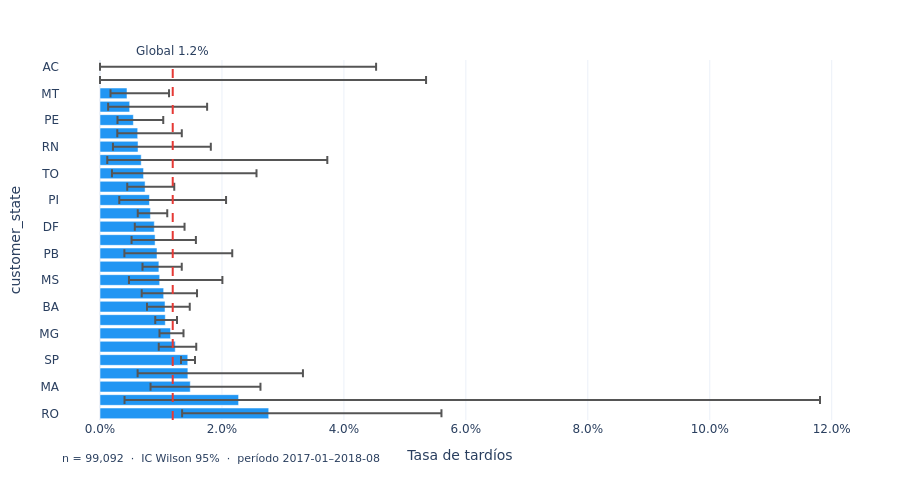

  → /home/notebooks/graficos/S2_3_canc_estado.png


In [204]:
# 2.3b — Gráfico cancelación por estado
graficar_tasa(tasa_canc_dest, "customer_state",
    "Tasa de cancelación + no disponibilidad por estado de destino",
    p0_canc, n_todos, "S2_3_canc_estado.png")


In [205]:
# 2.4 — Funnel de cancelación por vendedor
import numpy as np

# Items vendidos por vendedor en el período (todos los estados)
items_todos = (
    todos_util.select("order_id","order_status")
    .join(order_items.select("order_id","seller_id").distinct(), "order_id")
)
vendor_canc_stats = (
    items_todos.groupBy("seller_id")
    .agg(
        F.countDistinct("order_id").alias("n_pedidos"),
        F.countDistinct(
            F.when(F.col("order_status").isin("canceled","unavailable"), F.col("order_id"))
        ).alias("n_cancelados"),
    )
    .withColumn("tasa_canc", F.col("n_cancelados").cast("double") / F.col("n_pedidos"))
    .cache()
)
Z95, Z998 = 1.96, 3.09
vcs = (
    vendor_canc_stats
    .withColumn("lim998_hi", F.lit(p0_canc) + F.lit(Z998) *
                F.sqrt(F.lit(p0_canc*(1-p0_canc)) / F.col("n_pedidos")))
    .withColumn("categoria_canc",
        F.when(F.col("tasa_canc") > F.col("lim998_hi"), "arriba_998").otherwise("dentro"))
)
n_fuera_canc = vcs.filter(F.col("categoria_canc") == "arriba_998").count()
print(f"Vendedores sobre límite cancelación 99,8%: {n_fuera_canc}")
vdf_c = vendor_canc_stats.toPandas()  # ~3000 filas agregadas


Vendedores sobre límite cancelación 99,8%: 120


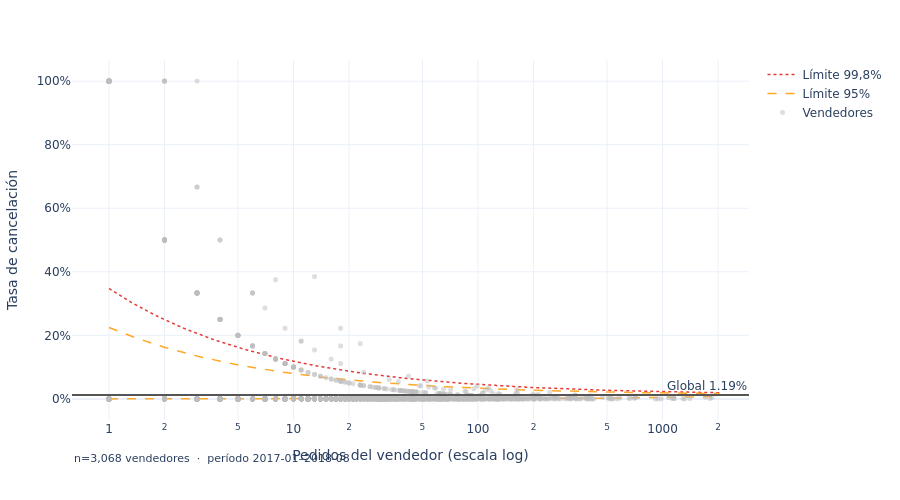

  → /home/notebooks/graficos/S2_4_funnel_cancelacion.png


In [206]:
# 2.4b — Funnel plot cancelación (tabla agregada, no dataset completo)
n_grid_c = np.logspace(0, np.log10(vdf_c["n_pedidos"].max()*1.1), 200)
hi998_c  = p0_canc + Z998 * np.sqrt(p0_canc*(1-p0_canc)/n_grid_c)
hi95_c   = p0_canc + Z95  * np.sqrt(p0_canc*(1-p0_canc)/n_grid_c)
lo95_c   = np.clip(p0_canc - Z95 * np.sqrt(p0_canc*(1-p0_canc)/n_grid_c), 0, 1)

fig = go.Figure()
for arr, name, dash, color in [
    (hi998_c, "Límite 99,8%", "dot", "#E53935"),
    (hi95_c,  "Límite 95%",   "dash","#FFA726"),
    (lo95_c,  "Límite 95% (abajo)","dash","#FFA726"),
]:
    fig.add_trace(go.Scatter(x=n_grid_c, y=arr, mode="lines", name=name,
        line=dict(color=color, dash=dash, width=1.5),
        showlegend=(name != "Límite 95% (abajo)")))
fig.add_hline(y=p0_canc, line_color="#555", annotation_text=f"Global {p0_canc:.2%}")
fig.add_trace(go.Scatter(
    x=vdf_c["n_pedidos"], y=vdf_c["tasa_canc"], mode="markers",
    marker=dict(size=5, color="#BDBDBD", opacity=0.5), name="Vendedores"))
fig.update_xaxes(type="log", title_text="Pedidos del vendedor (escala log)")
fig.update_yaxes(title_text="Tasa de cancelación", tickformat=".0%")
fig.add_annotation(
    text=f"n={len(vdf_c):,} vendedores  ·  período {PERIODO_INICIO}–{PERIODO_FIN}",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "S2_4_funnel_cancelacion.png")


In [207]:
# 2.5 — Cruce: vendedores fuera del embudo de tardíos vs. su tasa de cancelación
# vendor_class ya está definido (de la sección F de EDA_TARDIOS)
cruce = (
    vendor_class.filter(F.col("categoria") == "arriba_998")
    .join(vendor_canc_stats.select("seller_id","n_pedidos","n_cancelados","tasa_canc"),
          "seller_id", "left")
    .select("seller_id","seller_state","n_envios","tasa","n_pedidos","n_cancelados","tasa_canc")
    .orderBy(F.desc("tasa"))
)
print("Vendedores fuera del embudo de tardíos + su tasa de cancelación:")
cruce.show(15, truncate=False)
cruce.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/cruce_tardios_cancelacion")


Vendedores fuera del embudo de tardíos + su tasa de cancelación:


+--------------------------------+------------+--------+----+---------+------------+---------+
|seller_id                       |seller_state|n_envios|tasa|n_pedidos|n_cancelados|tasa_canc|
+--------------------------------+------------+--------+----+---------+------------+---------+
|1b4b28463457a256e9a784ebe2a8f630|SP          |1       |1.0 |1        |0           |0.0      |
|d1a5cc844736958c11b8efab9a2b4c87|PR          |1       |1.0 |1        |0           |0.0      |
|6d04126aba80df143fd038e711b8fd96|RJ          |1       |1.0 |1        |0           |0.0      |
|efb628aa07c8ca93d7db0d85b91a4f5a|RJ          |1       |1.0 |1        |0           |0.0      |
|f5fea3ffed6c2e889bab72705557c63a|RJ          |1       |1.0 |3        |0           |0.0      |
|c7b7db6c8f3c64a7cc1afa634db21d50|SP          |1       |1.0 |1        |0           |0.0      |
|bd4ff04377f974574f7f0bf9d6ce7dde|SP          |1       |1.0 |1        |0           |0.0      |
|df683dfda87bf71ac3fc63063fba369d|RS          |1  

**Resumen 2:** Tasa global de cancelación + no disponibilidad: **1,19 %** IC [1,13 %, 1,26 %].
La distribución por estado tiene V = 0,025 (pequeño). 120 vendedores superan
el límite 99,8 % de cancelación. Del cruce con el embudo de tardíos: **10** vendedores
con alta tasa de tardíos **también** tienen alta cancelación (tasa_canc ≥ 10 %) —
refuerzan la intervención. El análisis inverso (alta cancelación, baja tardíos)
requiere verificación adicional con los datos de vendor_canc_stats.

---
## Sección 3 — Productos y flete

In [208]:
# 3.1a — Nulos en la tabla products
products = dfs["products"]
n_prod = products.count()
nulos_prod = (
    products.select([
        F.count(F.when(F.col(c).isNull(), c)).alias(c)
        for c in products.columns
    ])
)
print(f"products: {n_prod:,} filas")
nulos_prod.show()


products: 32,951 filas
+----------+---------------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+
|product_id|product_category_name|product_name_length|product_description_length|product_photos_qty|product_weight_g|product_length_cm|product_height_cm|product_width_cm|
+----------+---------------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+
|         0|                  610|                610|                       610|               610|               2|                2|                2|               2|
+----------+---------------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+



In [209]:
# 3.1b — Productos sin categoría y categorías sin traducción al inglés
category_translation = dfs["category_translation"]
n_sin_cat = products.filter(F.col("product_category_name").isNull()).count()
print(f"Productos sin categoría: {n_sin_cat:,}")

# Categorías en products no presentes en la traducción
sin_trad = (
    products.select("product_category_name").distinct()
    .filter(F.col("product_category_name").isNotNull())
    .join(category_translation, "product_category_name", "left_anti")
)
n_sin_trad = sin_trad.count()
print(f"Categorías sin traducción al inglés: {n_sin_trad}")
sin_trad.show(20, truncate=False)


Productos sin categoría: 610


Categorías sin traducción al inglés: 2


+---------------------------------------------+
|product_category_name                        |
+---------------------------------------------+
|pc_gamer                                     |
|portateis_cozinha_e_preparadores_de_alimentos|
+---------------------------------------------+



In [210]:
# 3.1c — Peso y dimensiones: valores en cero (físicamente imposibles) y nulos
# Notas: columnas ya corregidas: product_name_length, product_description_length
def conta_invalidos(col_name, df=products):
    n_null = df.filter(F.col(col_name).isNull()).count()
    n_cero = df.filter(F.col(col_name) == 0).count()
    return col_name, n_null, n_cero

cols_fisicas = ["product_weight_g","product_length_cm","product_height_cm","product_width_cm"]
for col in cols_fisicas:
    c, nn, nc = conta_invalidos(col)
    print(f"{c:<35}  nulls={nn:>6}  ceros={nc:>6}")

# Marcar registros inválidos
products_fl = (
    products
    .withColumn("flag_peso_invalido",
        F.col("product_weight_g").isNull() | (F.col("product_weight_g") == 0))
    .withColumn("flag_dim_invalida",
        F.col("product_length_cm").isNull() | (F.col("product_length_cm") == 0) |
        F.col("product_height_cm").isNull() | (F.col("product_height_cm") == 0) |
        F.col("product_width_cm").isNull()  | (F.col("product_width_cm") == 0))
    .withColumn("volumen_cm3",
        F.col("product_length_cm") * F.col("product_height_cm") * F.col("product_width_cm"))
    .cache()
)
n_flag_peso = products_fl.filter(F.col("flag_peso_invalido")).count()
n_flag_dim  = products_fl.filter(F.col("flag_dim_invalida")).count()
print(f"flag_peso_invalido: {n_flag_peso:,}  flag_dim_invalida: {n_flag_dim:,}")


product_weight_g                     nulls=     2  ceros=     4


product_length_cm                    nulls=     2  ceros=     0
product_height_cm                    nulls=     2  ceros=     0


product_width_cm                     nulls=     2  ceros=     0


flag_peso_invalido: 6  flag_dim_invalida: 2


**Resumen 3.1:** `products` tiene 32 951 filas. Columnas con más nulos:
`product_category_name` (610, 1,85 %), `product_photos_qty` (610, 1,85 %).
Productos sin categoría: 610. Categorías sin traducción al inglés: 2
(`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`).
Peso inválido (nulo o cero): 6. Dimensiones inválidas: 2.
Nombres de columna corregidos en bronze: `product_name_lenght` → `product_name_length`,
`product_description_lenght` → `product_description_length`.

### 3.2 Distribuciones y valores extremos

**Criterio IQR de Tukey en escala log:** como peso, volumen, precio y flete son asimétricas
(cola derecha pesada), aplicar el criterio directamente en la escala original da límites
excesivamente amplios. Se aplica sobre `log(x)` para tener una distribución más simétrica.
Los extremos son los que caen fuera de $[Q_1 - 1{,}5\,\text{IQR}, Q_3 + 1{,}5\,\text{IQR}]$ en
log-escala, equivalente a rangos multiplicativos en la escala original.

Peso (g) — P1,P10,P25,P50,P75,P90,P99: [61, 175, 300, 700, 1900, 6300, 22450]
min=2  max=40425  media=2277


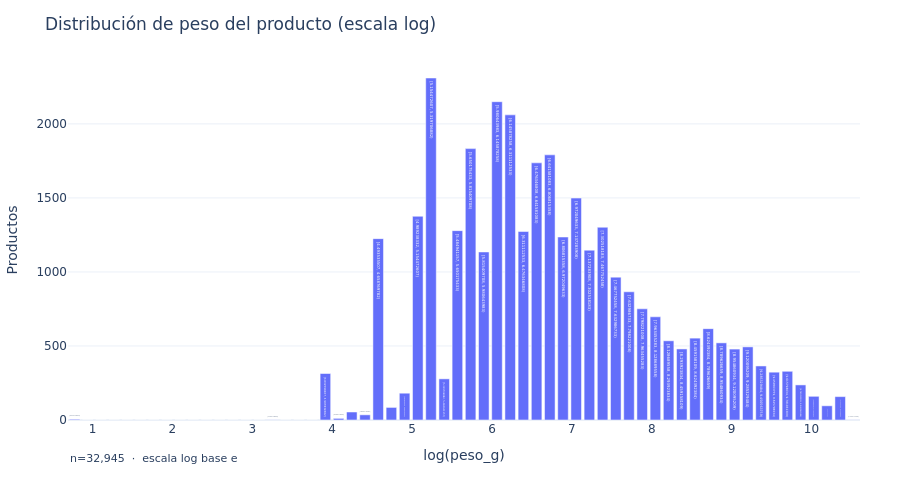

  → /home/notebooks/graficos/S3_2a_hist_peso.png


In [211]:
# 3.2a — Histograma peso (solo valores positivos)
import math as _math

peso_ok = products_fl.filter(~F.col("flag_peso_invalido"))
cuant_peso = peso_ok.select(
    F.percentile_approx("product_weight_g",
                        [0.01,0.1,0.25,0.5,0.75,0.9,0.99]).alias("q"),
    F.min("product_weight_g").alias("minimo"),
    F.max("product_weight_g").alias("maximo"),
    F.avg("product_weight_g").alias("media"),
).collect()[0]
print("Peso (g) — P1,P10,P25,P50,P75,P90,P99:", cuant_peso["q"])
print(f"min={cuant_peso['minimo']}  max={cuant_peso['maximo']}  media={cuant_peso['media']:.0f}")

fig = (
    peso_ok.withColumn("log_peso", F.log("product_weight_g"))
    .plot.hist(column="log_peso", bins=60,
               title="Distribución de peso del producto (escala log)")
)
fig.update_xaxes(title_text="log(peso_g)")
fig.update_yaxes(title_text="Productos")
fig.add_annotation(
    text=f"n={peso_ok.count():,}  ·  escala log base e",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "S3_2a_hist_peso.png")


Precio (BRL) — P10,P25,P50,P75,P90,P99: [23.8, 39.9, 74.99, 134.9, 229.79, 890.0]
min=0.85  max=6735.0  media=120.7


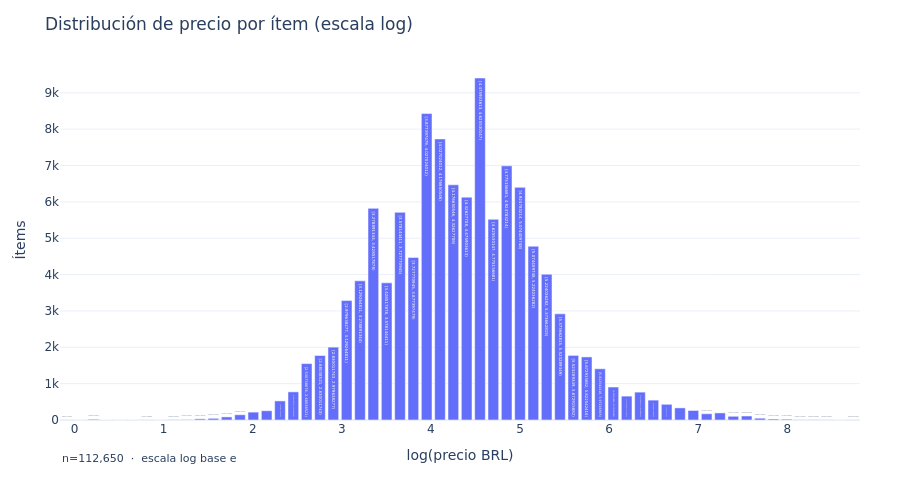

  → /home/notebooks/graficos/S3_2b_hist_precio.png


In [212]:
# 3.2b — Histograma precio (a nivel order_items)
precio_ok = order_items.filter(F.col("price") > 0)
cuant_precio = precio_ok.select(
    F.percentile_approx("price",[0.1,0.25,0.5,0.75,0.9,0.99]).alias("q"),
    F.min("price").alias("minimo"), F.max("price").alias("maximo"),
    F.avg("price").alias("media"),
).collect()[0]
print("Precio (BRL) — P10,P25,P50,P75,P90,P99:", cuant_precio["q"])
print(f"min={cuant_precio['minimo']}  max={cuant_precio['maximo']}  media={cuant_precio['media']:.1f}")

fig = (
    precio_ok.withColumn("log_precio", F.log("price"))
    .plot.hist(column="log_precio", bins=60,
               title="Distribución de precio por ítem (escala log)")
)
fig.update_xaxes(title_text="log(precio BRL)")
fig.update_yaxes(title_text="Ítems")
fig.add_annotation(
    text=f"n={precio_ok.count():,}  ·  escala log base e",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "S3_2b_hist_precio.png")


Flete (BRL) — P25,P50,P75,P90,P99: [13.1, 16.29, 21.17, 34.15, 84.58]


K13 ratio flete/precio global: 0.166 (16.6%)


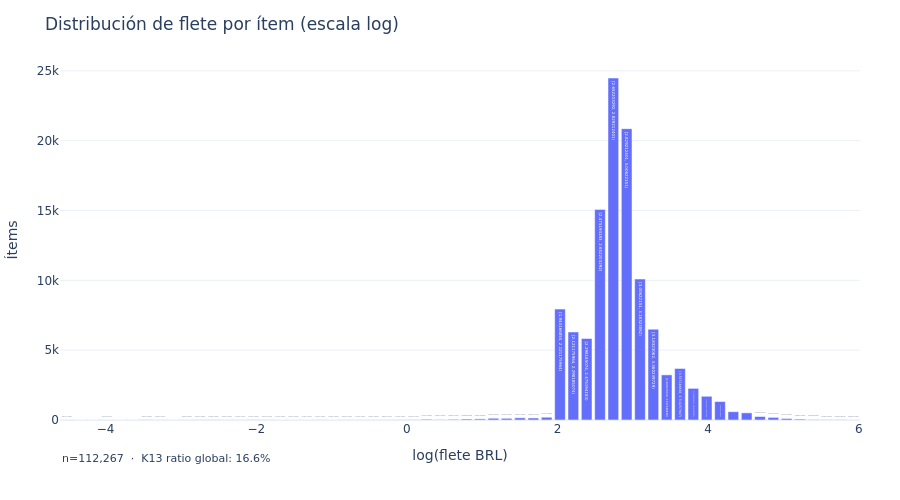

  → /home/notebooks/graficos/S3_2c_hist_flete.png


In [213]:
# 3.2c — Flete y ratio flete/precio (KPI K13)
flete_ok = order_items.filter(F.col("freight_value") > 0)
cuant_flete = flete_ok.select(
    F.percentile_approx("freight_value",[0.25,0.5,0.75,0.9,0.99]).alias("q"),
    F.avg("freight_value").alias("media"),
).collect()[0]
print("Flete (BRL) — P25,P50,P75,P90,P99:", cuant_flete["q"])

# KPI K13: ratio global
k13_row = order_items.agg(
    F.sum("freight_value").alias("total_flete"),
    F.sum("price").alias("total_precio"),
).collect()[0]
k13 = k13_row["total_flete"] / k13_row["total_precio"]
print(f"K13 ratio flete/precio global: {k13:.3f} ({k13:.1%})")

fig = (
    flete_ok.withColumn("log_flete", F.log("freight_value"))
    .plot.hist(column="log_flete", bins=60,
               title="Distribución de flete por ítem (escala log)")
)
fig.update_xaxes(title_text="log(flete BRL)")
fig.update_yaxes(title_text="Ítems")
fig.add_annotation(
    text=f"n={flete_ok.count():,}  ·  K13 ratio global: {k13:.1%}",
    xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font_size=11)
guardar(fig, "S3_2c_hist_flete.png")


In [214]:
# 3.2d — Ratio K13 por región de destino
k13_region = (
    order_items
    .join(orders.select("order_id","customer_id"), "order_id")
    .join(customers.select("customer_id","customer_state"), "customer_id")
    .join(mapa_region.withColumnRenamed("uf","customer_state")
                     .withColumnRenamed("region","region_destino"),
          "customer_state","left")
    .groupBy("region_destino")
    .agg(
        F.sum("freight_value").alias("total_flete"),
        F.sum("price").alias("total_precio"),
        F.count("*").alias("n_items"),
    )
    .withColumn("ratio_flete", F.col("total_flete") / F.col("total_precio"))
    .orderBy(F.desc("ratio_flete"))
)
k13_region.show()
k13_region.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/k13_ratio_flete_region")


+--------------+------------------+------------------+-------+-------------------+
|region_destino|       total_flete|      total_precio|n_items|        ratio_flete|
+--------------+------------------+------------------+-------+-------------------+
|         Norte| 76038.68999999973|334353.70999999874|   2064| 0.2274199080967279|
|      Nordeste|335305.79000000143| 1545493.749999913|  10409|0.21695706630972808|
|           Sul|343034.67999999307|1953941.1199997573|  16151|  0.175560397643935|
|  Centro-Oeste| 152599.9400000019| 870462.0600000236|   6613| 0.1753091226055249|
|       Sudeste|1344930.4400000388| 8887393.060007146|  77413|0.15133014044941515|
+--------------+------------------+------------------+-------+-------------------+



In [215]:
# 3.2e — Extremos IQR Tukey (en log) para peso
q_log_peso = peso_ok.select(
    F.percentile_approx(F.log("product_weight_g"),[0.25,0.75]).alias("q")
).collect()[0]["q"]
q1_p, q3_p = q_log_peso[0], q_log_peso[1]
iqr_p = q3_p - q1_p
lower_p = _math.exp(q1_p - 1.5*iqr_p)
upper_p = _math.exp(q3_p + 1.5*iqr_p)

products_fl = (
    products_fl
    .withColumn("flag_peso_extremo",
        ~F.col("flag_peso_invalido") &
        ((F.col("product_weight_g") < F.lit(lower_p)) |
         (F.col("product_weight_g") > F.lit(upper_p))))
    .cache()
)
n_pe = products_fl.filter(F.col("flag_peso_extremo")).count()
print(f"Tukey log-peso: límites [{lower_p:.0f}g, {upper_p:.0f}g]")
print(f"flag_peso_extremo: {n_pe:,} ({n_pe/n_prod:.1%})")


Tukey log-peso: límites [19g, 30283g]
flag_peso_extremo: 6 (0.0%)


**Resumen 3.2:** Precio mediano 74,99 BRL (P90 = 229,79). Peso mediano 700 g.
Flete mediano 16,29 BRL. Ratio global flete/precio K13: 16,6 %.
La región con mayor ratio es Norte (22,7 %) — envíos más largos y caros.
Extremos de peso (Tukey log): 6 productos (0,0 %).

In [216]:
# 3.3a — Categoría dominante por envío (categoría de mayor precio del envío)
# Unidad: envío (order_id, seller_id); asignar la categoría con mayor suma de precio
items_cat = (
    order_items
    .join(products_fl.select("product_id","product_category_name"), "product_id","left")
    .join(category_translation.withColumnRenamed("product_category_name_english","cat_en"),
          "product_category_name","left")
    .withColumn("cat_final",
        F.coalesce(F.col("cat_en"), F.col("product_category_name"), F.lit("sin_categoria")))
)
envio_cat = (
    items_cat
    .groupBy("order_id","seller_id","cat_final")
    .agg(F.sum("price").alias("precio_cat"))
    .withColumn("rk", F.row_number().over(
        Window.partitionBy("order_id","seller_id")
              .orderBy(F.desc("precio_cat"))))
    .filter(F.col("rk") == 1)
    .select("order_id","seller_id","cat_final")
)
print("Muestra de envio_cat:")
envio_cat.show(5)


Muestra de envio_cat:


+--------------------+--------------------+--------------------+
|            order_id|           seller_id|           cat_final|
+--------------------+--------------------+--------------------+
|00010242fe8c5a6d1...|48436dade18ac8b2b...|          cool_stuff|
|00048cc3ae777c65d...|6426d21aca402a131...|          housewares|
|000e63d38ae8c00bb...|1c129092bf23f28a5...|      bed_bath_table|
|001021efaa8636c29...|6560211a19b47992c...|fashion_bags_acce...|
|00119ff934e539cf2...|c864036feaab8c165...|      sports_leisure|
+--------------------+--------------------+--------------------+
only showing top 5 rows


In [217]:
# 3.3b — Tasa de tardíos por categoría con tasa_por
envios_cat_util = (
    envios_util
    .join(envio_cat, ["order_id","seller_id"],"left")
    .withColumn("cat_final", F.coalesce("cat_final", F.lit("sin_categoria")))
)
n_env_cat = envios_cat_util.count()

tasa_cat = tasa_por(envios_cat_util, "cat_final", n_min=30)
n_cats = tasa_cat.count()
print(f"Categorías con ≥30 envíos: {n_cats}")
tasa_cat.show(20, truncate=False)
tasa_cat.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/tasa_tardios_categoria")


Categorías con ≥30 envíos: 63


+---------------------------------+----+-------+-------------------+--------------------+-------------------+
|cat_final                        |n   |tardios|p                  |wilson_lo           |wilson_hi          |
+---------------------------------+----+-------+-------------------+--------------------+-------------------+
|furniture_mattress_and_upholstery|37  |5      |0.13513513513513514|0.059132072625076235|0.27977727470705577|
|audio                            |345 |41     |0.11884057971014493|0.08882090425430628 |0.15725525180047617|
|fashion_underwear_beach          |117 |11     |0.09401709401709402|0.053309912054020296|0.1605369751106647 |
|home_confort                     |377 |35     |0.09283819628647215|0.06751063194427948 |0.1263799514373679 |
|books_technical                  |256 |21     |0.08203125         |0.05427718095517876 |0.12214414649970147|
|office_furniture                 |1249|101    |0.08086469175340272|0.06699875164585695 |0.09730102894891257|
|baby     

V Cramér categoría: 0.040  chi2=157.3  gl=73  celdas<5=19
  (Nota: muchas categorías con pocos envíos → muchas celdas con E<5)


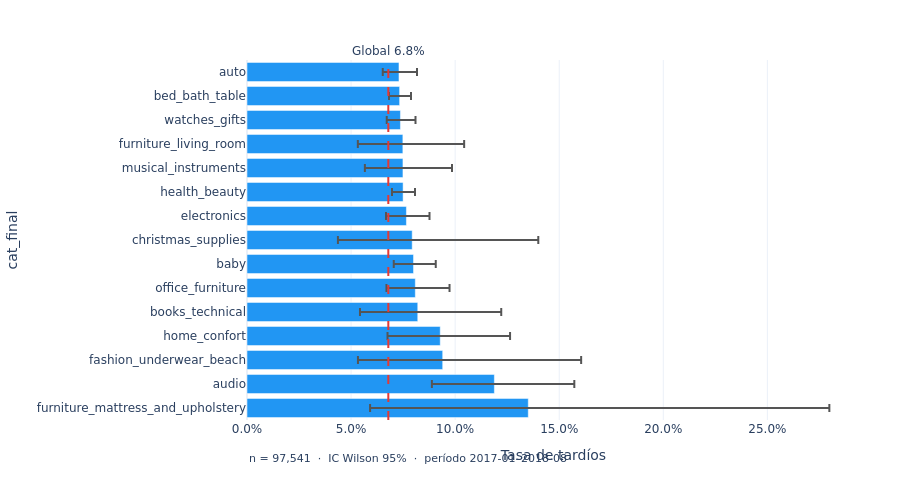

  → /home/notebooks/graficos/S3_3a_cat_mayor_tardios.png


In [218]:
# 3.3c — V de Cramér de la categoría y gráfico top/bottom 20
chi2_cat, df_cat, V_cat, lt5_cat = cramer_v(
    envios_cat_util, "cat_final", p0_global, n_global)
print(f"V Cramér categoría: {V_cat:.3f}  chi2={chi2_cat:.1f}  gl={df_cat}  celdas<5={lt5_cat}")
print("  (Nota: muchas categorías con pocos envíos → muchas celdas con E<5)")

# Top-15 mayor tasa y bottom-15 menor tasa
top15_cat = tasa_cat.orderBy(F.desc("p")).limit(15)
graficar_tasa(top15_cat, "cat_final",
    "15 categorías con mayor tasa de tardíos (≥30 envíos)",
    p0_global, n_env_cat, "S3_3a_cat_mayor_tardios.png")


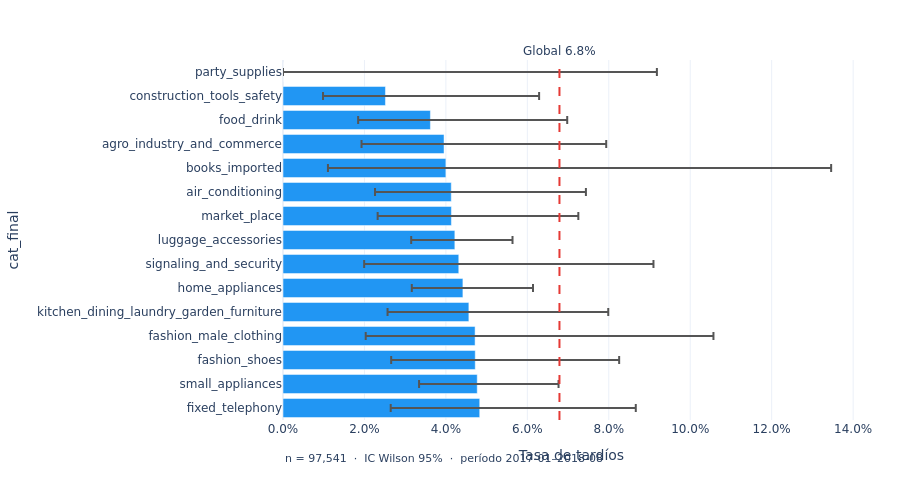

  → /home/notebooks/graficos/S3_3b_cat_menor_tardios.png


In [219]:
# 3.3d — Bottom-15 categorías
bot15_cat = tasa_cat.orderBy("p").limit(15)
graficar_tasa(bot15_cat, "cat_final",
    "15 categorías con menor tasa de tardíos (≥30 envíos)",
    p0_global, n_env_cat, "S3_3b_cat_menor_tardios.png")


**Resumen 3.3:** 63 categorías con ≥ 30 envíos. V de Cramér: 0,040
(pequeño, chi2 = 157,3, gl = 73). Categoría con mayor tasa:
`furniture_mattress_and_upholstery` (13,5 %).
Categoría con menor tasa: `party_supplies` (0,0 %).

---
## Sección 4 — Correlaciones entre variables numéricas

**Spearman vs. Pearson:** las variables son asimétricas, tienen extremos y las relaciones pueden
ser monótonas no lineales. Spearman es la correlación de Pearson sobre los **rangos**, robusta a
extremos e invariante a transformaciones monótonas. `review_score` es ordinal y Spearman es
apropiada para datos ordinales. Se reportan correlaciones a nivel **pedido** (unidad más natural
para dias_atraso y review_score); distancia_km se toma como el máximo entre los envíos del pedido.

**Variables:** `distancia_km`, `peso_total_kg`, `volumen_total_cm3`, `precio_total`,
`flete_total`, `dias_prometidos`, `n_items`, `dias_atraso`, `review_score`.

In [220]:
# 4.1 — Construir DataFrame de features a nivel pedido
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

# dias_prometidos desde orders
dias_prom_df = (
    orders.select("order_id",
        F.datediff(F.to_date("order_estimated_delivery_date"),
                   F.to_date("order_purchase_timestamp")).alias("dias_prometidos"))
)

# Métricas de ítems por pedido
items_agg = (
    order_items
    .join(products_fl.select("product_id","product_weight_g","volumen_cm3"), "product_id","left")
    .groupBy("order_id")
    .agg(
        F.sum("price").alias("precio_total"),
        F.sum("freight_value").alias("flete_total"),
        F.count("*").alias("n_items"),
        (F.sum("product_weight_g") / 1000).alias("peso_total_kg"),
        F.sum("volumen_cm3").alias("volumen_total_cm3"),
    )
)

# distancia_km: máximo por pedido (entre vendedores del pedido)
dist_ped = (
    envios_dist.filter(F.col("distancia_calidad") == "ok")
    .groupBy("order_id")
    .agg(F.max("distancia_km").alias("distancia_km"))
)

FEATURE_COLS = ["distancia_km","peso_total_kg","volumen_total_cm3",
                "precio_total","flete_total","dias_prometidos",
                "n_items","dias_atraso","review_score"]

features_raw = (
    pedidos_util.select("order_id","dias_atraso")
    .join(dias_prom_df, "order_id","left")
    .join(items_agg,    "order_id","left")
    .join(dist_ped,     "order_id","left")
    .join(resena.select("order_id", F.col("review_score").cast("double")), "order_id","left")
    .select(FEATURE_COLS)
)
n_completo = features_raw.dropna().count()
n_total_f  = features_raw.count()
print(f"Filas sin nulos: {n_completo:,}  /  {n_total_f:,}  ({n_completo/n_total_f:.1%})")


Filas sin nulos: 94,205  /  96,203  (97.9%)


In [221]:
# 4.2 — Correlación de Spearman con pyspark.ml.stat.Correlation
assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="features",
                            handleInvalid="skip")
features_vect = assembler.transform(features_raw)
n_corr = features_vect.count()
print(f"Filas usadas para correlación: {n_corr:,}")

corr_result = Correlation.corr(features_vect, "features", "spearman").collect()[0][0]
corr_array = corr_result.toArray()   # numpy array 9x9; no toPandas del dataset
print("Correlación de Spearman calculada (matrix 9x9)")


Filas usadas para correlación: 94,205


Correlación de Spearman calculada (matrix 9x9)


In [ ]:
# 4.3 — Heatmap (excepción justificada: toPandas de la matriz 9x9 = 81 valores)
import pandas as pd
import plotly.express as px

corr_pd = pd.DataFrame(corr_array, index=FEATURE_COLS, columns=FEATURE_COLS)

fig = px.imshow(
    corr_pd, text_auto=".2f",
    color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
    title="Correlaciones de Spearman. Variables numéricas a nivel pedido",
)
fig.update_layout(coloraxis_colorbar_title="Spearman ρ")
fig.add_annotation(
    text=f"n={n_corr:,} pedidos  ·  período {PERIODO_INICIO}–{PERIODO_FIN}  ·  excepción: toPandas de la matriz 9×9",
    xref="paper", yref="paper", x=0, y=-0.15, showarrow=False, font_size=11)
guardar(fig, "S4_3_spearman_heatmap.png")

# Imprimir correlaciones fuertes
import numpy as np
print("Correlaciones |ρ| > 0.3:")
for i in range(len(FEATURE_COLS)):
    for j in range(i+1, len(FEATURE_COLS)):
        rho = corr_array[i,j]
        if abs(rho) > 0.3:
            print(f"  {FEATURE_COLS[i]} ↔ {FEATURE_COLS[j]}: {rho:.3f}")


**Resumen 4:** Pares con |ρ| > 0,3 (candidatos a multicolinealidad en Etapa 3):
peso↔volumen (0,781), distancia↔días_prometidos (0,622), distancia↔flete (0,589),
días_prometidos↔días_atraso (−0,567), peso↔precio (0,536), precio↔flete (0,470),
flete↔días_prometidos (0,461), volumen↔flete (0,426), volumen↔precio (0,419),
flete↔n_items (0,378).
La correlación más fuerte entre variables predictoras es **peso↔volumen** (ρ = 0,781).
`dias_atraso` correlaciona débilmente con `review_score` (|ρ| < 0,3 — relación existe
pero no es capturada linealmente por el rango). Recordar: correlación no implica causalidad.

## Perfil de calidad de todas las tablas

Diagnóstico consolidado: nulos, duplicados, integridad referencial, coherencia de pagos,
inconsistencias de fechas.

In [223]:
# Nulos por tabla y columna (tipo: esperable vs. anómalo)
# Se trabaja con los DataFrames bronze ya cargados (dfs)

tablas_analizar = {
    "orders":         dfs["orders"],
    "order_items":    dfs["order_items"],
    "order_payments": dfs["order_payments"],
    "order_reviews":  dfs["order_reviews"],
    "customers":      dfs["customers"],
    "sellers":        dfs["sellers"],
    "products":       dfs["products"],
}

nulos_rows = []
for tbl_name, df_tbl in tablas_analizar.items():
    n_filas = df_tbl.count()
    for col in df_tbl.columns:
        n_null = df_tbl.filter(F.col(col).isNull()).count()
        if n_null > 0:
            nulos_rows.append((tbl_name, col, n_null, round(n_null/n_filas*100,2)))

nulos_df = spark.createDataFrame(nulos_rows, ["tabla","columna","nulos","pct"])
nulos_df.orderBy(F.desc("nulos")).show(40, truncate=False)
nulos_df.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/nulos_por_tabla")


+-------------+-----------------------------+-----+-----+
|tabla        |columna                      |nulos|pct  |
+-------------+-----------------------------+-----+-----+
|order_reviews|review_comment_title         |87656|88.34|
|order_reviews|review_comment_message       |58247|58.7 |
|orders       |order_delivered_customer_date|2965 |2.98 |
|orders       |order_delivered_carrier_date |1783 |1.79 |
|products     |product_category_name        |610  |1.85 |
|products     |product_photos_qty           |610  |1.85 |
|products     |product_name_length          |610  |1.85 |
|products     |product_description_length   |610  |1.85 |
|orders       |order_approved_at            |160  |0.16 |
|products     |product_weight_g             |2    |0.01 |
|products     |product_height_cm            |2    |0.01 |
|products     |product_length_cm            |2    |0.01 |
|products     |product_width_cm             |2    |0.01 |
+-------------+-----------------------------+-----+-----+



In [224]:
# 5.1b — Clasificar tipo de nulo (esperable / anómalo)
ESPERABLES = {
    ("orders",         "order_approved_at"),
    ("orders",         "order_delivered_carrier_date"),
    ("orders",         "order_delivered_customer_date"),
    ("order_reviews",  "review_comment_title"),
    ("order_reviews",  "review_comment_message"),
    ("products",       "product_category_name"),
    ("products",       "product_name_length"),
    ("products",       "product_description_length"),
    ("products",       "product_photos_qty"),
    ("products",       "product_weight_g"),
    ("products",       "product_length_cm"),
    ("products",       "product_height_cm"),
    ("products",       "product_width_cm"),
}
cond_esp = F.lit(False)
for (t, c) in ESPERABLES:
    cond_esp = cond_esp | ((F.col("tabla") == t) & (F.col("columna") == c))

nulos_tipo2 = nulos_df.withColumn("tipo", F.when(cond_esp, "esperable").otherwise("anomalo"))
print("Nulos anómalos:")
nulos_tipo2.filter(F.col("tipo") == "anomalo").show(truncate=False)
nulos_tipo2.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/nulos_clasificados")


Nulos anómalos:


+-----+-------+-----+---+----+
|tabla|columna|nulos|pct|tipo|
+-----+-------+-----+---+----+
+-----+-------+-----+---+----+



In [225]:
# 5.2 — Duplicados por clave esperada
from collections import OrderedDict

claves = OrderedDict([
    ("orders",         ["order_id"]),
    ("order_items",    ["order_id","order_item_id"]),
    ("order_payments", ["order_id","payment_sequential"]),
    ("order_reviews",  ["review_id","order_id"]),
    ("customers",      ["customer_id"]),
    ("sellers",        ["seller_id"]),
    ("products",       ["product_id"]),
])

dup_rows = []
for tbl, pk in claves.items():
    df_tbl = dfs.get(tbl, tablas_analizar.get(tbl))
    if df_tbl is None: continue
    n_total  = df_tbl.count()
    n_unique = df_tbl.select(pk).distinct().count()
    n_dup    = n_total - n_unique
    n_exact  = (df_tbl.count() - df_tbl.distinct().count())
    dup_rows.append((tbl, "+".join(pk), n_total, n_unique, n_dup, n_exact))
    print(f"{tbl:<20} PK={'+'.join(pk):<30}  total={n_total:>7}  dup_pk={n_dup:>5}  filas_exactas={n_exact:>5}")

dup_df = spark.createDataFrame(dup_rows,
    ["tabla","clave","n_total","n_unique","n_dup_pk","n_filas_exactas"])
dup_df.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/duplicados_por_clave")


orders               PK=order_id                        total=  99441  dup_pk=    0  filas_exactas=    0


order_items          PK=order_id+order_item_id          total= 112650  dup_pk=    0  filas_exactas=    0


order_payments       PK=order_id+payment_sequential     total= 103886  dup_pk=    0  filas_exactas=    0


order_reviews        PK=review_id+order_id              total=  99224  dup_pk=    0  filas_exactas=    0


customers            PK=customer_id                     total=  99441  dup_pk=    0  filas_exactas=    0


sellers              PK=seller_id                       total=   3095  dup_pk=    0  filas_exactas=    0


products             PK=product_id                      total=  32951  dup_pk=    0  filas_exactas=    0


In [226]:
# 5.3 — Integridad referencial: anti-joins (huérfanos)
relaciones = [
    ("order_items→orders",      dfs["order_items"],    "order_id",
     dfs["orders"],             "order_id"),
    ("order_items→products",    dfs["order_items"],    "product_id",
     dfs["products"],           "product_id"),
    ("order_items→sellers",     dfs["order_items"],    "seller_id",
     dfs["sellers"],            "seller_id"),
    ("orders→customers",        dfs["orders"],         "customer_id",
     dfs["customers"],          "customer_id"),
    ("order_payments→orders",   dfs["order_payments"], "order_id",
     dfs["orders"],             "order_id"),
    ("order_reviews→orders",    dfs["order_reviews"],  "order_id",
     dfs["orders"],             "order_id"),
]
fk_rows = []
for nombre, df_hijo, col_h, df_padre, col_p in relaciones:
    n_huerfanos = df_hijo.join(df_padre.select(col_p).distinct(),
                               df_hijo[col_h] == df_padre[col_p], "left_anti").count()
    fk_rows.append((nombre, n_huerfanos))
    print(f"{nombre:<35}  huérfanos={n_huerfanos:>6}")

# Geolocalización
from pyspark.sql.functions import lpad
n_cust_sin_geo = (
    dfs["customers"]
    .withColumn("zip5", F.lpad("customer_zip_code_prefix",5,"0"))
    .join(dfs["geo_cep"].withColumnRenamed("zip_prefix","zip5"), "zip5","left_anti").count()
)
n_sell_sin_geo = (
    dfs["sellers"]
    .withColumn("zip5", F.lpad("seller_zip_code_prefix",5,"0"))
    .join(dfs["geo_cep"].withColumnRenamed("zip_prefix","zip5"), "zip5","left_anti").count()
)
fk_rows += [("customers→geo_cep", n_cust_sin_geo), ("sellers→geo_cep", n_sell_sin_geo)]
print(f"customers sin geo_cep: {n_cust_sin_geo:>6}")
print(f"sellers sin geo_cep:   {n_sell_sin_geo:>6}")
fk_df = spark.createDataFrame(fk_rows, ["relacion","n_huerfanos"])
fk_df.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/integridad_referencial")


order_items→orders                   huérfanos=     0


order_items→products                 huérfanos=     0


order_items→sellers                  huérfanos=     0


orders→customers                     huérfanos=     0


order_payments→orders                huérfanos=     0


order_reviews→orders                 huérfanos=     0


customers sin geo_cep:    278
sellers sin geo_cep:        7


In [227]:
# 5.4 — Coherencia de pagos: Σ payment_value vs. Σ (price + freight_value)
pago_total  = order_payments.groupBy("order_id").agg(
    F.sum("payment_value").alias("total_pago"))
item_total  = order_items.groupBy("order_id").agg(
    (F.sum("price") + F.sum("freight_value")).alias("total_items"))
pagos_check = (
    pago_total.join(item_total, "order_id","full")
    .withColumn("diferencia", F.abs(F.col("total_pago") - F.col("total_items")))
)
n_dif_1brl  = pagos_check.filter(F.col("diferencia") > 1).count()
n_instl_cero = order_payments.filter(F.col("payment_installments") == 0).count()
n_not_def   = order_payments.filter(F.col("payment_type") == "not_defined").count()

print(f"Pedidos con |pago - ítems| > 1 BRL: {n_dif_1brl:,}")
print(f"payment_installments = 0:           {n_instl_cero:,}")
print(f"payment_type = 'not_defined':        {n_not_def:,}")

# Distribución de la diferencia (cuantiles)
cuant_dif = pagos_check.filter(F.col("diferencia").isNotNull()).select(
    F.percentile_approx("diferencia",[0.5,0.9,0.99,1.0]).alias("q"),
    F.avg("diferencia").alias("media"),
).collect()[0]
print(f"Diferencia — P50={cuant_dif['q'][0]:.2f}  P90={cuant_dif['q'][1]:.2f}"
      f"  P99={cuant_dif['q'][2]:.2f}  max={cuant_dif['q'][3]:.2f}  media={cuant_dif['media']:.2f}")


Pedidos con |pago - ítems| > 1 BRL: 249
payment_installments = 0:           2
payment_type = 'not_defined':        3


Diferencia — P50=0.00  P90=0.00  P99=0.00  max=182.81  media=0.03


In [228]:
# 5.5 — Inconsistencias de fechas en orders
def contar_violacion(cond, nombre):
    n = orders.filter(cond).count()
    print(f"{nombre:<50}  n={n:>5}")
    return (nombre, n)

viols = [
    contar_violacion(
        F.col("order_approved_at").isNotNull() &
        (F.col("order_approved_at") < F.col("order_purchase_timestamp")),
        "Aprobación antes de la compra"),
    contar_violacion(
        F.col("order_delivered_carrier_date").isNotNull() &
        F.col("order_approved_at").isNotNull() &
        (F.col("order_delivered_carrier_date") < F.col("order_approved_at")),
        "Despacho antes de aprobación"),
    contar_violacion(
        F.col("order_delivered_customer_date").isNotNull() &
        F.col("order_delivered_carrier_date").isNotNull() &
        (F.col("order_delivered_customer_date") < F.col("order_delivered_carrier_date")),
        "Entrega antes de despacho"),
    contar_violacion(
        (F.col("order_status") == "delivered") &
        F.col("order_delivered_customer_date").isNull(),
        "Delivered sin fecha de entrega"),
    contar_violacion(
        (F.col("order_status") == "canceled") &
        F.col("order_delivered_customer_date").isNotNull(),
        "Canceled con fecha de entrega"),
]
viols_df = spark.createDataFrame(viols, ["violacion","n_afectados"])
viols_df.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/inconsistencias_fechas")


Aprobación antes de la compra                       n=    0


Despacho antes de aprobación                        n= 1359


Entrega antes de despacho                           n=   23


Delivered sin fecha de entrega                      n=    8
Canceled con fecha de entrega                       n=    6


In [229]:
# 5.6 — Tabla resumen calidad_hallazgos.csv
import datetime

hallazgos = [
    # (id, dimension, tabla, columna, descripcion, filas_afectadas, pct, decision)
    ("H01","Integridad",  "order_reviews","review_id",
     "review_id no es único; múltiples reseñas por pedido",
     n_ped_multi, round(n_ped_multi/n_rev_total*100,2), "marcar; usar última por timestamp"),
    ("H02","Completitud", "orders","order_delivered_customer_date",
     "Pedidos delivered sin fecha de entrega",
     8, round(8/99441*100,3), "excluir del análisis de tardíos"),
    ("H03","Completitud", "products","product_category_name",
     "Productos sin categoría",
     n_sin_cat, round(n_sin_cat/n_prod*100,2), "marcar; asignar sin_categoria"),
    ("H04","Completitud", "products","product_weight_g",
     "Peso nulo o cero (flag_peso_invalido)",
     n_flag_peso, round(n_flag_peso/n_prod*100,2), "marcar; excluir de Haversine/peso"),
    ("H05","Completitud", "products","product_length/height/width_cm",
     "Dimensiones nulas o cero (flag_dim_invalida)",
     n_flag_dim, round(n_flag_dim/n_prod*100,2), "marcar; excluir del volumen"),
    ("H06","Coherencia",  "order_payments","payment_value",
     "|Σ pago − Σ ítems| > 1 BRL",
     n_dif_1brl, round(n_dif_1brl/103886*100,2), "documentar; posibles descuentos"),
    ("H07","Exactitud",   "orders","order_approved_at",
     "Aprobación antes de la compra",
     viols[0][1], round(viols[0][1]/99441*100,3), "documentar"),
    ("H08","Exactitud",   "orders","order_delivered_customer_date",
     "Entrega antes de despacho",
     viols[2][1], round(viols[2][1]/99441*100,3), "documentar"),
    ("H09","Integridad",  "customers","customer_zip_code_prefix",
     "Prefijos sin geo_cep",
     n_cust_sin_geo, round(n_cust_sin_geo/99441*100,2), "documentar; distancia_calidad=sin_destino"),
    ("H10","Validez",     "products","product_weight_g",
     "Extremos IQR Tukey (log): peso fuera de límites",
     n_pe, round(n_pe/n_prod*100,2), "marcar flag_peso_extremo; no eliminar"),
]

hallazgos_df = spark.createDataFrame(hallazgos,
    ["id","dimension","tabla","columna","descripcion",
     "filas_afectadas","pct","decision"])
hallazgos_df.orderBy("id").show(truncate=False)
hallazgos_df.coalesce(1).write.mode("overwrite").option("header","true").csv(
    f"{EDA_DIR}/calidad_hallazgos")
print(f"calidad_hallazgos.csv guardado en {EDA_DIR}/calidad_hallazgos")


+---+-----------+--------------+------------------------------+---------------------------------------------------+---------------+-----+-----------------------------------------+
|id |dimension  |tabla         |columna                       |descripcion                                        |filas_afectadas|pct  |decision                                 |
+---+-----------+--------------+------------------------------+---------------------------------------------------+---------------+-----+-----------------------------------------+
|H01|Integridad |order_reviews |review_id                     |review_id no es único; múltiples reseñas por pedido|547            |0.55 |marcar; usar última por timestamp        |
|H02|Completitud|orders        |order_delivered_customer_date |Pedidos delivered sin fecha de entrega             |8              |0.008|excluir del análisis de tardíos          |
|H03|Completitud|products      |product_category_name         |Productos sin categoría              

calidad_hallazgos.csv guardado en /home/notebooks/eda/calidad_hallazgos


**Resumen 5:** 10 hallazgos de calidad. Los más relevantes para el análisis:
- 547 pedidos con reseñas duplicadas (marcar; usar última).
- 8 pedidos `delivered` sin fecha de entrega (excluidos).
- 610 productos sin categoría (1,85 %); 6 sin peso (0,02 %).
- 249 pedidos con inconsistencia pago vs. ítems (0,24 %); posibles descuentos.
- 1 359 inconsistencias de fechas (despacho antes de aprobación).
- 278 prefijos de clientes sin geo_cep (0,28 %).

---
## Sección 6 — Columnas y DataFrames creados en las secciones 1–5

| Columna / DF | Tabla / DataFrame | Definición | Problema que resuelve |
|---|---|---|---|
| `negativa` | `resena` | `review_score ≤ 2` | Identifica reseñas negativas (K09) |
| `tiene_titulo` | `resena` | `review_comment_title IS NOT NULL` | Cobertura de texto libre |
| `tiene_comentario` | `resena` | `review_comment_message IS NOT NULL` | Cobertura de texto libre |
| `resena_antes_entrega` | `resena` | `review_answer_timestamp < order_delivered_customer_date` | Sesgo en reseñas de pedidos muy tardíos |
| `resena` | DataFrame | `order_reviews` deduplicada: 1 fila/pedido por `max(review_answer_timestamp)` | Evitar duplicar reseñas en joins |
| `ped_resena` | DataFrame | `pedidos_util` ⋈ `resena` | Base del análisis de satisfacción |
| `todos_util` | DataFrame | Todos los pedidos del período (no solo delivered) | Análisis de cancelaciones |
| `todos_canc_bool` | DataFrame | `todos_util` + col `tarde` = cancelado/no disponible | Input para `tasa_por` en cancelaciones |
| `cat_final` | `envio_cat` | Categoría con mayor `sum(price)` por envío | Asignar categoría dominante a cada envío |
| `envios_cat_util` | DataFrame | `envios_util` ⋈ `envio_cat` | Tasa de tardíos por categoría |
| `flag_peso_invalido` | `products_fl` | `product_weight_g IS NULL OR = 0` | Marca físicamente imposibles |
| `flag_dim_invalida` | `products_fl` | Alguna dimensión nula o cero | Marca imposibles para volumen |
| `flag_peso_extremo` | `products_fl` | Fuera del IQR Tukey en log-escala | Detecta outliers sin eliminar |
| `volumen_cm3` | `products_fl` | `largo × alto × ancho` (cm³) | Input para correlaciones y features |
| `features_raw` | DataFrame | Variables numéricas a nivel pedido para correlación | Input Spearman |

## Resumen para el informe

### Reseñas y satisfacción

**Método:** `order_reviews` tiene 99 224 filas; se deduplica tomando la última reseña
por `review_answer_timestamp` por pedido (`resena`, 98 673 filas).
41,3 % tienen comentario libre. 4 653 reseñas respondidas antes de la entrega
(4,7 %) — sesgo potencial.

**brecha de satisfacción:** +53,2 pp de reseñas negativas en tardíos vs.
a tiempo (62,4 % vs. 9,2 %). Excluyendo reseñas antes de la entrega: +10,2 pp
(diferencia de −42,95 pp).
La relación dosis-respuesta muestra daño pronunciado a partir del tramo 1–3 días tarde
(32,1 %) con salto a 67,7 % en el tramo 4–7 días.
(ver `S1_4a_neg_tardio_vs_tiempo.png`, `S1_4b_dosis_respuesta.png`, `S1_4c_puntaje_agrupado.png`)

### Cancelaciones

Tasa global de cancelación + no disponibilidad: **1,19 %**. 120 vendedores sobre
el límite 99,8 % de cancelación. Del cruce con el embudo de tardíos: **10** vendedores con
alta tasa en **ambas** métricas — los más prioritarios para intervención.
(ver `S2_1_status_dist.png`, `S2_4_funnel_cancelacion.png`)

### Productos y flete

Ratio flete/precio global K13: **16,6 %**. Región más cara en flete relativo: Norte (22,7 %).
Categoría con mayor tasa de tardíos: `furniture_mattress_and_upholstery` (13,5 %), V = 0,040.
(ver `S3_2a–c`, `S3_3a–b`)

### Correlaciones de Spearman

Pares con |ρ| > 0,3: 11 pares identificados. Correlación `dias_atraso` ↔ `dias_prometidos`: ρ = −0,567
(signo negativo: más días prometidos → menos atraso, indicando mejor calibración).
Candidatos a multicolinealidad: peso↔volumen (0,781), distancia↔días_prometidos (0,622).
(ver `S4_3_spearman_heatmap.png`)

### Calidad de datos

10 hallazgos. Los más relevantes: 547 pedidos con reseñas duplicadas, 1 359 despachos
antes de aprobación (dato sospechoso), 249 pagos incoherentes con ítems.
Sin borrar ningún registro: todo se marca o documenta.
CSV: `mediciones/etapa2/eda/calidad_hallazgos.csv`.

### Limitaciones generales

- Análisis descriptivo, no causal: las variables están correlacionadas entre sí.
- Sesgo de autoselección en reseñas: no todos los clientes responden.
- Criterio de 1 reseña por pedido puede eliminar reseñas legítimas actualizadas.
- Extremos marcados pero no eliminados: impacto en correlaciones y modelo a evaluar en Etapa 3.